# F1 Podium Prediction — Milestone 1

**Task:** for every driver entering a Grand Prix, predict **podium (1) vs not podium (0)**, where podium means `positionOrder <= 3`. One row = one driver in one race.
**Prediction cutoff:** after the starting grid is fixed and before the race starts. Same-race results, status, points, laps, pit stops and post-race standings are never inputs.

The notebook starts from the original fourteen Kaggle/Ergast CSVs and follows one flow:
**load → audit → clean → answer the three data-engineering questions → build pre-race features → split → preprocess → train → compare → experiment → explain → predict.**

| Section | Milestone requirement covered |
|---|---|
| 1. Load and inspect | EDA before cleaning: missingness, keys/foreign keys, duplicates, coverage, target and grid diagnostics |
| 2. Clean | Sentinels (`\N`) and semantic typing, one row per (raceId, driverId) with a documented duplicate rule, before/after EDA |
| 3–5. Data questions | Q1 front-row conversion by circuit (grid vs qualifying), Q2 home-country effect at equal grid, Q3 mechanical retirements |
| 6. Features | Fourteen pre-race inputs, leakage test, evidence plots |
| 7. Split and preprocess | Chronological split with justification, effect of preprocessing on values |
| 8. Models | Logistic regression baseline, random forest, shallow neural network; metric choice |
| 9. Experiments | Training-window comparison, feature-group ablation, two preprocessing-order experiments, uncertainty |
| 10–11. XAI | Permutation importance and SHAP (global), SHAP waterfall and LIME (local) |
| 12. Inference | `predict_podium` on a complete and a partially missing record |
| 13. Final evaluation | Train / validation / test metrics for all three models, limitations |

**Kaggle setup:** import this notebook, attach the original dataset with all fourteen CSVs, **enable Internet** (the first cell installs pinned package versions), and Run All in a fresh CPU session. If dependency setup updates packages already imported in the session, restart once and Run All again; no intermediate analysis cells need manual editing. Set `DATA_DIR` in the first cell only if automatic discovery is ambiguous. Generated tables go to `output/`.

**Evaluation history:** logistic regression was selected from training/validation evidence before the test set was scored. The 0.5 threshold is a fixed convention, not tuned on any split. Rerunning the notebook reproduces that evaluation; no choice is changed using test scores.

In [1]:
# Run this cell first in a fresh Kaggle session.
# Set DATA_DIR only if more than one attached dataset contains the 14 F1 CSVs.
DATA_DIR = None  # Example: '/kaggle/input/my-f1-dataset'

import os
import sys
import subprocess
import importlib.metadata
from pathlib import Path

REQUIRED_VERSIONS = {'numpy': '2.3.5',
    'pandas': '2.2.3',
    'scipy': '1.17.0',
    'scikit-learn': '1.8.0',
    'matplotlib': '3.10.8',
    'joblib': '1.5.3',
    'threadpoolctl': '3.6.0',
    'lime': '0.2.0.1'}
install = []
for package, version in REQUIRED_VERSIONS.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        install.append(f'{package}=={version}')
if install:
    # Kaggle Internet must be enabled for this first-time setup.
    already_loaded = any(name in sys.modules for name in ['numpy', 'pandas', 'scipy', 'sklearn'])
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *install])
    if already_loaded:
        raise RuntimeError('Packages updated. Restart the Kaggle session, then Run All again.')

if DATA_DIR:
    os.environ['F1_DATA_DIR'] = DATA_DIR
os.environ['F1_OUTPUT_DIR'] = str(Path('output/stage2_outputs').resolve())
Path('output').mkdir(exist_ok=True)
print('Environment ready. Inputs are read-only; generated results go to output/.')

Environment ready. Inputs are read-only; generated results go to output/.


## 1. Load and inspect the original tables
EDA **before** any cleaning. All fourteen CSVs are read as raw strings so that a literal `\N`, a blank cell and a genuine `0` stay distinguishable. The raw files are hashed and never modified; every later change happens on copies.

In [2]:
from pathlib import Path
import os, hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set F1_DATA_DIR if your CSV files are outside these common locations.
TABLE_NAMES = ['circuits', 'constructor_results', 'constructor_standings',
               'constructors', 'driver_standings', 'drivers', 'lap_times',
               'pit_stops', 'qualifying', 'races', 'results', 'seasons',
               'sprint_results', 'status']
def resolve_files(folder):
    found = {}
    for name in TABLE_NAMES:
        candidates = [folder / f'{name}.csv', folder / f'{name}(1).csv']
        matches = [p for p in candidates if p.is_file()]
        if len(matches) != 1:
            return None
        found[name] = matches[0]
    return found

if os.environ.get('F1_DATA_DIR'):
    FILES = resolve_files(Path(os.environ['F1_DATA_DIR']))
    if FILES is None:
        raise ValueError('F1_DATA_DIR must contain exactly one file per expected table.')
else:
    roots = [Path('upload'), Path('.'), Path('../upload')]
    if Path('/kaggle/input').exists():
        roots.extend(p for p in Path('/kaggle/input').rglob('*') if p.is_dir())
    candidates = [resolve_files(root) for root in roots]
    candidates = [c for c in candidates if c is not None]
    unique = {tuple(str(p.resolve()) for p in c.values()): c for c in candidates}
    if len(unique) != 1:
        raise ValueError('Set F1_DATA_DIR to the folder containing your 14 CSVs.')
    FILES = next(iter(unique.values()))

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

hashes_before = {name: sha256(path) for name, path in FILES.items()}
raw = {name: pd.read_csv(path, dtype=str, keep_default_na=False, na_filter=False)
       for name, path in FILES.items()}
raw_snapshots = {name: df.copy(deep=True) for name, df in raw.items()}
SENTINEL = r'\N'
def show(frame):
    print(frame.to_string(index=False))
print('Loaded all', len(raw), 'tables. Raw values remain strings.')

Loaded all 14 tables. Raw values remain strings.


In [3]:
inventory = pd.DataFrame([{'table': name,
    'rows': len(df),
    'columns': len(df.columns),
    'exact_duplicate_rows': int(df.duplicated().sum())} for name,
    df in raw.items()])
show(inventory)
for name, df in raw.items():
    print(f"{name}: {', '.join(df.columns)}")

                table   rows  columns  exact_duplicate_rows
             circuits     77        9                     0
  constructor_results  12625        5                     0
constructor_standings  13391        7                     0
         constructors    212        5                     0
     driver_standings  34863        7                     0
              drivers    861        9                     0
            lap_times 589081        6                     0
            pit_stops  11371        7                     0
           qualifying  10494        9                     0
                races   1125       18                     0
              results  26759       18                     0
              seasons     75        2                     0
       sprint_results    360       16                     0
               status    139        2                     0
circuits: circuitId, circuitRef, name, location, country, lat, lng, alt, url
constructor_results: co

**1.1 Inventory.** 26,759 result rows, 1,125 races, 861 drivers and 212 constructors. `lap_times` is the largest table (589,081 rows, one row per driver-lap), so it must never be joined directly onto driver–race rows. No table has an exact duplicate row — this does not yet prove that (raceId, driverId) is unique.

In [4]:
missing_rows = []
for name, df in raw.items():
    for col in df:
        sentinels = int(df[col].eq(SENTINEL).sum())
        blanks = int(df[col].str.strip().eq('').sum())
        if sentinels or blanks:
            missing_rows.append({'table': name,
                'column': col,
                'sentinel_count': sentinels,
                'blank_count': blanks,
                'missing_pct': round(100 * (sentinels + blanks) / len(df),
                2)})
missingness = pd.DataFrame(missing_rows)
show(missingness)

              table          column  sentinel_count  blank_count  missing_pct
constructor_results          status           12608            0        99.87
            drivers          number             802            0        93.15
            drivers            code             757            0        87.92
         qualifying              q1             156            0         1.49
         qualifying              q2            4625           22        44.28
         qualifying              q3            6819           46        65.42
              races            time             731            0        64.98
              races        fp1_date            1035            0        92.00
              races        fp1_time            1057            0        93.96
              races        fp2_date            1035            0        92.00
              races        fp2_time            1057            0        93.96
              races        fp3_date            1053            0

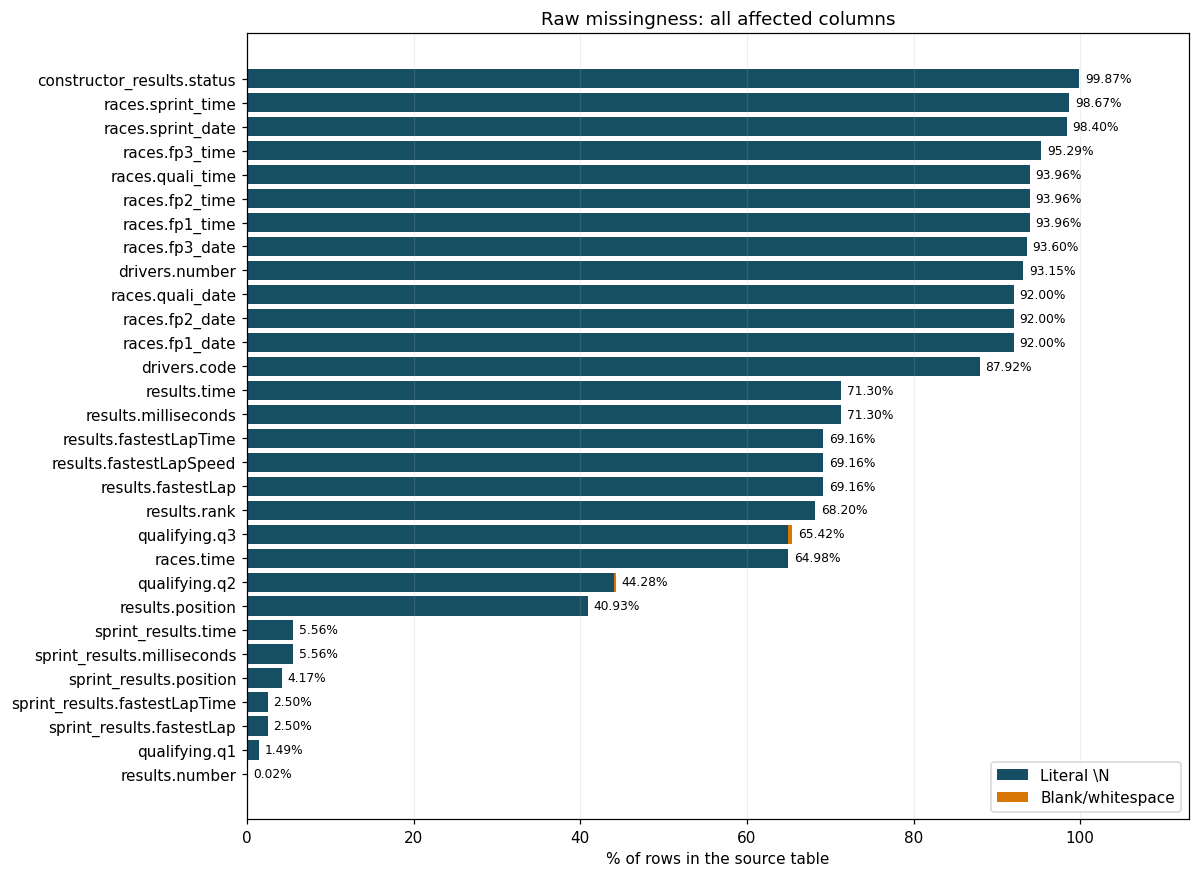

Columns with detected missingness: 30


In [5]:
missing_plot = missingness.copy().sort_values(['missing_pct', 'table', 'column'])
missing_plot['field'] = missing_plot.table + '.' + missing_plot.column
denominators = missing_plot.table.map({name: len(table) for name, table in raw.items()})
sentinel_pct = 100 * missing_plot.sentinel_count / denominators
blank_pct = 100 * missing_plot.blank_count / denominators
fig, ax = plt.subplots(figsize=(11, max(7, len(missing_plot) * 0.27)))
ax.barh(missing_plot.field, sentinel_pct, label='Literal \\N', color='#164e63')
ax.barh(missing_plot.field, blank_pct, left=sentinel_pct, label='Blank/whitespace', color='#d97706')
for y, value in enumerate(sentinel_pct + blank_pct):
    ax.text(value + 0.7, y, f'{value:.2f}%', va='center', fontsize=8)
ax.set(xlim=(0, 113), xlabel='% of rows in the source table', title='Raw missingness: all affected columns')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()
print('Columns with detected missingness:', len(missing_plot))

**1.2 Missingness as stored.** Missing values appear both as the literal sentinel `\N` and as blank strings (22 blank Q2 and 46 blank Q3 cells). `results.position` is missing in 40.9% of rows, but the target field `positionOrder` is complete, so dropping rows with a missing `position` would be wrong. Q2/Q3 gaps are largely structural (drivers knocked out in Q1/Q2), not recording errors, so they are never filled with a generic average.

In [6]:
KEYS = {'circuits': ['circuitId'],
    'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'],
    'constructors': ['constructorId'],
    'driver_standings': ['driverStandingsId'],
    'drivers': ['driverId'],
    'lap_times': ['raceId',
    'driverId',
    'lap'],
    'pit_stops': ['raceId',
    'driverId',
    'stop'],
    'qualifying': ['qualifyId'],
    'races': ['raceId'],
    'results': ['resultId'],
    'seasons': ['year'],
    'sprint_results': ['resultId'],
    'status': ['statusId']}

def missing_mask(frame):
    return frame.eq(SENTINEL) | frame.apply(lambda s: s.str.strip().eq(''))
key_rows = []
for name, keys in KEYS.items():
    df = raw[name]
    key_rows.append({'table': name,
        'key': '+'.join(keys),
        'missing_key_rows': int(missing_mask(df[keys]).any(axis=1).sum()),
        'duplicate_excess_rows': int(df.duplicated(keys).sum())})
key_audit = pd.DataFrame(key_rows)
show(key_audit)
PARENTS = {'raceId': 'races',
    'driverId': 'drivers',
    'constructorId': 'constructors',
    'circuitId': 'circuits',
    'statusId': 'status',
    'year': 'seasons'}
fk_rows = []
for name, df in raw.items():
    for col, parent in PARENTS.items():
        if col not in df or name == parent:
            continue
        miss = missing_mask(df[[col]])[col]
        orphan = ~miss & ~df[col].isin(raw[parent][col])
        fk_rows.append({'child': name,
            'column': col,
            'parent': parent,
            'missing_rows': int(miss.sum()),
            'orphan_rows': int(orphan.sum())})
fk_audit = pd.DataFrame(fk_rows)
show(fk_audit)
pair_key = ['raceId', 'driverId']
for name in ['results', 'qualifying', 'sprint_results', 'driver_standings']:
    df = raw[name]
    repeated = df.duplicated(pair_key, keep=False)
    print(name,
        ': rows in repeated driver–race groups =',
        int(repeated.sum()),
        '; excess rows =',
        int(df.duplicated(pair_key).sum()))
duplicate_results = raw['results'].loc[raw['results'].duplicated(pair_key, keep=False)]
duplicate_examples = duplicate_results.merge(raw['races'][['raceId', 'year', 'name']], on='raceId', validate='many_to_one')
print('\nFirst 16 raw rows in repeated driver–race groups (no rows removed):')
show(duplicate_examples[['raceId',
    'year',
    'name',
    'driverId',
    'resultId',
    'constructorId',
    'grid',
    'positionOrder',
    'points']].head(16))
print('\nRepeated groups by year:')
show(duplicate_examples.groupby('year').agg(rows=('resultId',
    'size'),
    distinct_drivers=('driverId',
    'nunique')).reset_index())

                table                    key  missing_key_rows  duplicate_excess_rows
             circuits              circuitId                 0                      0
  constructor_results   constructorResultsId                 0                      0
constructor_standings constructorStandingsId                 0                      0
         constructors          constructorId                 0                      0
     driver_standings      driverStandingsId                 0                      0
              drivers               driverId                 0                      0
            lap_times    raceId+driverId+lap                 0                      0
            pit_stops   raceId+driverId+stop                 0                      0
           qualifying              qualifyId                 0                      0
                races                 raceId                 0                      0
              results               resultId          

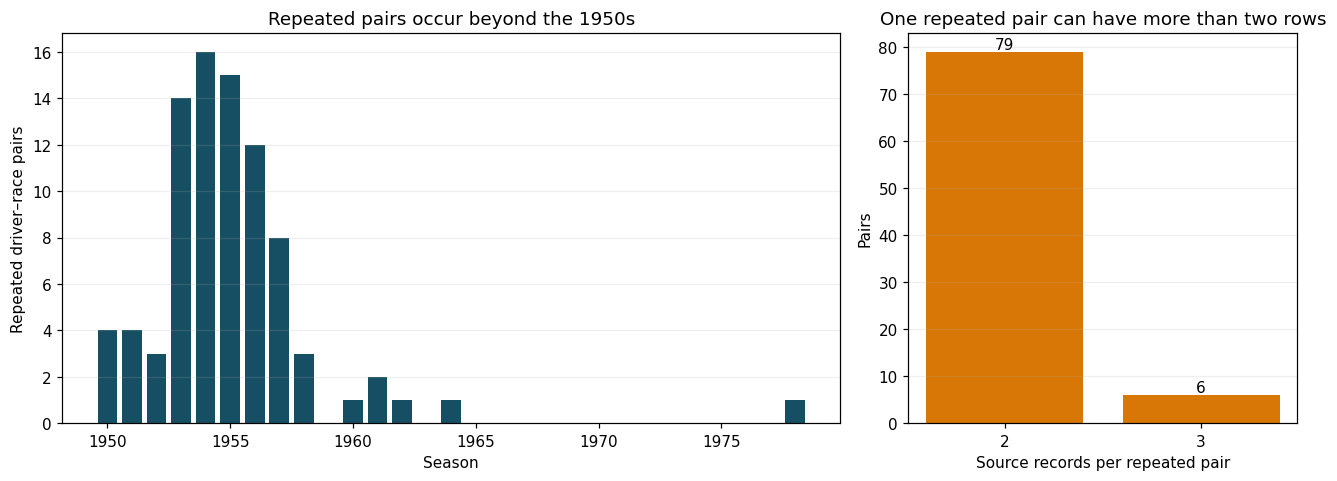

Repeated pairs: 85 | affected rows: 176 | excess rows: 91
 records_per_pair  pairs
                2     79
                3      6


In [7]:
repeat_groups = raw['results'].groupby(['raceId', 'driverId']).size().rename('source_rows').reset_index()
repeat_groups = repeat_groups.loc[repeat_groups.source_rows.gt(1)].merge(raw['races'][['raceId',
    'year']],
    on='raceId',
    validate='many_to_one')
repeat_year_counts = repeat_groups.groupby('year').size()
repeat_year_counts.index = repeat_year_counts.index.astype(int)
repeat_year_counts = repeat_year_counts.reindex(range(int(raw['races'].year.min()),
    int(repeat_groups.year.max()) + 1),
    fill_value=0)
size_counts = repeat_groups.source_rows.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [2, 1]})
axes[0].bar(repeat_year_counts.index, repeat_year_counts.values, color='#164e63')
axes[0].set(xlabel='Season', ylabel='Repeated driver–race pairs', title='Repeated pairs occur beyond the 1950s')
axes[1].bar(size_counts.index.astype(str), size_counts.values, color='#d97706')
axes[1].set(xlabel='Source records per repeated pair', ylabel='Pairs', title='One repeated pair can have more than two rows')
for i, n in enumerate(size_counts.values):
    axes[1].text(i, n + 0.5, str(n), ha='center')
for ax in axes:
    ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()
print('Repeated pairs:',
    len(repeat_groups),
    '| affected rows:',
    int(repeat_groups.source_rows.sum()),
    '| excess rows:',
    int((repeat_groups.source_rows - 1).sum()))
show(size_counts.rename_axis('records_per_pair').reset_index(name='pairs'))

**1.3 Keys and duplicates.** Every primary key is unique and non-null, and every foreign key (raceId, driverId, constructorId, circuitId, statusId, year) resolves to its parent table — no orphans. However, **85 driver–race pairs appear more than once in `results` (176 rows, 91 excess)**: 79 pairs have two rows and 6 have three. The left chart shows they are concentrated in the 1950s (shared drives, when drivers swapped cars mid-race) but continue until 1978. A unique `resultId` therefore does not guarantee the required modeling grain; Section 2 fixes this.

                table first_year last_year  races
  constructor_results       1958      2024   1060
constructor_standings       1958      2024   1061
     driver_standings       1950      2024   1125
            lap_times       1996      2024    544
            pit_stops       2011      2024    285
           qualifying       1994      2024    494
                races       1950      2024   1125
              results       1950      2024   1125
       sprint_results       2021      2024     18

Per-season coverage:
year  entries  races_with_results  qualifying_record_pct  q1_pct  q2_pct  q3_pct  races_in_races_table
1950      156                   7                   0.00    0.00    0.00    0.00                     7
1951      175                   8                   0.00    0.00    0.00    0.00                     8
1952      212                   8                   0.00    0.00    0.00    0.00                     8
1953      230                   9                   0.00    0.00  

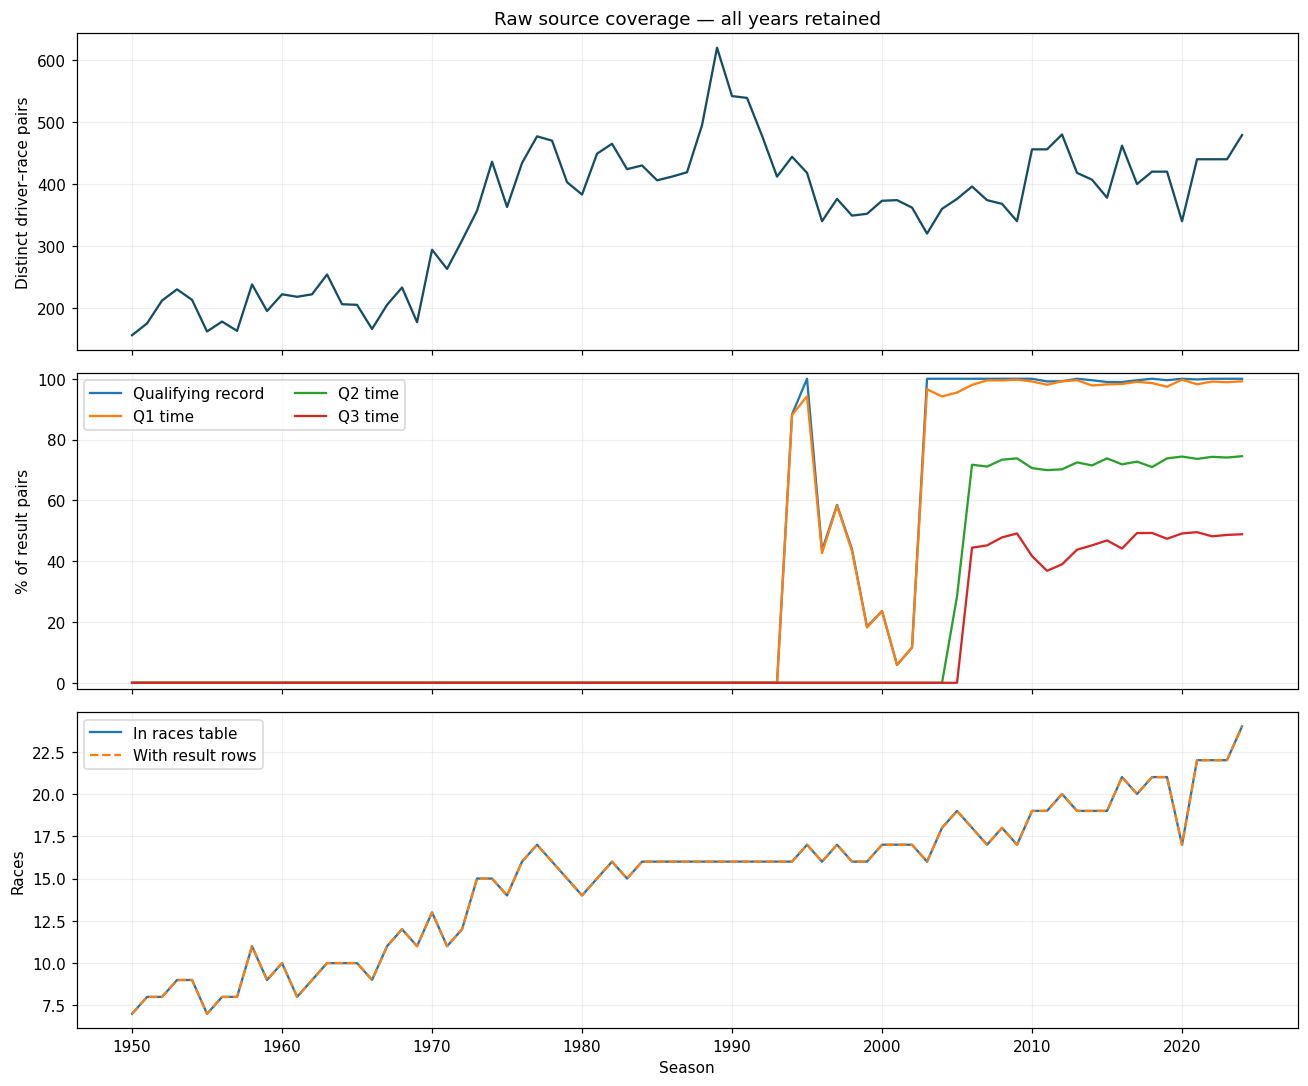

In [8]:
races = raw['races']
results = raw['results']
qualifying = raw['qualifying']
race_meta = races[['raceId', 'year', 'round', 'date', 'name']]
coverage_rows = []
for name, df in raw.items():
    if 'raceId' in df:
        linked = df[['raceId']].merge(races[['raceId', 'year']], on='raceId', how='left', validate='many_to_one')
        coverage_rows.append({'table': name,
            'first_year': linked.year.min(),
            'last_year': linked.year.max(),
            'races': df.raceId.nunique()})
show(pd.DataFrame(coverage_rows))
entry_pairs = results[pair_key].drop_duplicates()
qual_flags = qualifying[pair_key].copy()
qual_flags['has_qualifying_record'] = True
for col in ['q1', 'q2', 'q3']:
    qual_flags[f'has_{col}'] = ~missing_mask(qualifying[[col]])[col]
coverage = entry_pairs.merge(qual_flags, on=pair_key, how='left', validate='one_to_one')
coverage = coverage.merge(race_meta, on='raceId', validate='many_to_one')
flag_cols = ['has_qualifying_record', 'has_q1', 'has_q2', 'has_q3']
coverage[flag_cols] = coverage[flag_cols].eq(True)
yearly = coverage.groupby('year').agg(entries=('driverId',
    'size'),
    races_with_results=('raceId',
    'nunique'),
    qualifying_record_pct=('has_qualifying_record',
    'mean'),
    q1_pct=('has_q1',
    'mean'),
    q2_pct=('has_q2',
    'mean'),
    q3_pct=('has_q3',
    'mean')).reset_index()
for col in ['qualifying_record_pct', 'q1_pct', 'q2_pct', 'q3_pct']:
    yearly[col] = (100 * yearly[col]).round(2)
scheduled = races.groupby('year').size().rename('races_in_races_table').reset_index()
yearly = yearly.merge(scheduled, on='year', validate='one_to_one')
print('\nPer-season coverage:')
show(yearly)
print('\nRaces with no result rows:')
show(race_meta.loc[~races.raceId.isin(results.raceId)])
unmatched_qualifying = qualifying.merge(entry_pairs, on=pair_key, how='left', indicator=True, validate='one_to_one')
print('Qualifying pairs without a matching result pair:', int(unmatched_qualifying['_merge'].eq('left_only').sum()))
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
x = yearly.year.astype(int)
axes[0].plot(x, yearly.entries, color='#164e63')
axes[0].set_ylabel('Distinct driver–race pairs')
axes[0].set_title('Raw source coverage — all years retained')
for col, label in [('qualifying_record_pct',
    'Qualifying record'),
    ('q1_pct',
    'Q1 time'),
    ('q2_pct',
    'Q2 time'),
    ('q3_pct',
    'Q3 time')]:
    axes[1].plot(x, yearly[col], label=label)
axes[1].set_ylabel('% of result pairs')
axes[1].set_ylim(-2, 102)
axes[1].legend(ncol=2)
axes[2].plot(x, yearly.races_in_races_table, label='In races table')
axes[2].plot(x, yearly.races_with_results, '--', label='With result rows')
axes[2].set_ylabel('Races')
axes[2].set_xlabel('Season')
axes[2].legend()
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

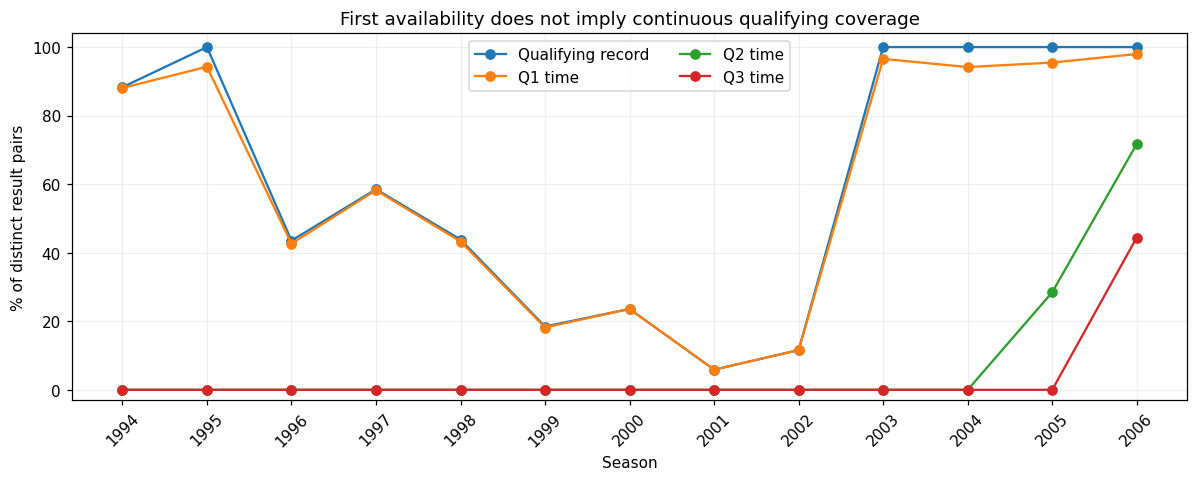

In [9]:
transition = yearly.loc[yearly.year.astype(int).between(1994, 2006)]
fig, ax = plt.subplots(figsize=(11, 4.5))
for col, label in [('qualifying_record_pct',
    'Qualifying record'),
    ('q1_pct',
    'Q1 time'),
    ('q2_pct',
    'Q2 time'),
    ('q3_pct',
    'Q3 time')]:
    ax.plot(transition.year.astype(int), transition[col], marker='o', label=label)
ax.set_xticks(transition.year.astype(int))
ax.tick_params(axis='x', rotation=45)
ax.set(ylim=(-3,
    104),
    xlabel='Season',
    ylabel='% of distinct result pairs',
    title='First availability does not imply continuous qualifying coverage')
ax.legend(ncol=2)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**1.4 Coverage over time.** Results cover 1950–2024 and every race has result rows. `qualifying` only starts in **1994** and is patchy at first (2001: 5.9% of entries, 2002: 11.6%); it is consistently ~99–100% from **2003**, and Q3 times appear from 2006. Lap times start in 1996, pit stops in 2011, sprint results in 2021. This **qualifying-coverage drift** is why qualifying-based inputs must handle missingness explicitly (Section 7) and why the training window is compared in Section 8.

Unparseable positionOrder values: 0
Non-positive positionOrder values: 0
Non-integer positionOrder values: 0
Raw podium rows: 3397 of 26759 (12.69%)
Raw grid zero rows: 1638
Unparseable grid values: 0

Status distribution among grid-zero rows:
            status  rows
   Did not qualify  1013
Did not prequalify   331
          Withdrew   164
            +1 Lap    27
          Finished    22
          Accident    20
            Injury     8
           +2 Laps     7
            Engine     6
          Excluded     6
      Disqualified     6
           Retired     3
  Collision damage     3
            Brakes     2
           Injured     2
   Safety concerns     2
         107% Rule     2
        Suspension     2
        Power Unit     2
       Fuel system     2
       Underweight     1
    Fatal accident     1
           Battery     1
      Transmission     1
           Gearbox     1
         Collision     1
         Undertray     1
        Hydraulics     1

Races with raw podium-row coun

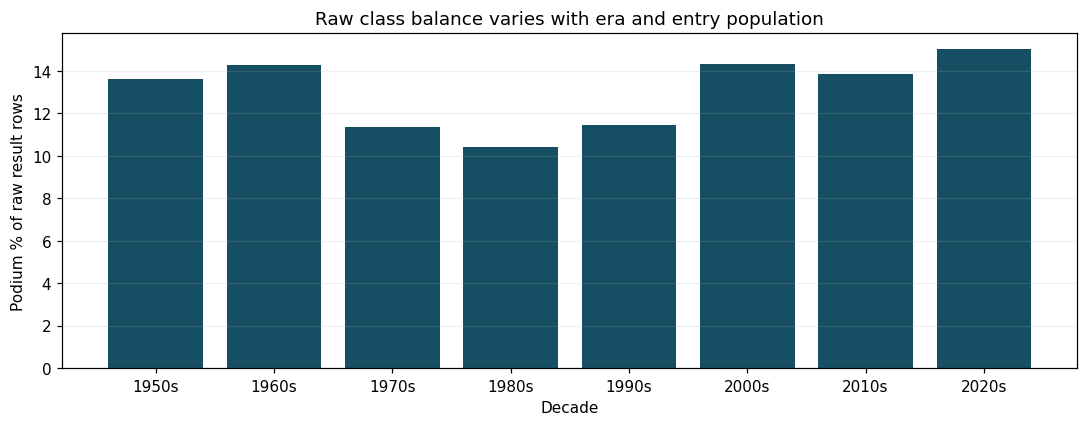


Row counts under the season boundaries used later (train ≤2019, validation 2020–2021, test 2022+):
      period  raw_rows  races  podium_rate
   2020–2021       780     39     0.150000
 2022 onward      1359     68     0.150110
through 2019     24620   1018     0.124939


In [10]:
order = pd.to_numeric(results.positionOrder, errors='coerce')
grid = pd.to_numeric(results.grid, errors='coerce')
print('Unparseable positionOrder values:', int(order.isna().sum()))
print('Non-positive positionOrder values:', int(order.le(0).sum()))
print('Non-integer positionOrder values:', int((order.notna() & order.mod(1).ne(0)).sum()))
print('Raw podium rows:', int(order.le(3).sum()), 'of', len(results), f'({100 * order.le(3).mean():.2f}%)')
print('Raw grid zero rows:', int(grid.eq(0).sum()))
print('Unparseable grid values:', int(grid.isna().sum()))
status_rows = results[['raceId', 'driverId', 'statusId', 'grid']].merge(raw['status'], on='statusId', validate='many_to_one')
print('\nStatus distribution among grid-zero rows:')
show(status_rows.loc[status_rows.grid.eq('0'), 'status'].value_counts().rename_axis('status').reset_index(name='rows'))
podium_per_race = results.assign(audit_podium=order.le(3)).groupby('raceId').audit_podium.sum()
unusual_podium = podium_per_race[podium_per_race.ne(3)].rename('raw_podium_rows').reset_index()
print('\nRaces with raw podium-row count different from three:')
show(unusual_podium.merge(race_meta, on='raceId', validate='one_to_one'))
diagnostic = results[['raceId', 'driverId']].merge(races[['raceId', 'year']], on='raceId', validate='many_to_one')
diagnostic['raw_podium'] = order.to_numpy() <= 3
diagnostic['era'] = (diagnostic.year.astype(int) // 10 * 10).astype(str) + 's'
decades = diagnostic.groupby('era').agg(raw_rows=('driverId', 'size'), podium_rate=('raw_podium', 'mean')).reset_index()
print('\nRaw target rate by decade (2020s may be partial):')
show(decades)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(decades.era, 100 * decades.podium_rate, color='#164e63')
ax.set(ylabel='Podium % of raw result rows', xlabel='Decade', title='Raw class balance varies with era and entry population')
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()
print('\nRow counts under the season boundaries used later (train ≤2019, validation 2020–2021, test 2022+):')
diagnostic['period'] = np.select([diagnostic.year.astype(int).le(2019),
    diagnostic.year.astype(int).between(2020,
    2021)],
    ['through 2019',
    '2020–2021'],
    default='2022 onward')
show(diagnostic.groupby('period').agg(raw_rows=('driverId',
    'size'),
    races=('raceId',
    'nunique'),
    podium_rate=('raw_podium',
    'mean')).reset_index())

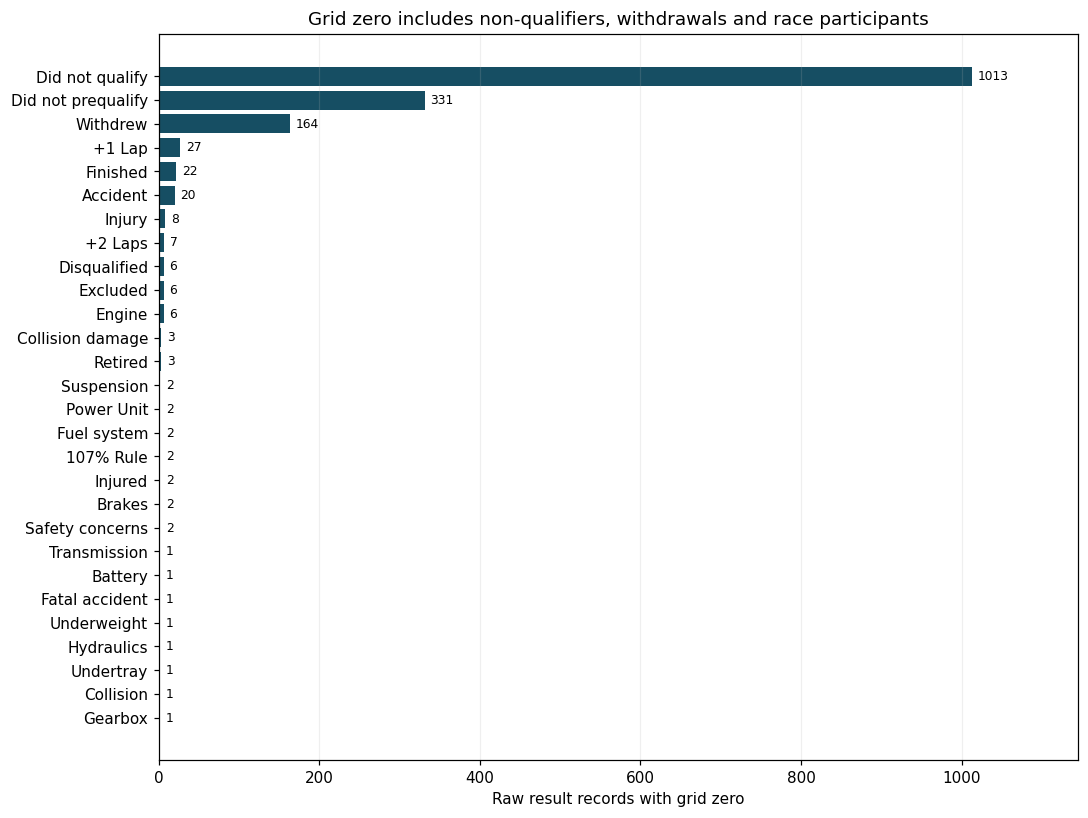

In [11]:
zero_status_counts = status_rows.loc[status_rows.grid.eq('0'), 'status'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, max(7, len(zero_status_counts) * 0.27)))
ax.barh(zero_status_counts.index, zero_status_counts.values, color='#164e63')
for i, n in enumerate(zero_status_counts.values):
    ax.text(n + 7, i, str(n), va='center', fontsize=8)
ax.set(xlim=(0,
    max(zero_status_counts) * 1.13),
    xlabel='Raw result records with grid zero',
    title='Grid zero includes non-qualifiers, withdrawals and race participants')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

**1.5 Target and grid.** `positionOrder` is complete and valid: 3,397 raw podium rows (12.7%). Eighteen early races (1950–1960) have more than three podium rows (shared drives again), so the label must be built per driver, not forced to three per race. Podiums are a minority class — an always-"no podium" model would be ~87% accurate while finding no podium finisher, which is why accuracy is not used as a metric (Section 8).

**Grid zero is not one thing:** of 1,638 grid-zero rows, 1,013 are "Did not qualify", 331 "Did not prequalify" and 164 "Withdrew", but finishers also appear. Zero is therefore treated as "no numbered grid position" with its own flag — never as a position better than pole. Status is used here only to understand the data, never as a feature.

## 2. Clean copies and create one driver–race row
All cleaning happens on copies; the raw tables are re-hashed at the end to prove they never changed.

**2.1 Sentinels and types.** Only the exact `\N` token and blank strings become missing — real zeros stay. IDs/counts become nullable integers, points/coordinates decimals, dates real dates, and lap/pit/qualifying times (`1:40.203`) numeric seconds. Every failed conversion would be logged.

**2.2 Duplicate rule — one row per (raceId, driverId).** Instead of deleting rows, we *aggregate* each driver's records into one row:
- **Label:** `podium = 1` if **any** of the driver's records in that race has `positionOrder <= 3`. A driver who shared a car that reached the podium did stand on it; choosing one row would drop that fact, and counting twice would double-count.
- **Grid / constructor:** kept only when **all** of the driver's records agree; otherwise the value is set to missing and a conflict flag is raised. Picking the row with the better finish would let the *outcome* choose a *pre-race* input — a subtle form of leakage.
- **Grid zero** stays a separate flag (`grid_zero_recorded`) and the numeric grid becomes missing.
- A mapping from every pair back to its original `resultId`s is kept, so nothing is lost.

The code cell below traces one real driver–race (Leclerc, 2023 Azerbaijan GP) across all tables before cleaning, separating pre-race fields (qualifying, grid) from post-race fields (result, points, standings, pit stops).

In [12]:
trace_race = raw['races'].loc[(raw['races'].year == '2023') & (raw['races'].name == 'Azerbaijan Grand Prix')].iloc[0]
trace_driver = raw['drivers'].loc[raw['drivers'].driverRef == 'leclerc'].iloc[0]
trace_rid, trace_did = (trace_race.raceId, trace_driver.driverId)
trace_result = raw['results'].loc[(raw['results'].raceId == trace_rid) & (raw['results'].driverId == trace_did)].iloc[0]
trace_cid = trace_result.constructorId
print('Driver:',
    trace_driver.forename,
    trace_driver.surname,
    '| race:',
    trace_rid,
    '| driver:',
    trace_did,
    '| constructor:',
    trace_cid)
for name in ['races',
    'qualifying',
    'results',
    'driver_standings',
    'constructor_standings',
    'constructor_results',
    'sprint_results',
    'pit_stops',
    'lap_times']:
    table = raw[name]
    match = table.raceId.eq(trace_rid)
    if 'driverId' in table:
        match &= table.driverId.eq(trace_did)
    elif 'constructorId' in table:
        match &= table.constructorId.eq(trace_cid)
    print(f'\n{name}: {int(match.sum())} matching rows (first 2 shown)')
    show(table.loc[match].head(2))

Driver: Charles Leclerc | race: 1101 | driver: 844 | constructor: 6

races: 1 matching rows (first 2 shown)
raceId year round circuitId                  name       date     time                                                      url   fp1_date fp1_time   fp2_date fp2_time fp3_date fp3_time quali_date quali_time sprint_date sprint_time
  1101 2023     4        73 Azerbaijan Grand Prix 2023-04-30 11:00:00 https://en.wikipedia.org/wiki/2023_Azerbaijan_Grand_Prix 2023-04-28 09:30:00 2023-04-29 09:30:00       \N       \N 2023-04-28   13:00:00  2023-04-29    13:30:00

qualifying: 1 matching rows (first 2 shown)
qualifyId raceId driverId constructorId number position       q1       q2       q3
     9693   1101      844             6     16        1 1:41.269 1:41.037 1:40.203

results: 1 matching rows (first 2 shown)
resultId raceId driverId constructorId number grid position positionText positionOrder points laps    time milliseconds fastestLap rank fastestLapTime fastestLapSpeed statusId
 

In [13]:
clean = {}
missing_audit_rows = []
conversion_issue_rows = []
dtype_rows = []
int_names = {'raceId',
    'driverId',
    'constructorId',
    'circuitId',
    'statusId',
    'resultId',
    'qualifyId',
    'constructorResultsId',
    'constructorStandingsId',
    'driverStandingsId',
    'year',
    'round',
    'number',
    'grid',
    'position',
    'positionOrder',
    'laps',
    'lap',
    'stop',
    'fastestLap',
    'rank',
    'wins',
    'milliseconds',
    'alt'}
float_names = {'points', 'lat', 'lng', 'fastestLapSpeed'}
date_names = {'date', 'dob', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date'}
clock_names = {'fp1_time', 'fp2_time', 'fp3_time', 'quali_time', 'sprint_time'}

def record_conversion_issues(name, col, original, converted, kind):
    failed = original.notna() & converted.isna()
    for idx in original.index[failed]:
        conversion_issue_rows.append({'table': name,
            'row_index': int(idx),
            'column': col,
            'raw_value': str(original.at[idx]),
            'issue': kind})

def duration_seconds(series):

    def one(value):
        if pd.isna(value):
            return pd.NA
        import re
        if not re.fullmatch('\\d+(?:\\.\\d+)?|\\d+:\\d{1,2}(?:\\.\\d+)?|\\d+:\\d{1,2}:\\d{1,2}(?:\\.\\d+)?', str(value)):
            return pd.NA
        parts = [float(x) for x in str(value).split(':')]
        if len(parts) > 1 and parts[-1] >= 60:
            return pd.NA
        if len(parts) == 3 and parts[-2] >= 60:
            return pd.NA
        return sum((value * 60 ** power for power, value in enumerate(reversed(parts))))
    return series.map(one).astype('Float64')
for name, original in raw.items():
    table = original.astype('string').copy(deep=True)
    mask = original.eq(SENTINEL) | original.apply(lambda col: col.str.strip().eq(''))
    table = table.mask(mask, pd.NA)
    for col in original:
        missing_audit_rows.append({'table': name,
            'column': col,
            'raw_sentinel_count': int(original[col].eq(SENTINEL).sum()),
            'raw_blank_count': int(original[col].str.strip().eq('').sum()),
            'expected_missing': int(mask[col].sum()),
            'clean_missing': int(table[col].isna().sum())})
        original_type = str(table[col].dtype)
        if col in int_names:
            parsed = pd.to_numeric(table[col], errors='coerce')
            noninteger = parsed.notna() & parsed.mod(1).ne(0)
            parsed = parsed.mask(noninteger)
            record_conversion_issues(name, col, table[col], parsed, 'invalid integer')
            table[col] = parsed.astype('Int64')
        elif col in float_names:
            parsed = pd.to_numeric(table[col], errors='coerce').astype('Float64')
            parsed = parsed.mask(parsed.notna() & ~np.isfinite(parsed))
            record_conversion_issues(name, col, table[col], parsed, 'invalid finite number')
            table[col] = parsed
        elif col in date_names:
            parsed = pd.to_datetime(table[col], format='%Y-%m-%d', errors='coerce')
            record_conversion_issues(name, col, table[col], parsed, 'invalid date')
            table[col] = parsed
        dtype_rows.append({'table': name, 'column': col, 'before': 'raw string', 'after': str(table[col].dtype)})
    duration_cols = []
    if name == 'qualifying':
        duration_cols += ['q1', 'q2', 'q3']
    if name == 'lap_times':
        duration_cols += ['time']
    if name == 'pit_stops':
        duration_cols += ['duration']
    if 'fastestLapTime' in table:
        duration_cols += ['fastestLapTime']
    for col in duration_cols:
        parsed = duration_seconds(table[col])
        record_conversion_issues(name, col, table[col], parsed, 'invalid duration')
        table[col + '_seconds'] = parsed
    if 'milliseconds' in table:
        table['elapsed_seconds_from_ms'] = (table.milliseconds / 1000).astype('Float64')
    clocks = [col for col in table if col in clock_names or (col == 'time' and name in ['races', 'pit_stops'])]
    for col in clocks:
        valid = table[col].str.fullmatch('(?:[01]\\d|2[0-3]):[0-5]\\d:[0-5]\\d', na=False)
        parts = table[col].where(valid).str.split(':', expand=True)
        seconds = (pd.to_numeric(parts[0],
            errors='coerce') * 3600 + pd.to_numeric(parts[1],
            errors='coerce') * 60 + pd.to_numeric(parts[2],
            errors='coerce')).astype('Float64')
        record_conversion_issues(name, col, table[col], seconds, 'invalid clock time')
        table[col + '_seconds_since_midnight'] = seconds
    if name in ['results', 'sprint_results']:
        table['grid_raw'] = table['grid'].copy()
        table['grid_zero_recorded'] = table.grid.eq(0).astype('boolean')
        table['grid_position'] = table.grid.where(table.grid.gt(0)).astype('Int64')
    clean[name] = table
missing_audit = pd.DataFrame(missing_audit_rows)
conversion_issues = pd.DataFrame(conversion_issue_rows, columns=['table', 'row_index', 'column', 'raw_value', 'issue'])
type_audit = pd.DataFrame(dtype_rows)
before_after_counts = pd.DataFrame([{'table': name,
    'raw_rows': len(raw[name]),
    'clean_rows': len(table),
    'raw_columns': len(raw[name].columns),
    'clean_columns': len(table.columns)} for name,
    table in clean.items()])
show(before_after_counts)
print('\nMissingness totals (original columns only):')
show(missing_audit[['raw_sentinel_count',
    'raw_blank_count',
    'expected_missing',
    'clean_missing']].sum().to_frame('cells').reset_index(names='measure'))
print('\nConversion issues:')
show(conversion_issues)
print('\nExample types:')
show(type_audit.loc[type_audit.table.isin(['results', 'races'])].head(24))
print('\nLeclerc qualifying durations:')
show(clean['qualifying'].loc[(clean['qualifying'].raceId == int(trace_rid)) & (clean['qualifying'].driverId == int(trace_did)),
    ['position',
    'q1',
    'q1_seconds',
    'q2_seconds',
    'q3_seconds']])

                table  raw_rows  clean_rows  raw_columns  clean_columns
             circuits        77          77            9              9
  constructor_results     12625       12625            5              5
constructor_standings     13391       13391            7              7
         constructors       212         212            5              5
     driver_standings     34863       34863            7              7
              drivers       861         861            9              9
            lap_times    589081      589081            6              8
            pit_stops     11371       11371            7             10
           qualifying     10494       10494            9             12
                races      1125        1125           18             24
              results     26759       26759           18             23
              seasons        75          75            2              2
       sprint_results       360         360           16        

**Observed:** all 14 tables keep their row counts. Exactly 160,076 sentinels plus 68 blanks became 160,144 missing cells, with **zero conversion failures**. Added columns are unit conversions (e.g. Leclerc's Q3 `1:40.203` → 100.203 s), not new rows.

In [14]:
cr = clean['results']
pair_cols = ['raceId', 'driverId']
source_result_map = cr[pair_cols + ['resultId']].copy()
grouped = cr.assign(record_podium=cr.positionOrder.le(3)).groupby(pair_cols, sort=True)
driver_race = grouped.agg(source_record_count=('resultId',
    'size'),
    podium_record_count=('record_podium',
    'sum'),
    best_position_order=('positionOrder',
    'min')).reset_index()
driver_race['extra_record_count'] = driver_race.source_record_count - 1
driver_race['podium'] = driver_race.podium_record_count.gt(0).astype('Int64')
for source, dest, flag in [('grid',
    'grid_raw',
    'grid_conflict'),
    ('constructorId',
    'constructorId',
    'constructor_conflict')]:
    values = cr.groupby(pair_cols)[source]
    distinct = values.nunique(dropna=False)
    agreed = values.first().where(distinct.eq(1)).rename(dest)
    agreement = pd.concat([agreed, distinct.gt(1).rename(flag)], axis=1).reset_index()
    driver_race = driver_race.merge(agreement, on=pair_cols, validate='one_to_one')
zero_flags = cr.groupby(pair_cols).grid_zero_recorded.any().rename('grid_zero_recorded').reset_index()
driver_race = driver_race.merge(zero_flags, on=pair_cols, validate='one_to_one')
driver_race['grid_position'] = driver_race.grid_raw.where(driver_race.grid_raw.gt(0)).astype('Int64')
qual_pairs = clean['qualifying'][pair_cols].copy()
qual_pairs['qualifying_record_present'] = True
driver_race = driver_race.merge(qual_pairs, on=pair_cols, how='left', validate='one_to_one')
driver_race['qualifying_record_present'] = driver_race.qualifying_record_present.eq(True)
repeated = driver_race.source_record_count.gt(1)
summary_counts = pd.DataFrame([{'measure': 'raw result rows',
    'count': len(cr)},
    {'measure': 'unique driver–race rows',
    'count': len(driver_race)},
    {'measure': 'single-record pairs',
    'count': int((~repeated).sum())},
    {'measure': 'repeated pairs',
    'count': int(repeated.sum())},
    {'measure': 'extra source rows consolidated in view only',
    'count': int(driver_race.extra_record_count.sum())},
    {'measure': 'grid conflicts',
    'count': int(driver_race.grid_conflict.sum())},
    {'measure': 'constructor conflicts',
    'count': int(driver_race.constructor_conflict.sum())},
    {'measure': 'raw podium records',
    'count': int(cr.positionOrder.le(3).sum())},
    {'measure': 'unique positive driver–race labels',
    'count': int(driver_race.podium.sum())}])
show(summary_counts)
print('\nMoss example — conflicting grid, agreed constructor, one positive label:')
show(cr.loc[(cr.raceId == 746) & (cr.driverId == 475),
    ['resultId',
    'raceId',
    'driverId',
    'grid',
    'constructorId',
    'positionOrder']])
show(driver_race.loc[(driver_race.raceId == 746) & (driver_race.driverId == 475)])
show(source_result_map.loc[(source_result_map.raceId == 746) & (source_result_map.driverId == 475)])
print('\nCanonical view dtypes:')
print(driver_race.dtypes.to_string())

                                    measure  count
                            raw result rows  26759
                    unique driver–race rows  26668
                        single-record pairs  26583
                             repeated pairs     85
extra source rows consolidated in view only     91
                             grid conflicts     81
                      constructor conflicts     16
                         raw podium records   3397
         unique positive driver–race labels   3395

Moss example — conflicting grid, agreed constructor, one positive label:
 resultId  raceId  driverId  grid  constructorId  positionOrder
    18083     746       475     1            170             17
    22372     746       475     8            170              3
 raceId  driverId  source_record_count  podium_record_count  best_position_order  extra_record_count  podium  grid_raw  grid_conflict  constructorId  constructor_conflict  grid_zero_recorded  grid_position  qualifying_record

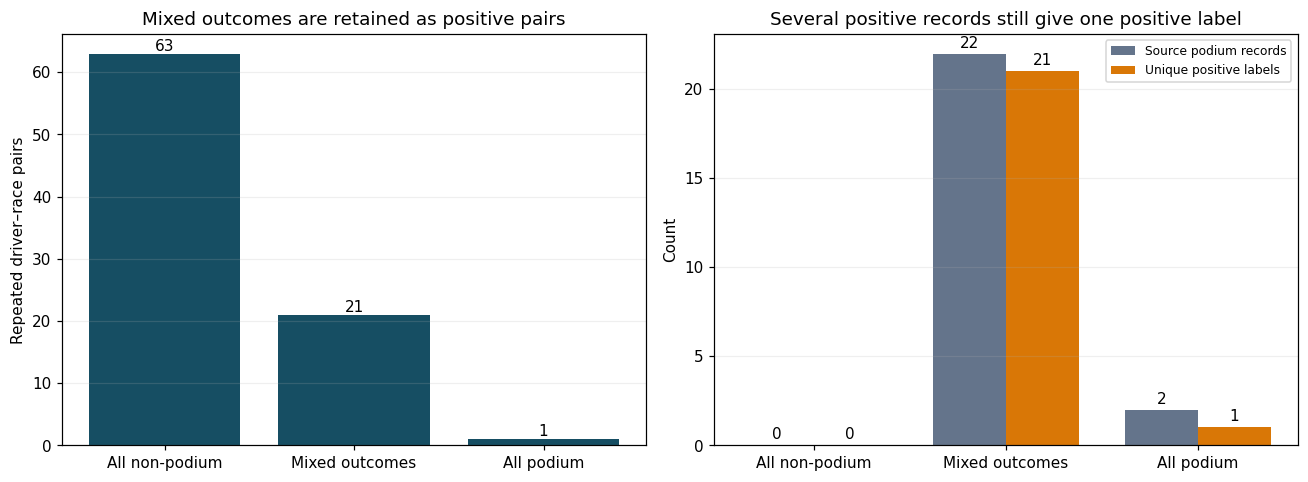

outcome_pattern  pairs  source_podium_records  unique_positive_labels
 All non-podium     63                      0                       0
 Mixed outcomes     21                     22                      21
     All podium      1                      2                       1


In [15]:
repeat_outcomes = driver_race.loc[driver_race.source_record_count.gt(1)].copy()
repeat_outcomes['outcome_pattern'] = np.select([repeat_outcomes.podium_record_count.eq(0).to_numpy(dtype=bool),
    repeat_outcomes.podium_record_count.eq(repeat_outcomes.source_record_count).to_numpy(dtype=bool)],
    ['All non-podium',
    'All podium'],
    default='Mixed outcomes')
pattern_order = ['All non-podium', 'Mixed outcomes', 'All podium']
patterns = repeat_outcomes.groupby('outcome_pattern').agg(pairs=('raceId',
    'size'),
    source_podium_records=('podium_record_count',
    'sum'),
    unique_positive_labels=('podium',
    'sum')).reindex(pattern_order)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(patterns.index, patterns.pairs, color='#164e63')
axes[0].set(ylabel='Repeated driver–race pairs', title='Mixed outcomes are retained as positive pairs')
for i, n in enumerate(patterns.pairs):
    axes[0].text(i, n + 0.5, str(n), ha='center')
x = np.arange(len(patterns))
width = 0.38
axes[1].bar(x - width / 2, patterns.source_podium_records, width, label='Source podium records', color='#64748b')
axes[1].bar(x + width / 2, patterns.unique_positive_labels, width, label='Unique positive labels', color='#d97706')
axes[1].set_xticks(x)
axes[1].set_xticklabels(patterns.index)
axes[1].set(ylabel='Count', title='Several positive records still give one positive label')
axes[1].legend(fontsize=8)
for i, row in enumerate(patterns.itertuples()):
    axes[1].text(i - width / 2, row.source_podium_records + 0.35, str(row.source_podium_records), ha='center')
    axes[1].text(i + width / 2, row.unique_positive_labels + 0.35, str(row.unique_positive_labels), ha='center')
for ax in axes:
    ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()
show(patterns.reset_index())

**Observed:** 26,759 result rows become **26,668 unique driver–race rows** (85 repeated pairs consolidated, 91 extra rows mapped, not deleted). 81 pairs have conflicting grids and 16 conflicting constructors; both are left missing rather than guessed. The 3,397 podium records become 3,395 positive labels: 21 repeated pairs had mixed podium/non-podium records and keep label 1, and two pairs had two podium records each but count once. Example: Moss in race 746 has grids 1 and 8 across two cars → podium kept, grid left missing (`grid_conflict=True`).

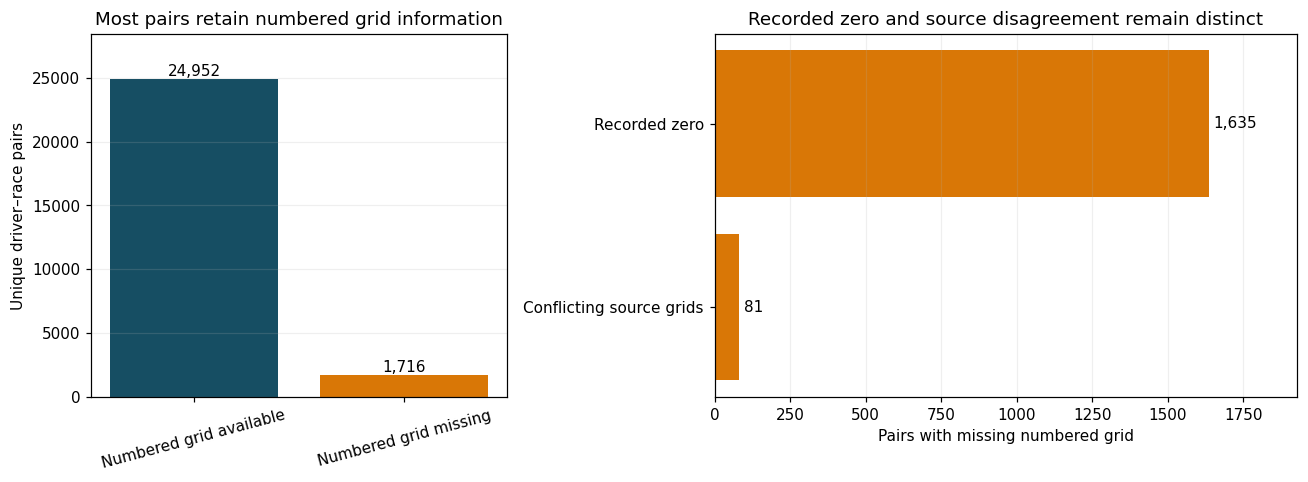

                  state  pairs
Numbered grid available  24952
  Numbered grid missing   1716
                  reason  pairs
Conflicting source grids     81
           Recorded zero   1635


In [16]:
grid_known = driver_race.grid_position.notna()
missing_grid_pairs = driver_race.loc[~grid_known].copy()
missing_grid_pairs['reason'] = np.select([(missing_grid_pairs.grid_conflict & missing_grid_pairs.grid_zero_recorded).to_numpy(dtype=bool),
    missing_grid_pairs.grid_conflict.to_numpy(dtype=bool),
    missing_grid_pairs.grid_zero_recorded.to_numpy(dtype=bool)],
    ['Conflict plus recorded zero',
    'Conflicting source grids',
    'Recorded zero'],
    default='Other unavailable grid')
reason_counts = missing_grid_pairs.reason.value_counts().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [1, 1.4]})
availability = pd.Series([int(grid_known.sum()),
    int((~grid_known).sum())],
    index=['Numbered grid available',
    'Numbered grid missing'])
axes[0].bar(availability.index, availability.values, color=['#164e63', '#d97706'])
axes[0].set(ylabel='Unique driver–race pairs', title='Most pairs retain numbered grid information')
axes[0].tick_params(axis='x', rotation=15)
for i, n in enumerate(availability.values):
    axes[0].text(i, n + 250, f'{n:,}', ha='center')
axes[0].set_ylim(0, max(availability) * 1.14)
axes[1].barh(reason_counts.index, reason_counts.values, color='#d97706')
axes[1].set(xlim=(0,
    max(reason_counts) * 1.18),
    xlabel='Pairs with missing numbered grid',
    title='Recorded zero and source disagreement remain distinct')
for i, n in enumerate(reason_counts.values):
    axes[1].text(n + 15, i, f'{n:,}', va='center')
axes[0].grid(axis='y', alpha=0.2)
axes[1].grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()
show(availability.rename_axis('state').reset_index(name='pairs'))
show(reason_counts.rename_axis('reason').reset_index(name='pairs'))

**Observed:** 24,952 pairs keep a numbered grid. The 1,716 without one split into 1,635 recorded zeros and 81 within-driver conflicts — two different reasons, kept as different flags.

In [17]:
review_rows = []

def add_reviews(name, mask, issue, column, value_col=None):
    table = clean[name]
    key_cols = KEYS[name]
    for idx, row in table.loc[mask].iterrows():
        review_rows.append({'table': name,
            'row_index': int(idx),
            'source_key': ';'.join((f'{key}={row[key]}' for key in key_cols)),
            'column': column,
            'value': str(row[value_col or column]),
            'issue': issue,
            'resolution': 'preserved; flagged by automated checks; contextual cause unresolved'})
duration_comparisons = []
for name, col in [('lap_times', 'time_seconds'), ('pit_stops', 'duration_seconds')]:
    table = clean[name]
    both = table[col].notna() & table.milliseconds.notna()
    mismatch = both & (table[col] * 1000).round().ne(table.milliseconds)
    duration_comparisons.append({'table': name,
        'compared_rows': int(both.sum()),
        'millisecond_mismatches': int(mismatch.sum())})
    add_reviews(name, mismatch, 'parsed duration disagrees with milliseconds', col)
for name, table in clean.items():
    for col in table:
        if col.endswith('_seconds') or col == 'elapsed_seconds_from_ms':
            bad = table[col].notna() & (table[col].lt(0) | ~np.isfinite(table[col]))
            add_reviews(name, bad, 'invalid negative/non-finite duration', col)
    if 'grid' in table:
        add_reviews(name, table.grid.lt(0).fillna(False), 'negative grid', 'grid')
add_reviews('pit_stops',
    clean['pit_stops'].duration_seconds.gt(300).fillna(False),
    'long pit duration >300s; review trigger only',
    'duration_seconds')
review_queue = pd.DataFrame(review_rows,
    columns=['table',
    'row_index',
    'source_key',
    'column',
    'value',
    'issue',
    'resolution'])
duration_comparisons = pd.DataFrame(duration_comparisons)
show(duration_comparisons)
print('\nReview queue counts:')
show(review_queue.groupby(['table', 'issue']).size().reset_index(name='rows'))
print('\nThree longest preserved pit durations:')
show(clean['pit_stops'].nlargest(3,
    'duration_seconds')[['raceId',
    'driverId',
    'stop',
    'lap',
    'duration',
    'duration_seconds',
    'milliseconds']])
print('\nBaku altitude remains unchanged:')
show(clean['circuits'].loc[clean['circuits'].circuitRef.eq('baku'), ['name', 'alt']])

    table  compared_rows  millisecond_mismatches
lap_times         589081                       0
pit_stops          11371                       0

Review queue counts:
    table                                        issue  rows
pit_stops long pit duration >300s; review trigger only   478

Three longest preserved pit durations:
 raceId  driverId  stop  lap  duration  duration_seconds  milliseconds
   1083       840     1    1 51:09.017          3069.017       3069017
   1083        20     1    1 51:07.301          3067.301       3067301
   1083       854     1    1 51:05.174          3065.174       3065174

Baku altitude remains unchanged:
             name  alt
Baku City Circuit   -7


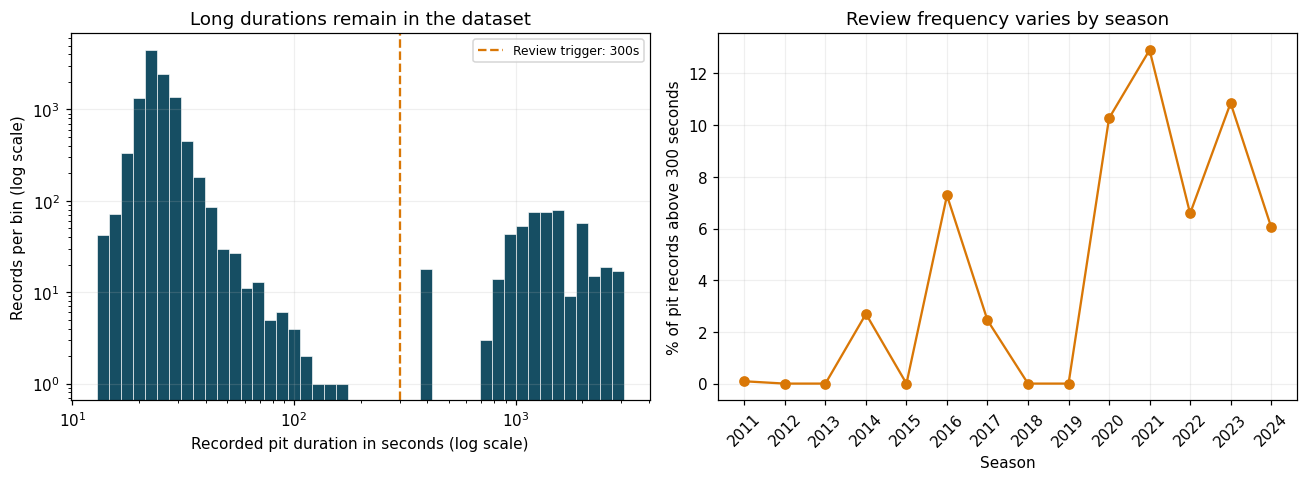

Pit records above the trigger: 478 of 11371
 year  records  review_records  review_pct
 2011     1114               1    0.089767
 2012      946               0         0.0
 2013      951               0         0.0
 2014      816              22    2.696078
 2015      741               0         0.0
 2016      989              72    7.280081
 2017      694              17    2.449568
 2018      536               0         0.0
 2019      650               0         0.0
 2020      594              61    10.26936
 2021      798             103   12.907268
 2022      805              53    6.583851
 2023      912              99   10.855263
 2024      825              50    6.060606


In [18]:
pit_plot = clean['pit_stops'][['raceId',
    'duration_seconds']].merge(clean['races'][['raceId',
    'year']],
    on='raceId',
    validate='many_to_one')
pit_values = pit_plot.duration_seconds.dropna().to_numpy(dtype=float)
pit_plot['over_review_trigger'] = pit_plot.duration_seconds.gt(300)
review_year = pit_plot.groupby('year').agg(records=('raceId',
    'size'),
    review_records=('over_review_trigger',
    'sum')).reset_index()
review_year['review_pct'] = 100 * review_year.review_records / review_year.records
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(pit_values,
    bins=np.geomspace(pit_values.min(),
    pit_values.max(),
    45),
    color='#164e63',
    edgecolor='white',
    linewidth=0.4)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].axvline(300, color='#d97706', linestyle='--', label='Review trigger: 300s')
axes[0].set(xlabel='Recorded pit duration in seconds (log scale)',
    ylabel='Records per bin (log scale)',
    title='Long durations remain in the dataset')
axes[0].legend(fontsize=8)
axes[1].plot(review_year.year.astype(int), review_year.review_pct, marker='o', color='#d97706')
axes[1].set(xlabel='Season', ylabel='% of pit records above 300 seconds', title='Review frequency varies by season')
axes[1].set_xticks(review_year.year.astype(int))
axes[1].tick_params(axis='x', rotation=45)
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Pit records above the trigger:', int(review_year.review_records.sum()), 'of', len(pit_plot))
show(review_year)

**Suspicious values were inspected with automated checks and preserved.** All 589,081 parsed lap times and 11,371 pit-stop durations agree with their millisecond columns after conversion to millisecond precision. There are 478 pit stops longer than 300 seconds, including the three approximately 51-minute records at race 1083. These are unusual values, not confirmed errors: agreement between two duration representations does not independently establish the incident's cause. The 300-second threshold is only a review trigger; no pit time is deleted or capped.

Baku's recorded altitude remains −7 m. A negative altitude is not intrinsically invalid, and this dataset supplies no independent replacement value. The source value is retained without claiming that displaying it verifies its geographical accuracy. Pit-stop outcomes are used for this audit only and are excluded from model inputs.

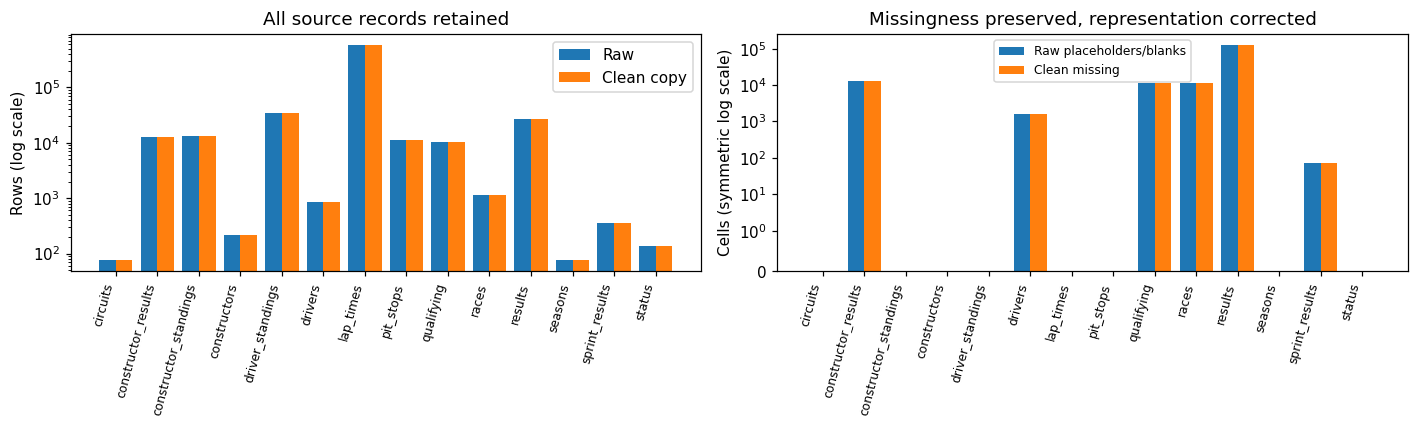

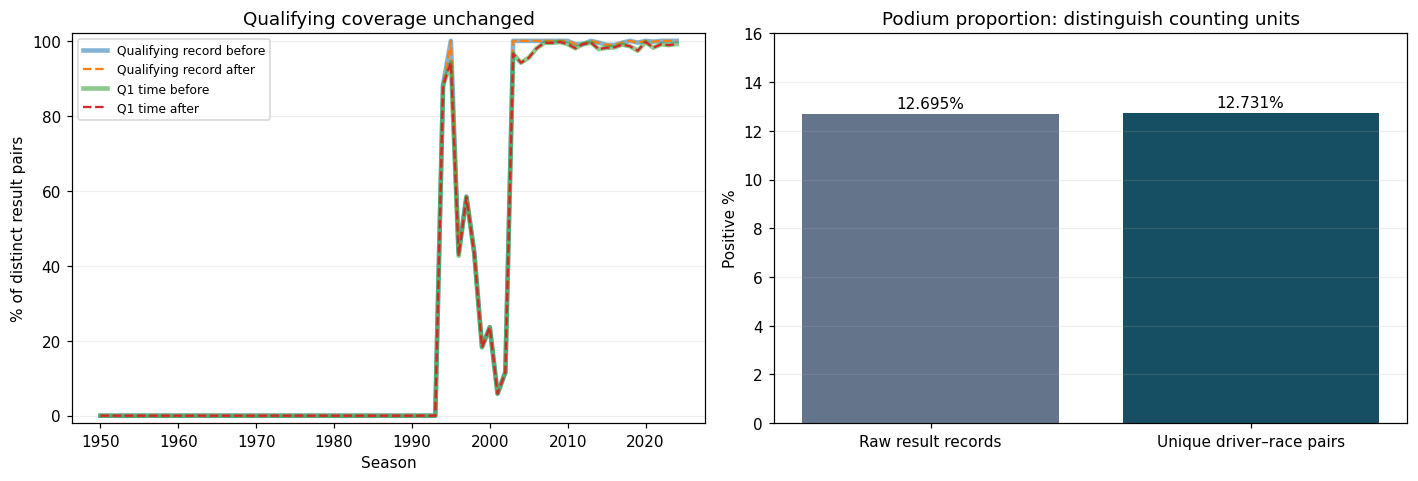

Before/after qualifying availability agrees for all seasons, including Q2 and Q3.
Raw positive records: 3397 / 26759
Unique positive pairs: 3395 / 26668
Null numbered grids: 1716 | pairs with recorded zero: 1635 | conflicting grids: 81


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(before_after_counts))
width = 0.4
axes[0].bar(x - width / 2, before_after_counts.raw_rows, width, label='Raw')
axes[0].bar(x + width / 2, before_after_counts.clean_rows, width, label='Clean copy')
axes[0].set_yscale('log')
axes[0].set_ylabel('Rows (log scale)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(before_after_counts.table, rotation=75, ha='right', fontsize=8)
axes[0].set_title('All source records retained')
axes[0].legend()
missing_totals = missing_audit.groupby('table')[['expected_missing', 'clean_missing']].sum()
x2 = np.arange(len(missing_totals))
axes[1].bar(x2 - width / 2, missing_totals.expected_missing, width, label='Raw placeholders/blanks')
axes[1].bar(x2 + width / 2, missing_totals.clean_missing, width, label='Clean missing')
axes[1].set_yscale('symlog', linthresh=1)
axes[1].set_ylabel('Cells (symmetric log scale)')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(missing_totals.index, rotation=75, ha='right', fontsize=8)
axes[1].set_title('Missingness preserved, representation corrected')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
old_qual = raw['qualifying'][pair_cols].copy()
new_qual = clean['qualifying'][pair_cols].astype(str).copy()
for col in ['q1', 'q2', 'q3']:
    old_qual[col + '_available'] = ~(raw['qualifying'][col].eq(SENTINEL) | raw['qualifying'][col].str.strip().eq(''))
    new_qual[col + '_available'] = clean['qualifying'][col + '_seconds'].notna().to_numpy()
old_qual['record_present'] = True
new_qual['record_present'] = True
base = raw['results'][pair_cols].drop_duplicates().merge(raw['races'][['raceId',
    'year']],
    on='raceId',
    validate='many_to_one')
coverage_by_stage = {}
for label, qual in [('Before', old_qual), ('After', new_qual)]:
    joined = base.merge(qual, on=pair_cols, how='left', validate='one_to_one')
    flags = ['record_present', 'q1_available', 'q2_available', 'q3_available']
    joined[flags] = joined[flags].eq(True)
    coverage_by_stage[label] = joined.groupby('year')[flags].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for col, label in [('record_present', 'Qualifying record'), ('q1_available', 'Q1 time')]:
    axes[0].plot(coverage_by_stage['Before'].index.astype(int),
        coverage_by_stage['Before'][col],
        label=label + ' before',
        linewidth=3,
        alpha=0.55)
    axes[0].plot(coverage_by_stage['After'].index.astype(int), coverage_by_stage['After'][col], '--', label=label + ' after')
axes[0].set(title='Qualifying coverage unchanged', xlabel='Season', ylabel='% of distinct result pairs', ylim=(-2, 102))
axes[0].legend(fontsize=8)
rates = [100 * cr.positionOrder.le(3).mean(), 100 * driver_race.podium.mean()]
axes[1].bar(['Raw result records', 'Unique driver–race pairs'], rates, color=['#64748b', '#164e63'])
axes[1].set(title='Podium proportion: distinguish counting units', ylabel='Positive %', ylim=(0, 16))
for i, rate in enumerate(rates):
    axes[1].text(i, rate + 0.25, f'{rate:.3f}%', ha='center')
for ax in axes:
    ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()
print('Before/after qualifying availability agrees for all seasons, including Q2 and Q3.')
print('Raw positive records:', int(cr.positionOrder.le(3).sum()), '/', len(cr))
print('Unique positive pairs:', int(driver_race.podium.sum()), '/', len(driver_race))
print('Null numbered grids:',
    int(driver_race.grid_position.isna().sum()),
    '| pairs with recorded zero:',
    int(driver_race.grid_zero_recorded.sum()),
    '| conflicting grids:',
    int(driver_race.grid_conflict.sum()))

**Before/after EDA:** row counts and the amount of missing information are identical before and after cleaning — only the representation changed (`\N` → proper missing). Qualifying coverage curves overlap exactly. The podium rate moves from 12.695% (per raw record) to 12.731% (per unique driver–race) only because the counting unit changed; this is the class balance the model actually sees.

In [20]:
# Use ordinary pandas dtypes for the later joins, matching the original CSV reloads.
# This conversion changes representation, not any cleaning or eligibility rule.
analysis_tables = {}
for name, frame in clean.items():
    frame = frame.copy()
    for column in frame:
        dtype = str(frame[column].dtype)
        if dtype.startswith('datetime64'):
            frame[column] = frame[column].dt.strftime('%Y-%m-%d')
        elif dtype in ['Int64', 'Float64']:
            target_dtype = 'float64' if frame[column].isna().any() or dtype == 'Float64' else 'int64'
            frame[column] = frame[column].astype(target_dtype)
        elif dtype == 'boolean':
            frame[column] = frame[column].astype(bool)
        elif dtype == 'string':
            frame[column] = frame[column].astype(object).where(frame[column].notna(), np.nan)
    analysis_tables[name] = frame
analysis_driver_race = driver_race.copy()
for column in analysis_driver_race.select_dtypes(include='number'):
    analysis_driver_race[column] = analysis_driver_race[column].astype(
        'float64' if analysis_driver_race[column].isna().any() else 'int64')
assert len(driver_race) == 26668 and not driver_race.duplicated(['raceId', 'driverId']).any()

## 3. Data question 1 — front-row conversion by circuit
**Question:** which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014 hybrid era?

**Joins:** unique driver–race view → `races` (year, circuit) → `circuits` (name) → `qualifying` (position). **Grain:** one driver–race pair. **Front row = recorded starting grid 1–2**, not qualifying 1–2, because penalties can move a driver between qualifying and the grid (checked explicitly below).

**Edge case — shared front-row slots:** in early seasons (1951–1964) some grid slots are attached to two or three different drivers in the original results. Consolidating per driver can *hide* this (one driver's grid becomes missing, the other looks unique). We therefore audit every original grid-1/2 slot and keep a pair only when exactly one driver owns its slot; alternative population rules are kept as a sensitivity check.

**Uncertainty:** every circuit is shown with its sample size and a 95% Wilson interval (small samples like 2/2 = 100% are common). Era changes are compared only on circuits that appear in both eras, with an exploratory whole-race bootstrap.

In [21]:
q1_analysis = driver_race.merge(clean['races'][['raceId',
    'year',
    'round',
    'date',
    'circuitId',
    'name']].rename(columns={'name': 'race_name'}),
    on='raceId',
    how='left',
    validate='many_to_one',
    indicator='race_link')
q1_analysis = q1_analysis.merge(clean['circuits'][['circuitId',
    'name',
    'country']].rename(columns={'name': 'circuit_name'}),
    on='circuitId',
    how='left',
    validate='many_to_one',
    indicator='circuit_link')
q1_analysis = q1_analysis.merge(clean['qualifying'][['raceId',
    'driverId',
    'position']].rename(columns={'position': 'qualifying_position'}),
    on=['raceId',
    'driverId'],
    how='left',
    validate='one_to_one',
    indicator='qualifying_link')
q1_analysis['era'] = np.where(q1_analysis.year.lt(2014), 'Before 2014', '2014 onward')
q1_frontrow = q1_analysis.loc[q1_analysis.grid_position.isin([1, 2])].copy()
q1_denominators = q1_analysis.groupby('era').agg(all_driver_race_pairs=('driverId',
    'size'),
    numbered_grid_available=('grid_position',
    'count'),
    grid_conflict_pairs=('grid_conflict',
    'sum'),
    recorded_zero_pairs=('grid_zero_recorded',
    'sum')).reset_index()
print('Joined analysis rows:', len(q1_analysis), '| recorded grid 1–2 pairs:', len(q1_frontrow))
show(q1_denominators)
print('\nLeft-join reconciliation:')
for col in ['race_link', 'circuit_link', 'qualifying_link']:
    print(col, q1_analysis[col].value_counts().to_dict())

Joined analysis rows: 26668 | recorded grid 1–2 pairs: 2234
        era  all_driver_race_pairs  numbered_grid_available  grid_conflict_pairs  recorded_zero_pairs
2014 onward                   4626                     4547                    0                   79
Before 2014                  22042                    20405                   81                 1556

Left-join reconciliation:
race_link {'both': 26668, 'left_only': 0, 'right_only': 0}
circuit_link {'both': 26668, 'left_only': 0, 'right_only': 0}
qualifying_link {'left_only': 16174, 'both': 10494, 'right_only': 0}


### 3.1 Qualifying position versus starting grid
The question asks us to distinguish the two. Where both are recorded (1994 onward), we compare them for every pair and check how podium conversion differs between "qualified on the front row" and "started on the front row".

Grid 1–2 pairs that also have a qualifying position: 986 | qualifying position differs from grid: 49
        era  front_row_pairs  qualifying_differs
2014 onward              454                  36
Before 2014              532                  13
All pairs with both recorded: grid differs from qualifying in 2422 of 10407
                              group  pairs  podiums  podium_rate_pct
      Qualified 1–2 and started 1–2    950      669        70.421053
Qualified 1–2, started further back     36       11        30.555556
          Qualified 3+, started 1–2     36       23        63.888889


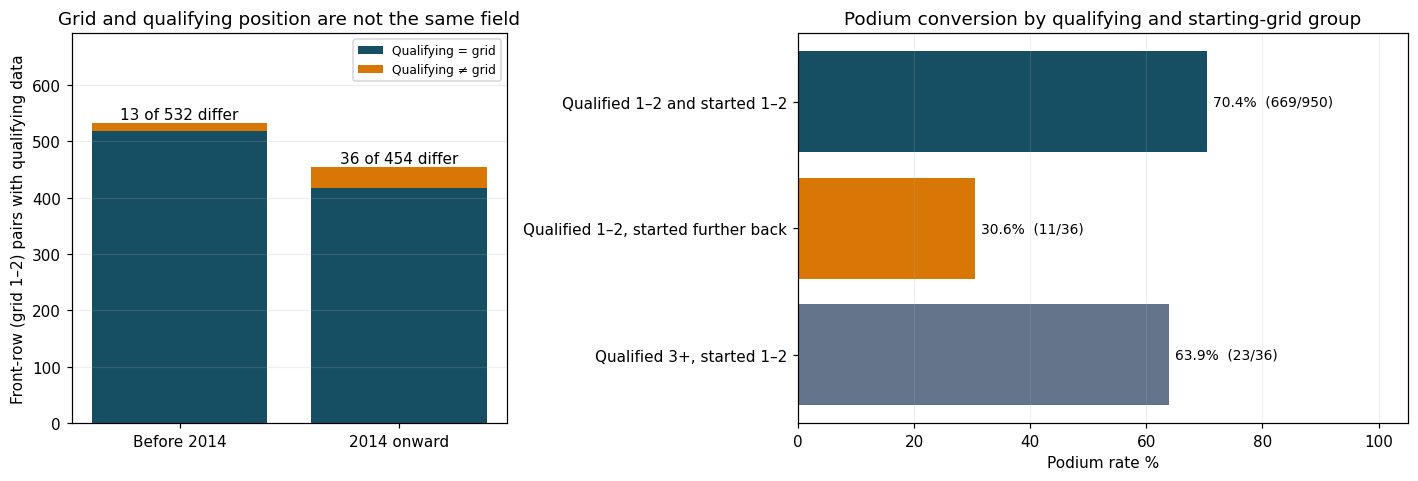

In [22]:
qg_pairs = q1_analysis.loc[q1_analysis.qualifying_position.notna() & q1_analysis.grid_position.notna()].copy()
qg_pairs['qualified_front_row'] = qg_pairs.qualifying_position.le(2)
qg_pairs['started_front_row'] = qg_pairs.grid_position.le(2)
qg_front = qg_pairs.loc[qg_pairs.started_front_row]
qg_differs = qg_front.qualifying_position.ne(qg_front.grid_position)
print('Grid 1–2 pairs that also have a qualifying position:', len(qg_front),
      '| qualifying position differs from grid:', int(qg_differs.sum()))
show(qg_front.assign(differs=qg_differs).groupby('era').agg(
    front_row_pairs=('differs', 'size'), qualifying_differs=('differs', 'sum')).reset_index())
print('All pairs with both recorded: grid differs from qualifying in',
      int(qg_pairs.qualifying_position.ne(qg_pairs.grid_position).sum()), 'of', len(qg_pairs))

qg_groups = {
    'Qualified 1–2 and started 1–2': qg_pairs.qualified_front_row & qg_pairs.started_front_row,
    'Qualified 1–2, started further back': qg_pairs.qualified_front_row & ~qg_pairs.started_front_row,
    'Qualified 3+, started 1–2': ~qg_pairs.qualified_front_row & qg_pairs.started_front_row,
}
qg_summary = pd.DataFrame([{'group': name, 'pairs': int(mask.sum()),
                            'podiums': int(qg_pairs.loc[mask, 'podium'].sum())} for name, mask in qg_groups.items()])
qg_summary['podium_rate_pct'] = 100 * qg_summary.podiums / qg_summary.pairs
show(qg_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1, 1.4]})
era_counts = qg_front.assign(differs=qg_differs).groupby('era').differs.agg(['size', 'sum']).reindex(['Before 2014', '2014 onward'])
axes[0].bar(era_counts.index, era_counts['size'] - era_counts['sum'], color='#164e63', label='Qualifying = grid')
axes[0].bar(era_counts.index, era_counts['sum'], bottom=era_counts['size'] - era_counts['sum'], color='#d97706', label='Qualifying ≠ grid')
for i, (n, k) in enumerate(zip(era_counts['size'], era_counts['sum'])):
    axes[0].text(i, n + 8, f'{k} of {n} differ', ha='center')
axes[0].set(ylabel='Front-row (grid 1–2) pairs with qualifying data', title='Grid and qualifying position are not the same field')
axes[0].legend(loc='upper right', fontsize=8)
axes[0].set_ylim(0, era_counts['size'].max() * 1.3)
bars = axes[1].barh(qg_summary.group, qg_summary.podium_rate_pct, color=['#164e63', '#d97706', '#64748b'])
for bar, row in zip(bars, qg_summary.itertuples()):
    axes[1].text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
                 f'{row.podium_rate_pct:.1f}%  ({row.podiums}/{row.pairs})', va='center', fontsize=9)
axes[1].invert_yaxis()
axes[1].set(xlim=(0, 105), xlabel='Podium rate %', title='Podium conversion by qualifying and starting-grid group')
for ax in axes:
    ax.grid(axis='x' if ax is axes[1] else 'y', alpha=0.2)
plt.tight_layout()
plt.show()

In [23]:
qg_definition_audit = qg_front.assign(
    exact_position_differs=qg_front.qualifying_position.ne(qg_front.grid_position),
    qualified_outside_front_row=qg_front.qualifying_position.gt(2),
).groupby('era').agg(
    front_row_starters_with_qualifying=('driverId', 'size'),
    exact_position_differs=('exact_position_differs', 'sum'),
    qualified_outside_front_row=('qualified_outside_front_row', 'sum'),
).reset_index()
show(qg_definition_audit)
assert qg_front.qualifying_position.gt(2).sum() == qg_summary.loc[
    qg_summary.group.eq('Qualified 3+, started 1–2'), 'pairs'].iloc[0]

        era  front_row_starters_with_qualifying  exact_position_differs  qualified_outside_front_row
2014 onward                                 454                      36                           27
Before 2014                                 532                      13                            9


**Observed:** 49 of 986 recorded front-row starters with qualifying data have a qualifying position different from their grid position: 13/532 before 2014 and 36/454 from 2014. A P1-to-P2 swap counts as a difference even though the driver remains on the front row. The table also shows that **36 of the 986 qualified outside P1–P2**, including **27/454 from 2014**; the extra audit below reports both definitions separately.

Across all 10,407 pairs with both fields, the exact positions differ 2,422 times (23%). Drivers recorded as qualifying and starting on the front row have 70.4% podium conversion, compared with 30.6% (11/36) for qualifying on the front row and starting further back, and 63.9% (23/36) for qualifying outside it and starting on it. These are descriptive associations, not isolated effects of penalties. Grid and qualifying therefore remain separate fields.

Source slot conflicts: 12 | races: 11
 raceId  year                     name  grid_position  source_drivers  reconciled_view_drivers  distinct_recorded_entries
    828  1951        French Grand Prix              1               2                        0                          1
    824  1952       Italian Grand Prix              1               2                        2                          2
    824  1952       Italian Grand Prix              2               2                        2                          2
    809  1953         Indianapolis 500              2               2                        1                          1
    814  1953        German Grand Prix              1               2                        0                          1
    815  1953         Swiss Grand Prix              1               2                        0                          1
    792  1955     Argentine Grand Prix              1               3                        1              

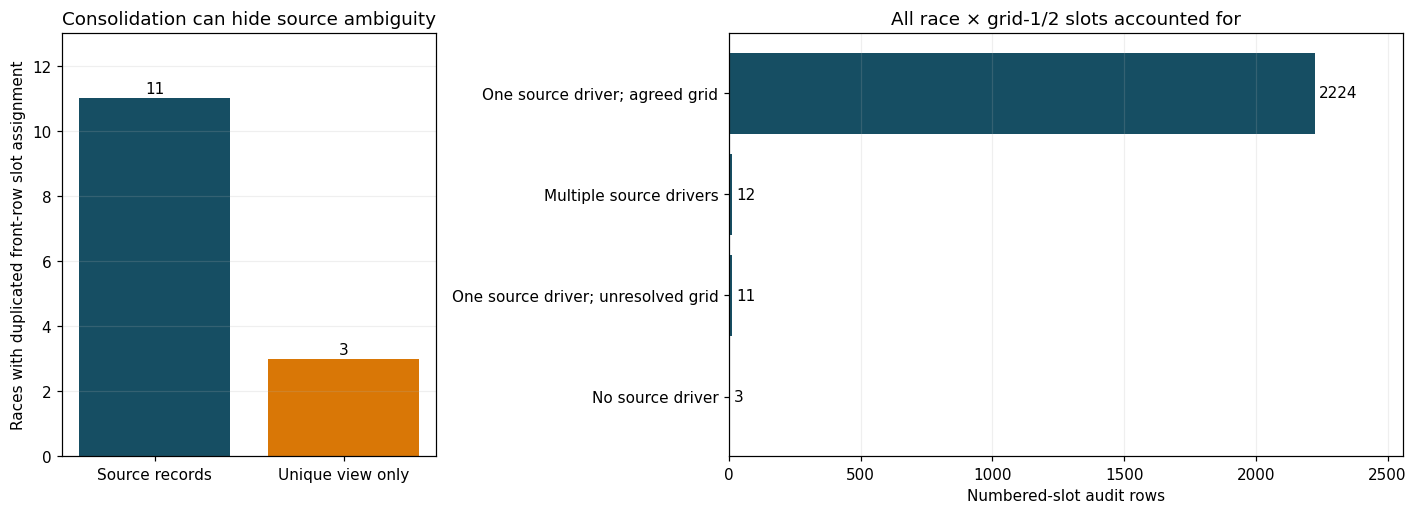

In [24]:
source_front = clean['results'].loc[clean['results'].grid.isin([1, 2])].copy()
q1_source_owner_map = source_front[['raceId',
    'grid',
    'driverId']].drop_duplicates().rename(columns={'grid': 'grid_position'})
q1_source_slots = source_front.groupby(['raceId',
    'grid']).agg(source_records=('resultId',
    'size'),
    source_drivers=('driverId',
    'nunique'),
    distinct_car_numbers=('number',
    'nunique'),
    distinct_constructors=('constructorId',
    'nunique')).reset_index()
q1_source_slots = q1_source_slots.rename(columns={'grid': 'grid_position'})
source_entries = source_front[['raceId', 'grid', 'constructorId', 'number']].drop_duplicates()
entry_counts = source_entries.groupby(['raceId',
    'grid']).size().rename('distinct_recorded_entries').reset_index().rename(columns={'grid': 'grid_position'})
q1_source_slots = q1_source_slots.merge(entry_counts, on=['raceId', 'grid_position'], validate='one_to_one')
view_slots = q1_frontrow.groupby(['raceId', 'grid_position']).size().rename('reconciled_view_drivers').reset_index()
q1_all_slots = clean['races'][['raceId',
    'year',
    'name']].merge(pd.DataFrame({'grid_position': pd.Series([1,
    2],
    dtype='Int64')}),
    how='cross')
q1_all_slots = q1_all_slots.merge(q1_source_slots, on=['raceId', 'grid_position'], how='left', validate='one_to_one')
q1_all_slots = q1_all_slots.merge(view_slots, on=['raceId', 'grid_position'], how='left', validate='one_to_one')
slot_count_cols = ['source_records',
    'source_drivers',
    'distinct_car_numbers',
    'distinct_constructors',
    'distinct_recorded_entries',
    'reconciled_view_drivers']
q1_all_slots[slot_count_cols] = q1_all_slots[slot_count_cols].fillna(0).astype('Int64')
q1_all_slots['slot_state'] = np.select([q1_all_slots.source_drivers.eq(0).to_numpy(dtype=bool),
    q1_all_slots.source_drivers.gt(1).to_numpy(dtype=bool),
    q1_all_slots.reconciled_view_drivers.eq(0).to_numpy(dtype=bool)],
    ['No source driver recorded',
    'Multiple source drivers',
    'Single source driver, grid unresolved'],
    default='Single source driver, grid reconciled')
q1_source_ambiguities = q1_all_slots.loc[q1_all_slots.source_drivers.gt(1)].copy()
q1_source_ambiguous_races = set(q1_source_ambiguities.raceId)
q1_visible_ambiguous_races = set(q1_all_slots.loc[q1_all_slots.reconciled_view_drivers.gt(1), 'raceId'])
print('Source slot conflicts:', len(q1_source_ambiguities), '| races:', len(q1_source_ambiguous_races))
show(q1_source_ambiguities[['raceId',
    'year',
    'name',
    'grid_position',
    'source_drivers',
    'reconciled_view_drivers',
    'distinct_recorded_entries']].sort_values(['year',
    'raceId',
    'grid_position']))
print('\nSource-conflict visibility after within-driver reconciliation:')
q1_visibility = q1_source_ambiguities.groupby('reconciled_view_drivers').size().rename('source_conflicting_slots').reset_index()
show(q1_visibility)
print('\nEvery expected slot classified (no invented driver rows):')
q1_slot_state_counts = q1_all_slots.slot_state.value_counts().rename_axis('slot_state').reset_index(name='slots')
show(q1_slot_state_counts)
example_race = 792
example_source = clean['results'].loc[(clean['results'].raceId == example_race) & clean['results'].driverId.isin(q1_source_owner_map.loc[(q1_source_owner_map.raceId == example_race) & q1_source_owner_map.grid_position.eq(1),
    'driverId'])]
print('\nHidden ambiguity example, race 792: all source records for its recorded grid-1 drivers')
show(example_source[['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'positionOrder']])
print('\nTheir reconciled view rows:')
show(driver_race.loc[(driver_race.raceId == example_race) & driver_race.driverId.isin(example_source.driverId),
    ['raceId',
    'driverId',
    'grid_raw',
    'grid_conflict',
    'source_record_count',
    'podium']])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1, 1.8]})
axes[0].bar(['Source records',
    'Unique view only'],
    [len(q1_source_ambiguous_races),
    len(q1_visible_ambiguous_races)],
    color=['#164e63',
    '#d97706'])
axes[0].set(ylabel='Races with duplicated front-row slot assignment',
    title='Consolidation can hide source ambiguity',
    ylim=(0,
    13))
for i, n in enumerate([len(q1_source_ambiguous_races), len(q1_visible_ambiguous_races)]):
    axes[0].text(i, n + 0.15, str(n), ha='center')
display_states = q1_slot_state_counts.sort_values('slots')
short_names = {'No source driver recorded': 'No source driver',
    'Multiple source drivers': 'Multiple source drivers',
    'Single source driver, grid unresolved': 'One source driver; unresolved grid',
    'Single source driver, grid reconciled': 'One source driver; agreed grid'}
axes[1].barh(display_states.slot_state.map(short_names), display_states.slots, color='#164e63')
for i, n in enumerate(display_states.slots):
    axes[1].text(n + 15, i, str(n), va='center')
axes[1].set(xlabel='Numbered-slot audit rows',
    title='All race × grid-1/2 slots accounted for',
    xlim=(0,
    max(display_states.slots) * 1.15))
axes[0].grid(axis='y', alpha=0.2)
axes[1].grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

**Observed:** the original results attach **12 front-row slots in 11 races** to more than one driver, but after per-driver consolidation only 4 slots in 3 races still look ambiguous — the rest are hidden (e.g. race 792: grid 1 belongs to three drivers, two of whom end up with a missing grid, so the third *looks* like the unique pole sitter). All 2,250 race × slot combinations are accounted for. This is why the slot audit must use the original records, not only the cleaned view.

                          policy  driver_race_pairs  races_represented  pairs_not_used
              All recorded pairs               2234               1123               0
  Omit 3 visibly ambiguous races               2224               1120              10
   Omit 11 source-conflict races               2215               1113              19
Chosen: unambiguous source slots               2224               1122              10
Complete source-consistent races               2204               1102              30

Provisional era rates:
                          policy         era  pairs  podium_pairs  conversion_pct
              All recorded pairs 2014 onward    454           345       75.991189
              All recorded pairs Before 2014   1780          1000       56.179775
  Omit 3 visibly ambiguous races 2014 onward    454           345       75.991189
  Omit 3 visibly ambiguous races Before 2014   1770           995       56.214689
   Omit 11 source-conflict races 2014 onward

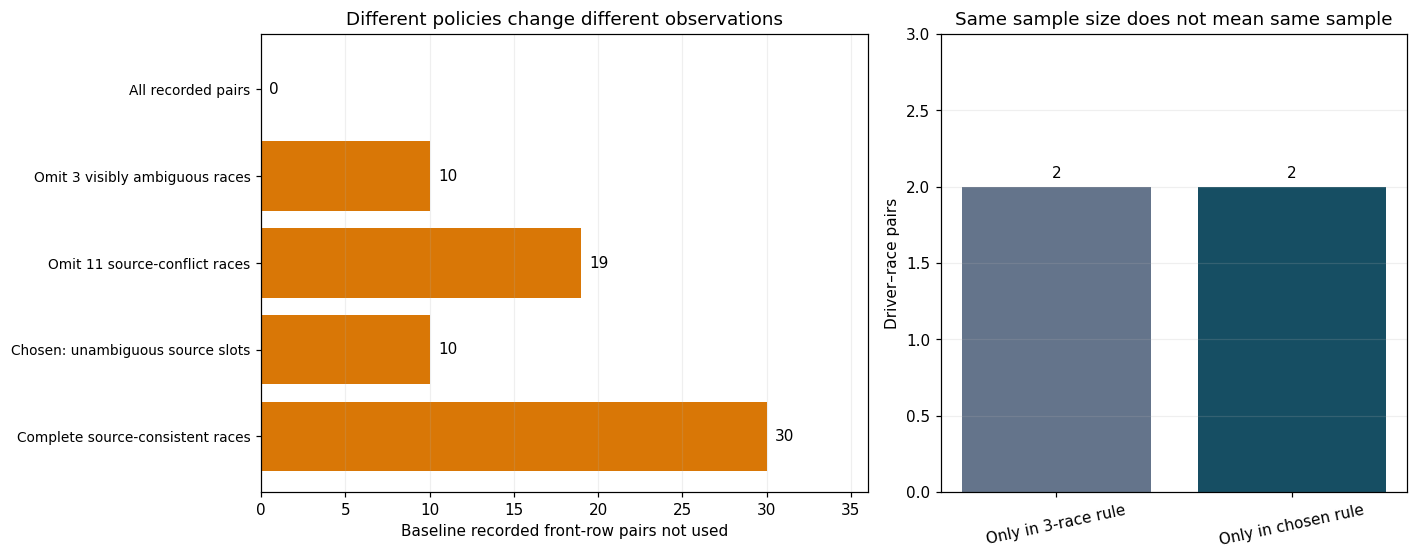

In [25]:
q1_frontrow_checked = q1_frontrow.merge(q1_all_slots[['raceId',
    'grid_position',
    'source_drivers',
    'reconciled_view_drivers',
    'slot_state']],
    on=['raceId',
    'grid_position'],
    how='left',
    validate='many_to_one')
q1_complete_races = set(q1_all_slots.groupby('raceId').slot_state.agg(lambda values: values.eq('Single source driver, grid reconciled').all()).loc[lambda x: x].index)
q1_candidates = {'All recorded pairs': q1_frontrow_checked.copy(),
    'Omit 3 visibly ambiguous races': q1_frontrow_checked.loc[~q1_frontrow_checked.raceId.isin(q1_visible_ambiguous_races)].copy(),
    'Omit 11 source-conflict races': q1_frontrow_checked.loc[~q1_frontrow_checked.raceId.isin(q1_source_ambiguous_races)].copy(),
    'Chosen: unambiguous source slots': q1_frontrow_checked.loc[q1_frontrow_checked.source_drivers.eq(1)].copy(),
    'Complete source-consistent races': q1_frontrow_checked.loc[q1_frontrow_checked.raceId.isin(q1_complete_races)].copy()}
q1_policy_rates = []
q1_policy_counts = []
q1_policy_circuits = []
for policy, table in q1_candidates.items():
    q1_policy_counts.append({'policy': policy,
        'driver_race_pairs': len(table),
        'races_represented': table.raceId.nunique(),
        'pairs_not_used': len(q1_frontrow_checked) - len(table)})
    for era, part in table.groupby('era'):
        q1_policy_rates.append({'policy': policy,
            'era': era,
            'pairs': len(part),
            'podium_pairs': int(part.podium.sum()),
            'conversion_pct': 100 * part.podium.mean()})
    t = table.groupby(['circuitId',
        'circuit_name',
        'era']).agg(pairs=('podium',
        'size'),
        podium_pairs=('podium',
        'sum')).reset_index()
    t['conversion_pct'] = 100 * t.podium_pairs / t.pairs
    t['policy'] = policy
    q1_policy_circuits.append(t)
q1_policy_rates = pd.DataFrame(q1_policy_rates)
q1_policy_counts = pd.DataFrame(q1_policy_counts)
q1_policy_circuits = pd.concat(q1_policy_circuits, ignore_index=True)
show(q1_policy_counts)
print('\nProvisional era rates:')
show(q1_policy_rates)

def pair_set(table):
    return set(map(tuple, table[['raceId', 'driverId']].to_numpy()))
old_pairs = pair_set(q1_candidates['Omit 3 visibly ambiguous races'])
proposed_pairs = pair_set(q1_candidates['Chosen: unambiguous source slots'])
q1_membership_difference = []
for label, keys in [('Only in 3-race rule',
    old_pairs - proposed_pairs),
    ('Only in chosen rule',
    proposed_pairs - old_pairs)]:
    membership = pd.Series([tuple(row) in keys for row in q1_frontrow_checked[['raceId',
        'driverId']].to_numpy()],
        index=q1_frontrow_checked.index)
    part = q1_frontrow_checked.loc[membership, ['raceId', 'driverId', 'year', 'race_name', 'grid_position', 'podium']].copy()
    part['membership'] = label
    q1_membership_difference.append(part)
q1_membership_difference = pd.concat(q1_membership_difference, ignore_index=True)
print('\nEqual era rates can hide different pair identities:')
show(q1_membership_difference)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.3, 1]})
positions = np.arange(len(q1_policy_counts))
axes[0].barh(positions, q1_policy_counts.pairs_not_used, color='#d97706')
axes[0].set_yticks(positions)
axes[0].set_yticklabels(q1_policy_counts.policy, fontsize=9)
axes[0].invert_yaxis()
axes[0].set(xlabel='Baseline recorded front-row pairs not used',
    title='Different policies change different observations',
    xlim=(0,
    max(q1_policy_counts.pairs_not_used) * 1.2))
for i, n in enumerate(q1_policy_counts.pairs_not_used):
    axes[0].text(n + 0.5, i, str(n), va='center')
axes[1].bar(['Only in 3-race rule',
    'Only in chosen rule'],
    [len(old_pairs - proposed_pairs),
    len(proposed_pairs - old_pairs)],
    color=['#64748b',
    '#164e63'])
axes[1].set(ylabel='Driver–race pairs', title='Same sample size does not mean same sample', ylim=(0, 3))
axes[1].tick_params(axis='x', rotation=12)
for i, n in enumerate([len(old_pairs - proposed_pairs), len(proposed_pairs - old_pairs)]):
    axes[1].text(i, n + 0.06, str(n), ha='center')
axes[0].grid(axis='x', alpha=0.2)
axes[1].grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

**Observed:** the population rules differ by at most 30 of 2,234 pairs and the era rates barely move (≈56.2% before 2014, ≈76.0% from 2014). The chosen rule — keep a pair when its slot has exactly one source driver — has the same size (2,224) as the naïve "omit 3 visibly ambiguous races" rule, yet **different members**: it removes two pairs whose slot is truly shared and keeps two clear pairs that the naïve rule dropped. Equal sample sizes do not mean equal samples.

In [26]:
q1_population_ledger = q1_analysis.merge(q1_all_slots[['raceId',
    'grid_position',
    'source_drivers',
    'slot_state']],
    on=['raceId',
    'grid_position'],
    how='left',
    validate='many_to_one')
frontrow_known = q1_population_ledger.grid_position.isin([1, 2])
single_source_owner = q1_population_ledger.source_drivers.eq(1).fillna(False)
q1_population_ledger['included_in_primary_q1'] = (frontrow_known & single_source_owner).astype(bool)
q1_population_ledger['population_reason'] = np.select([q1_population_ledger.grid_conflict.to_numpy(dtype=bool),
    q1_population_ledger.grid_zero_recorded.fillna(False).to_numpy(dtype=bool),
    (q1_population_ledger.grid_position.notna() & ~frontrow_known).to_numpy(dtype=bool),
    (frontrow_known & ~single_source_owner).to_numpy(dtype=bool),
    q1_population_ledger.included_in_primary_q1.to_numpy(dtype=bool)],
    ['Driver–race grid conflict',
    'Recorded zero: no numbered grid',
    'Numbered grid outside 1–2',
    'Front-row slot has multiple source drivers',
    'Included: agreed front-row grid and unique source driver'],
    default='Other unavailable grid')
q1_primary = q1_population_ledger.loc[q1_population_ledger.included_in_primary_q1].copy()
q1_population_counts = q1_population_ledger.population_reason.value_counts().rename_axis('reason').reset_index(name='pairs')
q1_primary_summary = q1_primary.groupby('era').agg(pairs=('podium',
    'size'),
    podium_pairs=('podium',
    'sum'),
    races=('raceId',
    'nunique')).reset_index()
q1_primary_summary['conversion_pct'] = 100 * q1_primary_summary.podium_pairs / q1_primary_summary.pairs
q1_primary_excluded_frontrow = q1_population_ledger.loc[frontrow_known & ~q1_population_ledger.included_in_primary_q1].copy()
print('All unique driver-race pairs:', len(q1_population_ledger))
print('Recorded front-row candidates:', int(frontrow_known.sum()))
print('Primary analysis pairs:', len(q1_primary))
print('Front-row candidates excluded for source ambiguity:', len(q1_primary_excluded_frontrow))
show(q1_population_counts)
print('\nPrimary era summary (descriptive):')
show(q1_primary_summary)
print('\nEvery front-row candidate excluded by the source-slot rule:')
show(q1_primary_excluded_frontrow[['raceId',
    'driverId',
    'year',
    'race_name',
    'grid_position',
    'source_drivers',
    'population_reason']].sort_values(['year',
    'raceId',
    'driverId']))

All unique driver-race pairs: 26668
Recorded front-row candidates: 2234
Primary analysis pairs: 2224
Front-row candidates excluded for source ambiguity: 10
                                                  reason  pairs
                               Numbered grid outside 1–2  22718
Included: agreed front-row grid and unique source driver   2224
                         Recorded zero: no numbered grid   1635
                               Driver–race grid conflict     81
              Front-row slot has multiple source drivers     10

Primary era summary (descriptive):
        era  pairs  podium_pairs  races  conversion_pct
2014 onward    454           345    228       75.991189
Before 2014   1770           995    894       56.214689

Every front-row candidate excluded by the source-slot rule:
 raceId  driverId  year                race_name  grid_position  source_drivers                          population_reason
    824       475  1952       Italian Grand Prix              1         

In [27]:
from statistics import NormalDist
from fractions import Fraction
from scipy.stats import binomtest
import scipy

def wilson_interval(k, n, confidence=0.95):
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    if np.any(n <= 0) or np.any(k < 0) or np.any(k > n):
        raise ValueError('Wilson intervals require 0 <= k <= n and n > 0.')
    z = NormalDist().inv_cdf((1 + confidence) / 2)
    rate = k / n
    denom = 1 + z * z / n
    center = (rate + z * z / (2 * n)) / denom
    radius = z * np.sqrt(rate * (1 - rate) / n + z * z / (4 * n * n)) / denom
    return (np.clip(center - radius, 0, 1), np.clip(center + radius, 0, 1))

def q1_summarize(table, by):
    result = table.groupby(by,
        dropna=False).agg(entries=('podium',
        'size'),
        podiums=('podium',
        'sum'),
        races=('raceId',
        'nunique')).reset_index()
    result['rate'] = result.podiums / result.entries
    result['ci_low'], result['ci_high'] = wilson_interval(result.podiums, result.entries)
    for source, dest in [('rate', 'rate_pct'), ('ci_low', 'ci_low_pct'), ('ci_high', 'ci_high_pct')]:
        result[dest] = 100 * result[source]
    result['exact_fraction'] = [Fraction(int(k), int(n)) for k, n in zip(result.podiums, result.entries)]
    return result
q1_overall = q1_summarize(q1_primary, ['circuitId', 'circuit_name'])
q1_overall['observed_rank'] = q1_overall.exact_fraction.rank(method='min', ascending=False).astype(int)
q1_era = q1_summarize(q1_primary, ['circuitId', 'circuit_name', 'era'])
q1_era['observed_era_rank'] = q1_era.groupby('era').exact_fraction.rank(method='min', ascending=False).astype(int)
q1_interval_examples = q1_overall.loc[q1_overall.circuit_name.isin(['Autodromo Internazionale del Mugello',
    'Miami International Autodrome',
    'Autodromo Nazionale di Monza'])]
print('Approximate interval method: Wilson, confidence 95%; SciPy version:', scipy.__version__)
print('All-history circuits:', len(q1_overall), '| era groups:', len(q1_era))
print('Circuits by era:', q1_era.groupby('era').size().to_dict())
print('\nSmall-sample interval examples:')
show(q1_interval_examples[['circuit_name', 'podiums', 'entries', 'races', 'rate_pct', 'ci_low_pct', 'ci_high_pct']])
print('\nAll observed circuit-era rates, with no minimum-count exclusion:')
show(q1_era.sort_values(['era',
    'observed_era_rank',
    'entries',
    'circuitId'],
    ascending=[True,
    True,
    False,
    True])[['era',
    'observed_era_rank',
    'circuit_name',
    'podiums',
    'entries',
    'races',
    'rate_pct',
    'ci_low_pct',
    'ci_high_pct']])

Approximate interval method: Wilson, confidence 95%; SciPy version: 1.17.0
All-history circuits: 77 | era groups: 101
Circuits by era: {'2014 onward': 32, 'Before 2014': 69}

Small-sample interval examples:
                        circuit_name  podiums  entries  races  rate_pct  ci_low_pct  ci_high_pct
        Autodromo Nazionale di Monza       74      141     71  52.48227   44.283449    60.549421
Autodromo Internazionale del Mugello        2        2      1     100.0   34.238023   100.000000
       Miami International Autodrome        6        6      3     100.0   60.966571   100.000000

All observed circuit-era rates, with no minimum-count exclusion:
        era  observed_era_rank                          circuit_name  podiums  entries  races   rate_pct  ci_low_pct  ci_high_pct
2014 onward                  1         Miami International Autodrome        6        6      3      100.0   60.966571   100.000000
2014 onward                  1    Autódromo Internacional do Algarve        4  

**Observed:** all 77 circuits are kept, with no minimum sample size, so small samples are visible rather than hidden: Mugello 2/2 = 100% has a Wilson interval of 34–100%, while Monza 74/141 = 52.5% has 44–61%. A 100% from two starts is weak evidence.

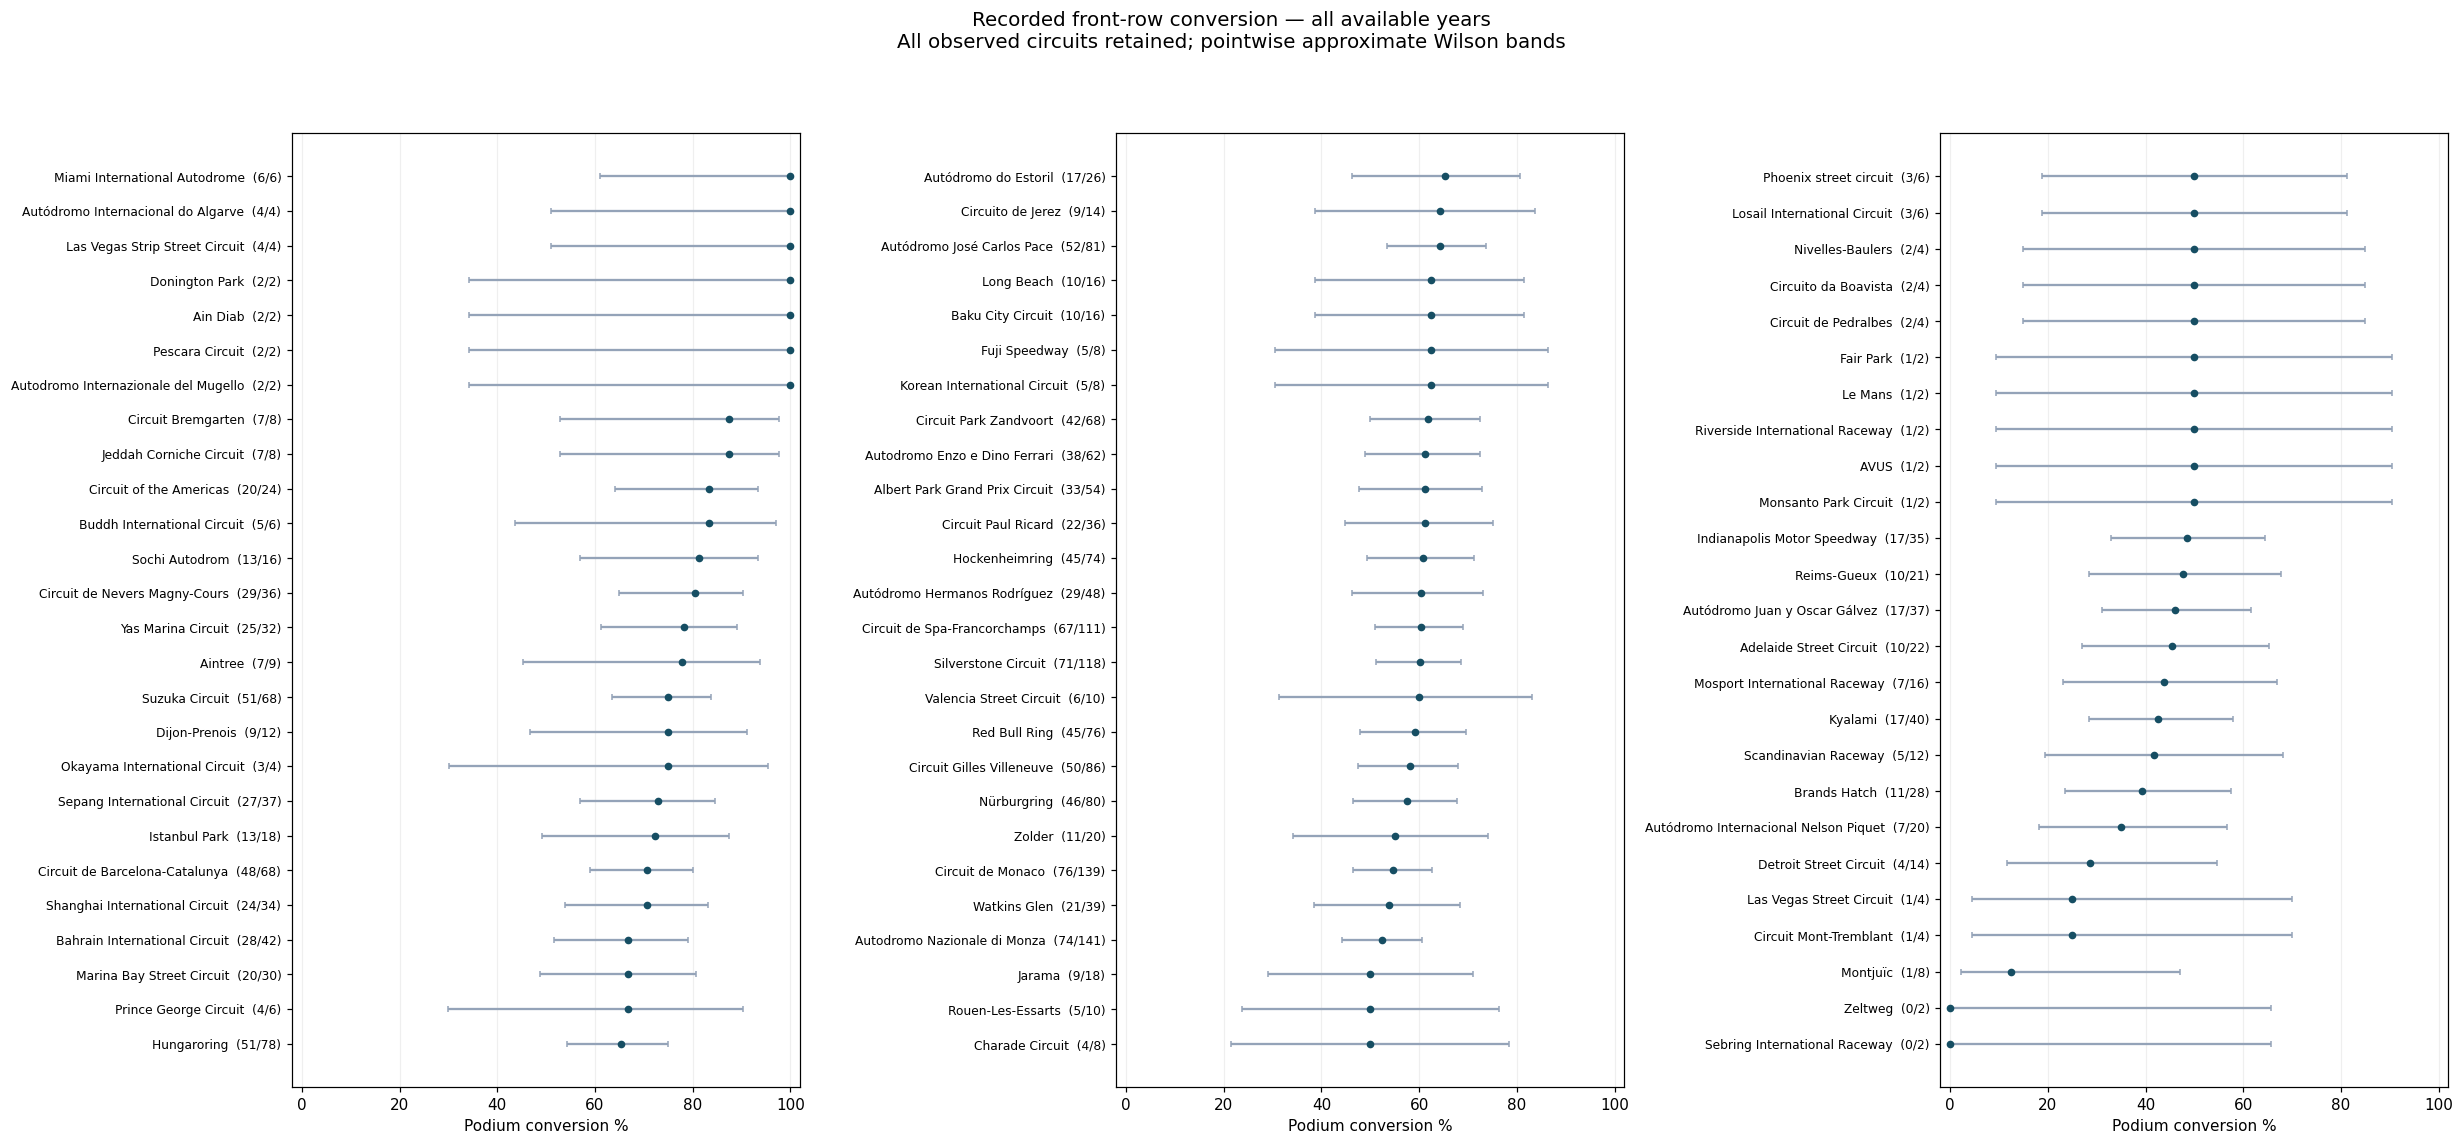

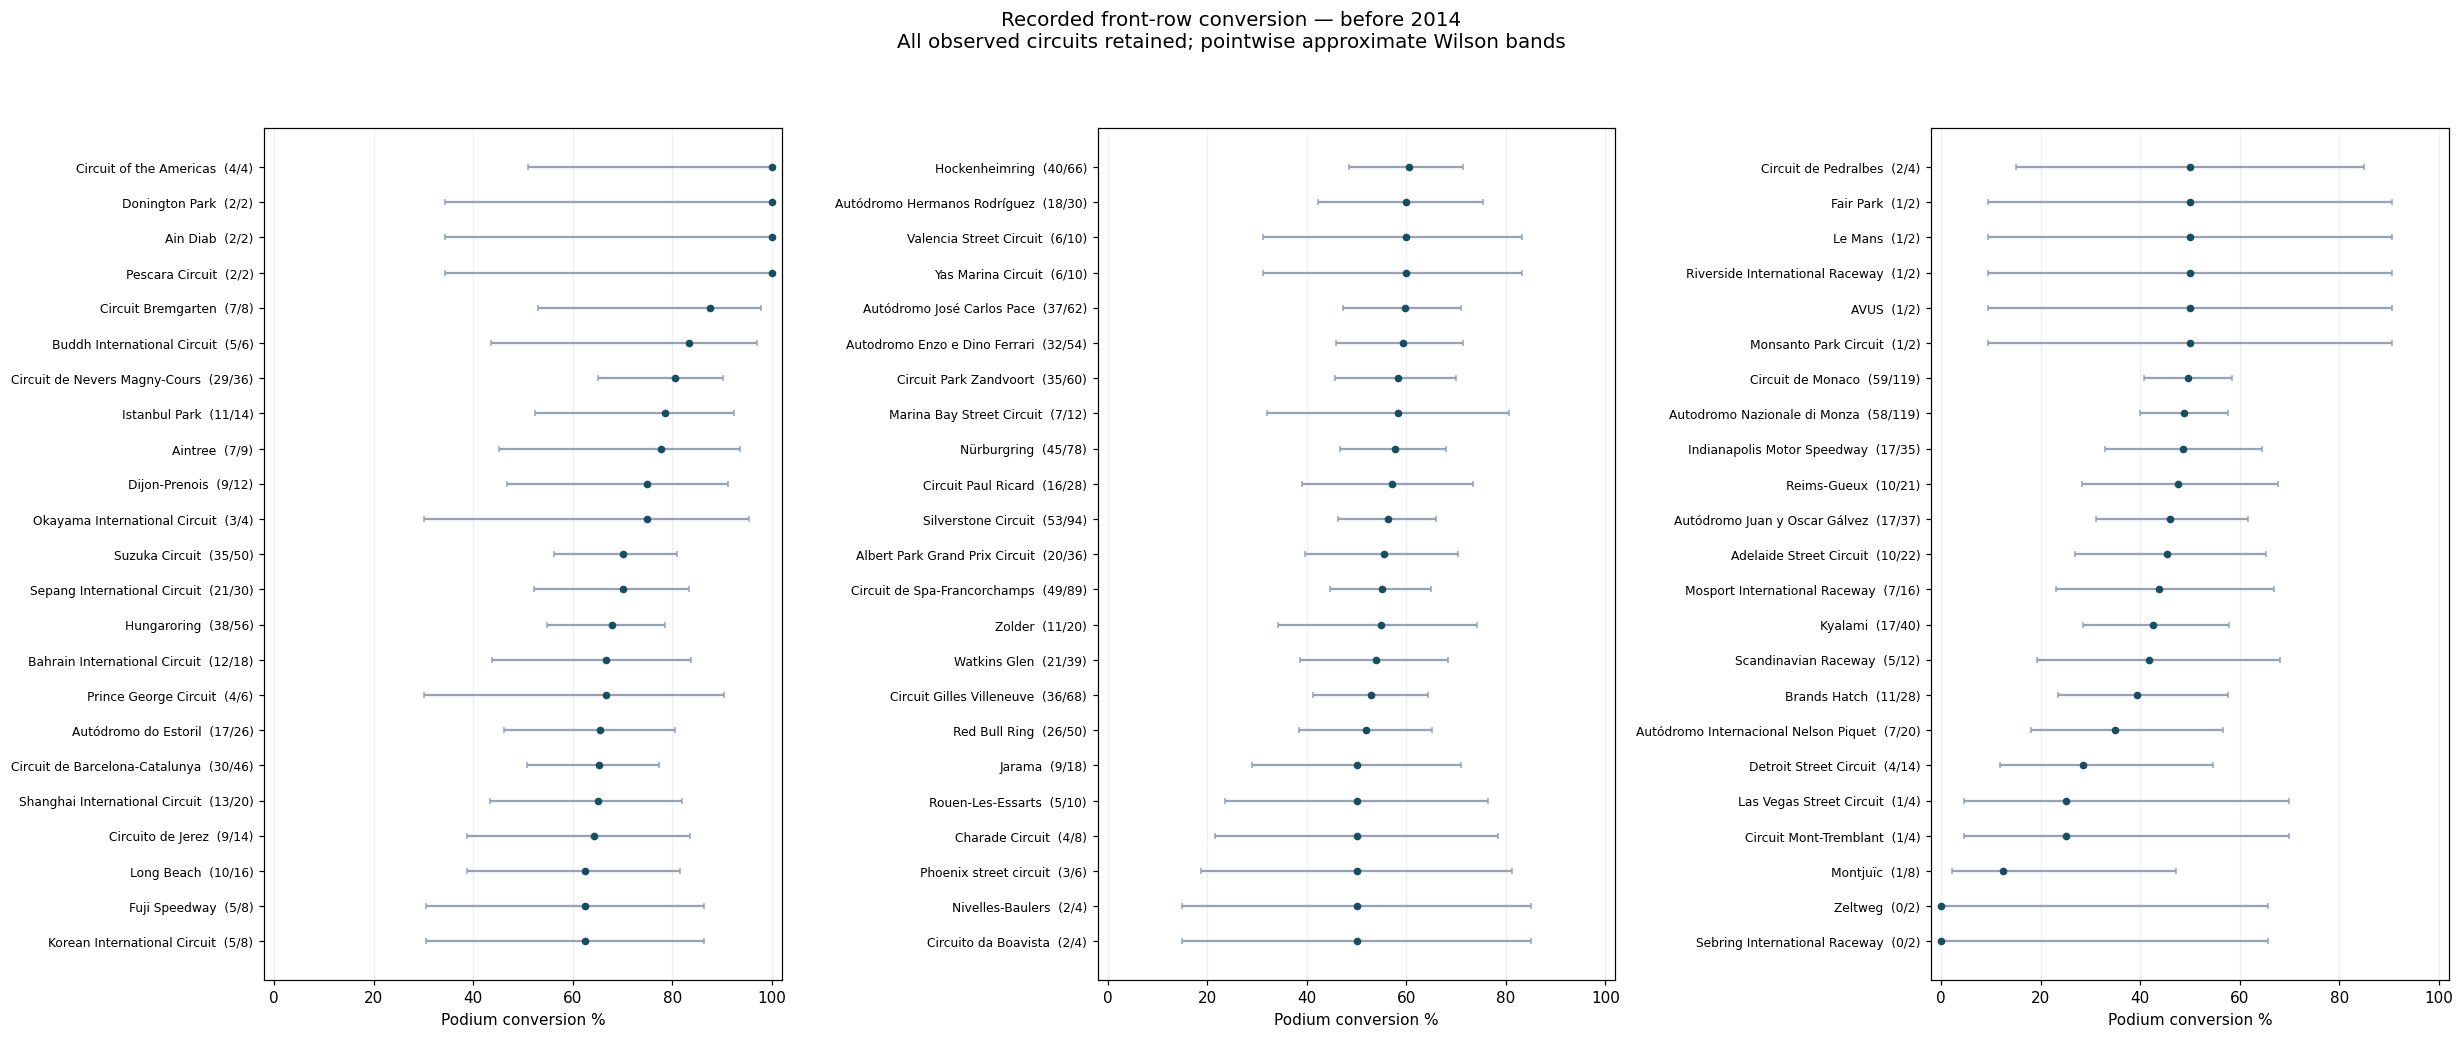

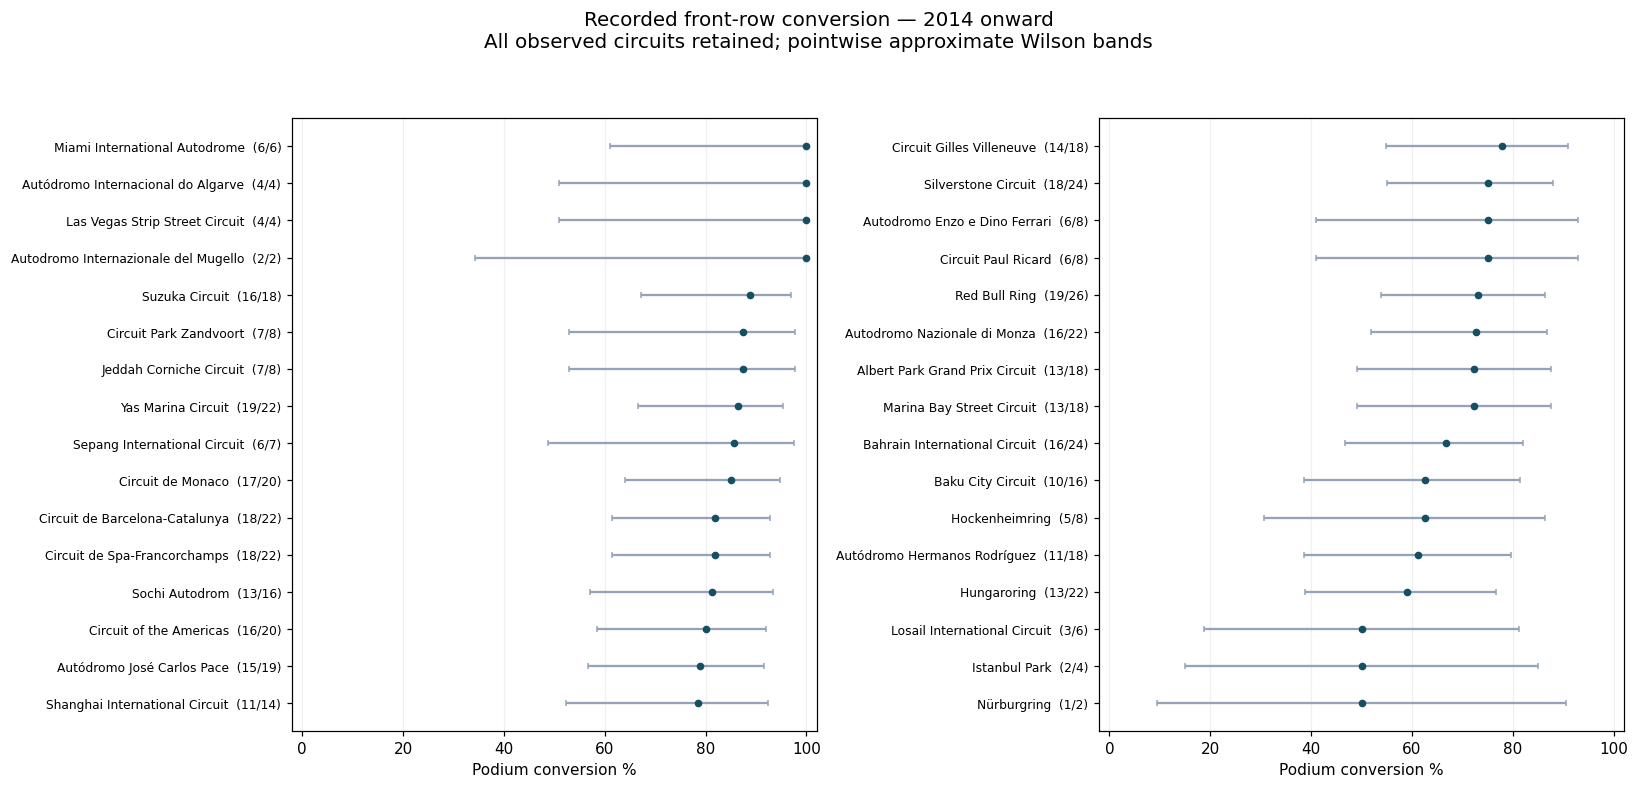

In [28]:
def all_circuit_forest(table, title, rank_col='observed_rank', panels=3):
    ordered = table.sort_values([rank_col, 'entries', 'circuitId'], ascending=[True, False, True]).reset_index(drop=True)
    per_panel = int(np.ceil(len(ordered) / panels))
    fig, axes = plt.subplots(1, panels, figsize=(7.5 * panels, max(6, 0.33 * per_panel + 2)), squeeze=False)
    for j, ax in enumerate(axes[0]):
        part = ordered.iloc[j * per_panel:(j + 1) * per_panel].copy()
        y = np.arange(len(part))
        rates = part.rate_pct.to_numpy(dtype=float)
        left = np.maximum(0, rates - part.ci_low_pct.to_numpy(dtype=float))
        right = np.maximum(0, part.ci_high_pct.to_numpy(dtype=float) - rates)
        ax.errorbar(rates,
            y,
            xerr=np.vstack([left,
            right]),
            fmt='o',
            markersize=4,
            color='#164e63',
            ecolor='#94a3b8',
            capsize=2)
        labels = [f'{r.circuit_name}  ({r.podiums}/{r.entries})' for r in part.itertuples()]
        ax.set_yticks(y)
        ax.set_yticklabels(labels, fontsize=8)
        ax.invert_yaxis()
        ax.set(xlim=(-2, 102), xlabel='Podium conversion %')
        ax.grid(axis='x', alpha=0.2)
    fig.suptitle(title + '\nAll observed circuits retained; pointwise approximate Wilson bands', fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()
    return set(ordered.circuitId)
q1_plotted_overall = all_circuit_forest(q1_overall, 'Recorded front-row conversion — all available years', panels=3)
q1_plotted_before = all_circuit_forest(q1_era.loc[q1_era.era.eq('Before 2014')],
    'Recorded front-row conversion — before 2014',
    'observed_era_rank',
    panels=3)
q1_plotted_after = all_circuit_forest(q1_era.loc[q1_era.era.eq('2014 onward')],
    'Recorded front-row conversion — 2014 onward',
    'observed_era_rank',
    panels=2)

Circuit presence:
               status  circuits
     Before 2014 only        45
Both eras: comparable        24
     2014 onward only         8

All common-circuit comparisons; rank gain >0 means a better observed rank:
                  circuit_name  podiums_before  entries_before  rate_pct_before  common_rank_before  podiums_after  entries_after  rate_pct_after  common_rank_after  rate_change_pp  rank_gain
                Suzuka Circuit              35              50             70.0                   3             16             18       88.888889                  1       18.888889          2
        Circuit Park Zandvoort              35              60        58.333333                  14              7              8            87.5                  2       29.166667         12
            Yas Marina Circuit               6              10             60.0                  10             19             22       86.363636                  3       26.363636          7
  Sepang I

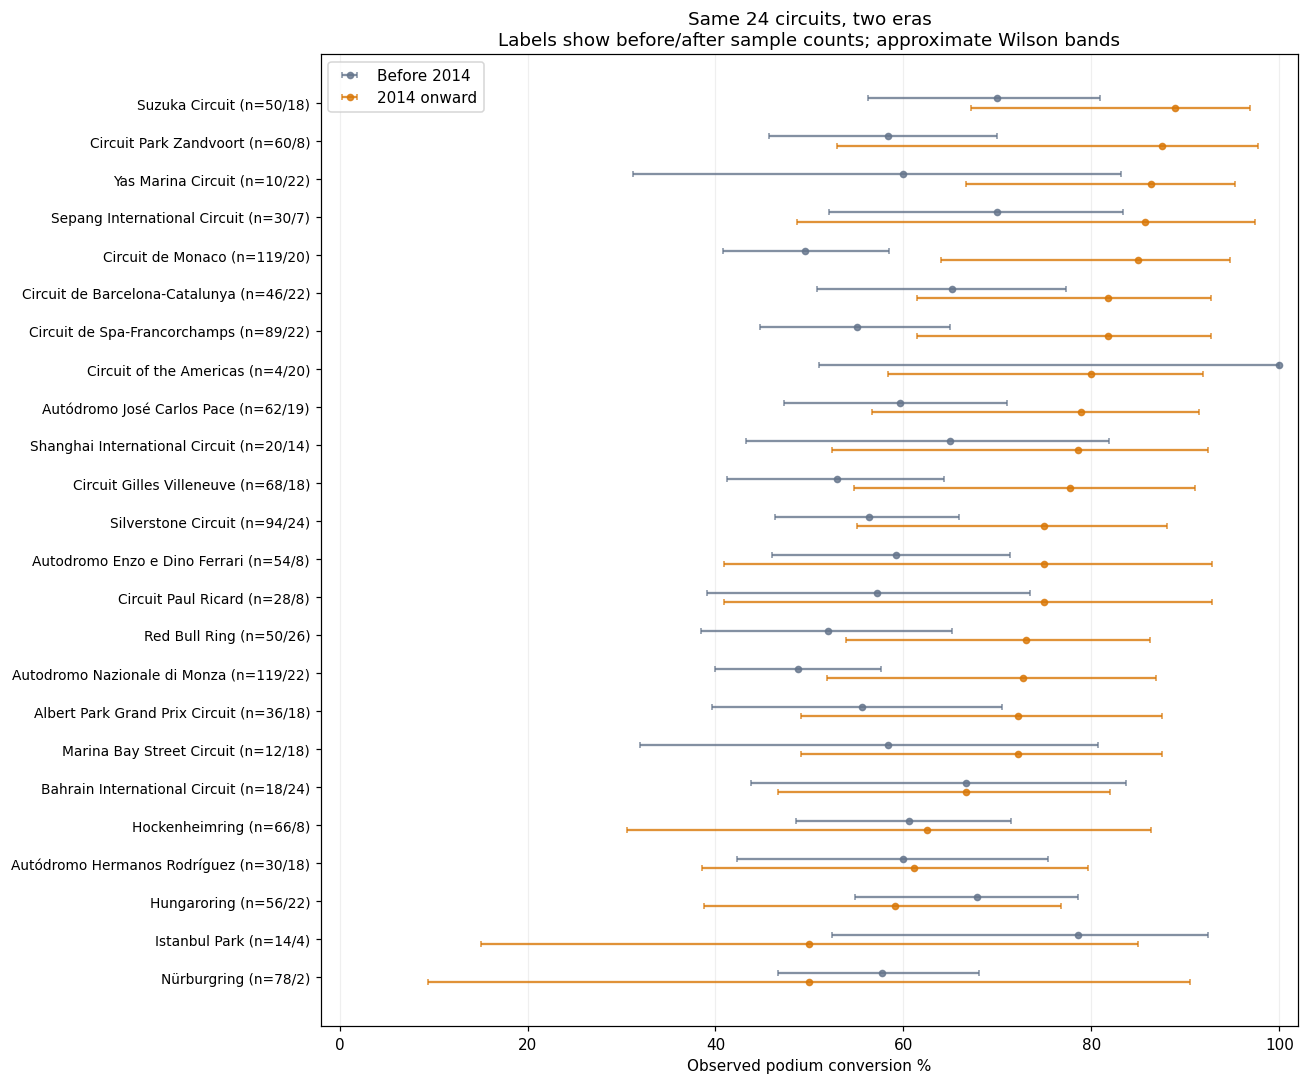

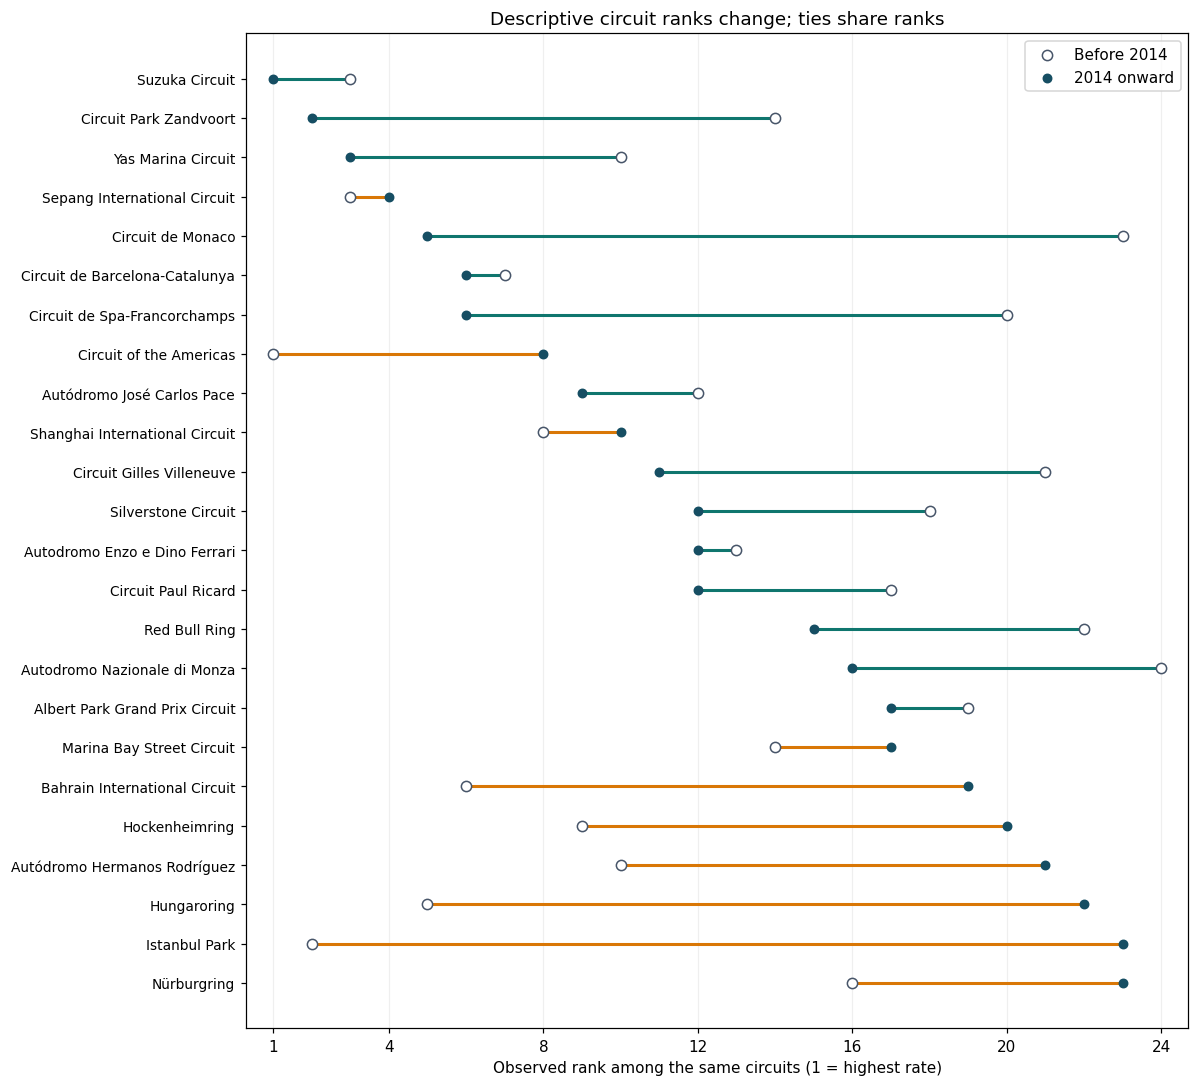

In [29]:
before_ids = set(q1_era.loc[q1_era.era.eq('Before 2014'), 'circuitId'])
after_ids = set(q1_era.loc[q1_era.era.eq('2014 onward'), 'circuitId'])
q1_common_ids = before_ids & after_ids
q1_common_long = q1_era.loc[q1_era.circuitId.isin(q1_common_ids)].copy()
q1_common_long['common_rank'] = q1_common_long.groupby('era').exact_fraction.rank(method='min', ascending=False).astype(int)
q1_presence = q1_overall[['circuitId', 'circuit_name']].copy()
q1_presence['before_2014_present'] = q1_presence.circuitId.isin(before_ids)
q1_presence['from_2014_present'] = q1_presence.circuitId.isin(after_ids)
q1_presence['comparison_status'] = np.select([q1_presence.circuitId.isin(q1_common_ids),
    q1_presence.circuitId.isin(before_ids - after_ids)],
    ['Both eras: comparable',
    'Before 2014 only'],
    default='2014 onward only')
common_before = q1_common_long.loc[q1_common_long.era.eq('Before 2014')].drop(columns='era')
common_after = q1_common_long.loc[q1_common_long.era.eq('2014 onward')].drop(columns='era')
q1_common = common_before.merge(common_after,
    on=['circuitId',
    'circuit_name'],
    suffixes=('_before',
    '_after'),
    validate='one_to_one')
q1_common['rate_change_pp'] = q1_common.rate_pct_after - q1_common.rate_pct_before
q1_common['rank_gain'] = q1_common.common_rank_before - q1_common.common_rank_after
print('Circuit presence:')
show(q1_presence.comparison_status.value_counts().rename_axis('status').reset_index(name='circuits'))
print('\nAll common-circuit comparisons; rank gain >0 means a better observed rank:')
show(q1_common.sort_values(['common_rank_after',
    'entries_after'],
    ascending=[True,
    False])[['circuit_name',
    'podiums_before',
    'entries_before',
    'rate_pct_before',
    'common_rank_before',
    'podiums_after',
    'entries_after',
    'rate_pct_after',
    'common_rank_after',
    'rate_change_pp',
    'rank_gain']])
ordered = q1_common.sort_values(['common_rank_after', 'entries_after'], ascending=[True, False]).reset_index(drop=True)
y = np.arange(len(ordered))
fig, ax = plt.subplots(figsize=(12, 10))
for offset, suffix, color, label in [(-0.12, 'before', '#64748b', 'Before 2014'), (0.12, 'after', '#d97706', '2014 onward')]:
    rates = ordered['rate_pct_' + suffix].to_numpy(dtype=float)
    lo = ordered['ci_low_pct_' + suffix].to_numpy(dtype=float)
    hi = ordered['ci_high_pct_' + suffix].to_numpy(dtype=float)
    ax.errorbar(rates,
        y + offset,
        xerr=np.vstack([np.maximum(0,
        rates - lo),
        np.maximum(0,
        hi - rates)]),
        fmt='o',
        color=color,
        ecolor=color,
        alpha=0.8,
        capsize=2,
        markersize=4,
        label=label)
ax.set_yticks(y)
ax.set_yticklabels([f'{r.circuit_name} (n={r.entries_before}/{r.entries_after})' for r in ordered.itertuples()], fontsize=9)
ax.invert_yaxis()
ax.set(xlim=(-2,
    102),
    xlabel='Observed podium conversion %',
    title=f'Same {len(ordered)} circuits, two eras\nLabels show before/after sample counts; approximate Wilson bands')
ax.legend()
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(11, 10))
for i, row in enumerate(ordered.itertuples()):
    color = '#0f766e' if row.rank_gain > 0 else '#d97706' if row.rank_gain < 0 else '#94a3b8'
    ax.plot([row.common_rank_before, row.common_rank_after], [i, i], color=color, linewidth=2)
ax.scatter(ordered.common_rank_before, y, facecolors='white', edgecolors='#475569', s=45, label='Before 2014', zorder=3)
ax.scatter(ordered.common_rank_after, y, color='#164e63', s=30, label='2014 onward', zorder=4)
ax.set_yticks(y)
ax.set_yticklabels(ordered.circuit_name, fontsize=9)
ax.invert_yaxis()
ax.set(xlim=(0.3,
    len(ordered) + 0.7),
    xlabel='Observed rank among the same circuits (1 = highest rate)',
    title='Descriptive circuit ranks change; ties share ranks')
ax.set_xticks([1, 4, 8, 12, 16, 20, len(ordered)])
ax.grid(axis='x', alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

**Observed:** 24 circuits appear in both eras (45 only before 2014, 8 only from 2014). Within this fixed set the ranking changes substantially: **Monaco rises from rank 23 to 5** (49.6% → 85.0%), Spa from 20 to 6 and Zandvoort from 14 to 2, while Suzuka leads from 2014 (16/18 = 88.9%).

 circuitId                   circuit_name  change_pp  bootstrap_low_pp  bootstrap_high_pp  races_before  races_after  constant_race_rates_before  constant_race_rates_after  limited_bootstrap_variation
         6              Circuit de Monaco  35.420168         17.857143          51.779661            60           10                       False                      False                        False
        39         Circuit Park Zandvoort  29.166667          2.500000          50.000000            30            4                       False                      False                        False
        13   Circuit de Spa-Francorchamps  26.762002          8.770221          43.333510            46           11                       False                      False                        False
        24             Yas Marina Circuit  26.363636         -8.181818          60.909091             5           11                       False                      False                        F

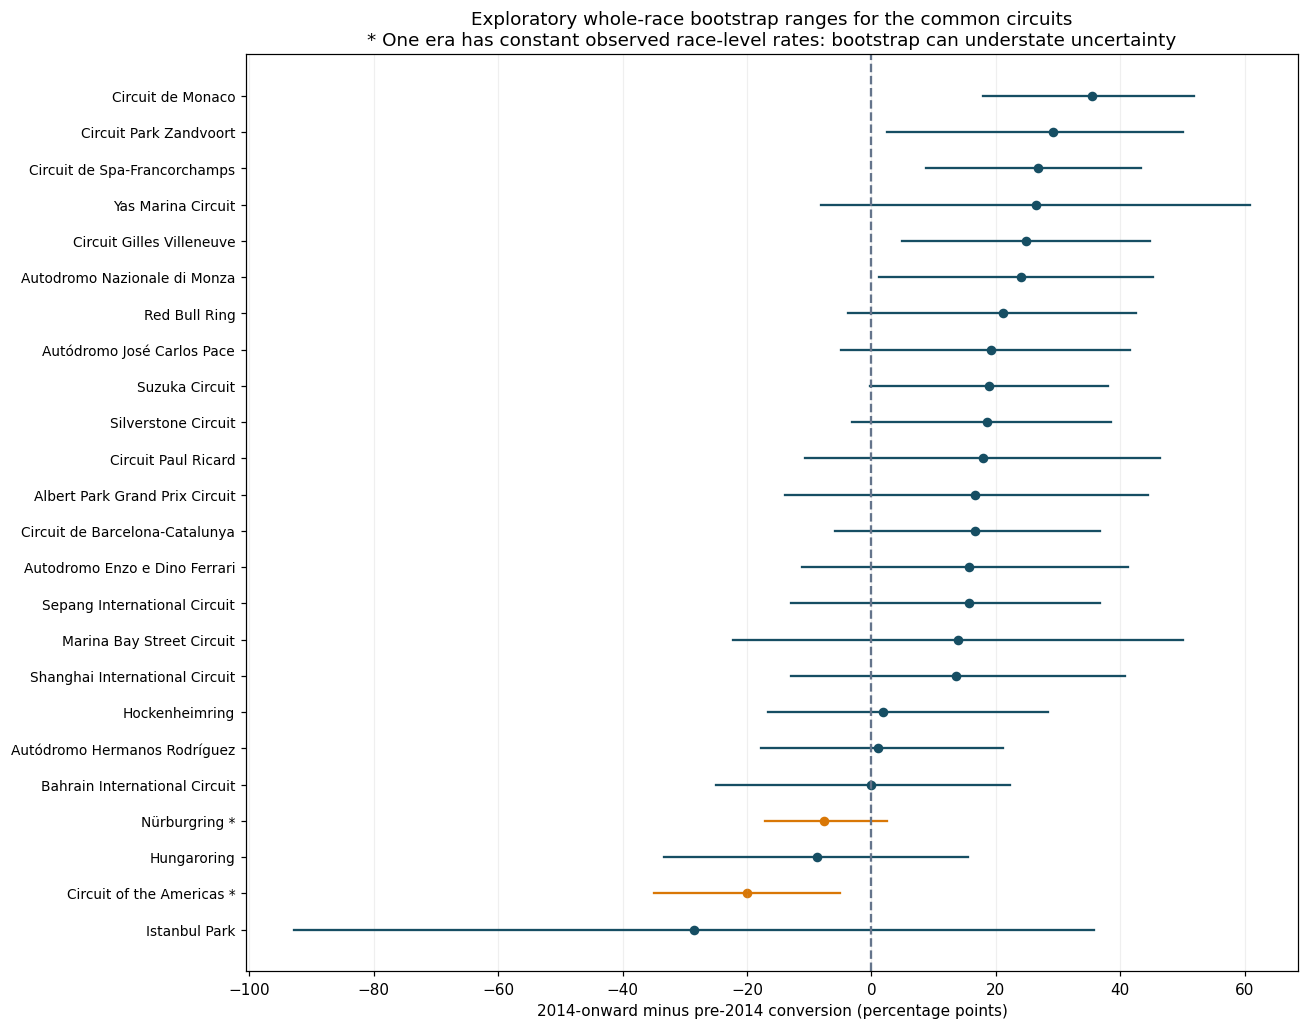

In [30]:
Q1_BOOTSTRAP_REPLICATES = 4000
Q1_BOOTSTRAP_SEED = 20261016
q1_bootstrap_rows = []
for cid in sorted(q1_common_ids):
    rng = np.random.default_rng(np.random.SeedSequence([Q1_BOOTSTRAP_SEED, int(cid)]))
    samples = {}
    support = {}
    for era in ['Before 2014', '2014 onward']:
        block = q1_primary.loc[q1_primary.circuitId.eq(cid) & q1_primary.era.eq(era)].groupby('raceId').agg(k=('podium',
            'sum'),
            n=('podium',
            'size'))
        k = block.k.to_numpy(dtype=float)
        n = block.n.to_numpy(dtype=float)
        indices = rng.integers(0, len(block), size=(Q1_BOOTSTRAP_REPLICATES, len(block)))
        samples[era] = k[indices].sum(axis=1) / n[indices].sum(axis=1)
        support[era] = {'races': len(block), 'distinct_race_rates': len(np.unique(k / n))}
    delta = 100 * (samples['2014 onward'] - samples['Before 2014'])
    point = q1_common.loc[q1_common.circuitId.eq(cid)].iloc[0]
    low, high = np.quantile(delta, [0.025, 0.975])
    q1_bootstrap_rows.append({'circuitId': cid,
        'circuit_name': point.circuit_name,
        'change_pp': point.rate_change_pp,
        'bootstrap_low_pp': low,
        'bootstrap_high_pp': high,
        'races_before': support['Before 2014']['races'],
        'races_after': support['2014 onward']['races'],
        'constant_race_rates_before': support['Before 2014']['distinct_race_rates'] == 1,
        'constant_race_rates_after': support['2014 onward']['distinct_race_rates'] == 1})
q1_bootstrap = pd.DataFrame(q1_bootstrap_rows)
q1_bootstrap['limited_bootstrap_variation'] = q1_bootstrap.constant_race_rates_before | q1_bootstrap.constant_race_rates_after
show(q1_bootstrap.sort_values('change_pp', ascending=False))
plot = q1_bootstrap.sort_values('change_pp').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 9.5))
for i, row in enumerate(plot.itertuples()):
    color = '#d97706' if row.limited_bootstrap_variation else '#164e63'
    ax.plot([row.bootstrap_low_pp, row.bootstrap_high_pp], [i, i], color=color, linewidth=1.5)
    ax.scatter(row.change_pp, i, color=color, s=28)
labels = [r.circuit_name + (' *' if r.limited_bootstrap_variation else '') for r in plot.itertuples()]
ax.set_yticks(np.arange(len(plot)))
ax.set_yticklabels(labels, fontsize=9)
ax.axvline(0, color='#64748b', linestyle='--')
ax.grid(axis='x', alpha=0.2)
ax.set(xlabel='2014-onward minus pre-2014 conversion (percentage points)',
    title='Exploratory whole-race bootstrap ranges for the common circuits\n* One era has constant observed race-level rates: bootstrap can understate uncertainty')
plt.tight_layout()
plt.show()

Aggregate population sensitivity:
                      population         era  podiums  entries   rate_pct  ci_low_pct  ci_high_pct
Chosen: unambiguous source slots 2014 onward      345      454  75.991189   71.854513    79.691715
Chosen: unambiguous source slots Before 2014      995     1770  56.214689   53.892426    58.510035
    All recorded front-row pairs 2014 onward      345      454  75.991189   71.854513    79.691715
    All recorded front-row pairs Before 2014     1000     1780  56.179775   53.863941    58.468993
      Omit eleven conflict races 2014 onward      345      454  75.991189   71.854513    79.691715
      Omit eleven conflict races Before 2014      990     1761  56.218058   53.889859    58.519188
Complete source-consistent races 2014 onward      343      452  75.884956   71.733745    79.599892
Complete source-consistent races Before 2014      985     1752  56.221461   53.887280    58.528419

Fixed-universe common-circuit sensitivity:
                      populatio

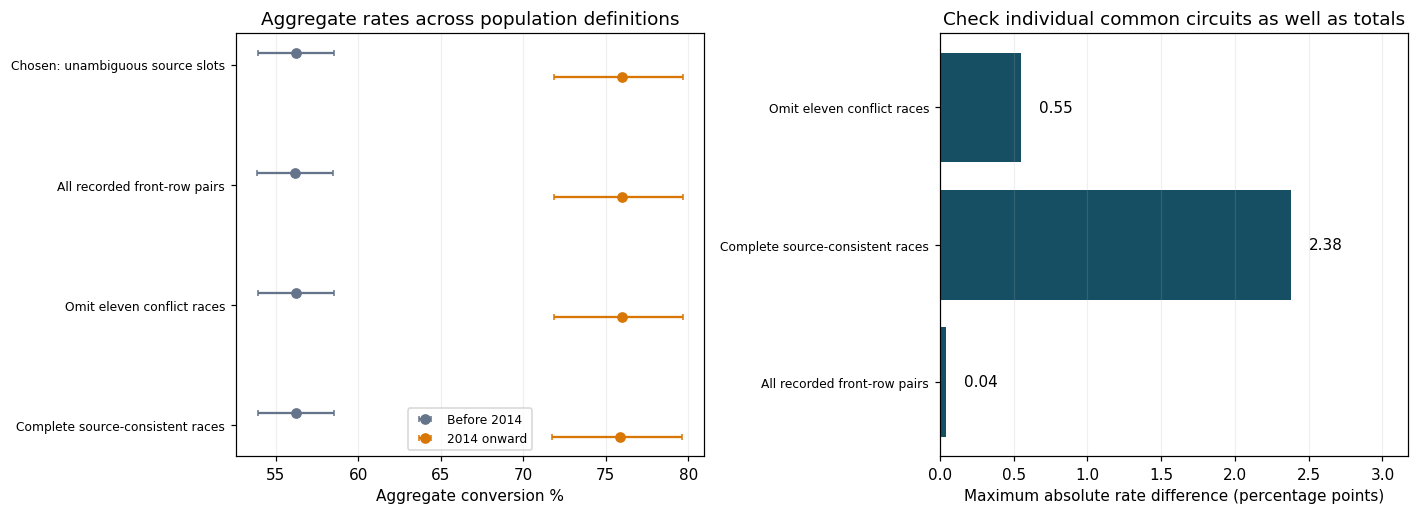

In [31]:
q1_sensitivity_populations = {'Chosen: unambiguous source slots': q1_primary,
    'All recorded front-row pairs': q1_candidates['All recorded pairs'],
    'Omit eleven conflict races': q1_candidates['Omit 11 source-conflict races'],
    'Complete source-consistent races': q1_candidates['Complete source-consistent races']}
q1_sensitivity_era = []
q1_sensitivity_common = []
for policy, table in q1_sensitivity_populations.items():
    era = q1_summarize(table, ['era'])
    era['population'] = policy
    q1_sensitivity_era.append(era)
    circuits = q1_summarize(table, ['circuitId', 'circuit_name', 'era'])
    part = circuits.loc[circuits.circuitId.isin(q1_common_ids)].copy()
    part['common_rank'] = part.groupby('era').exact_fraction.rank(method='min', ascending=False).astype(int)
    part['population'] = policy
    q1_sensitivity_common.append(part)
q1_sensitivity_era = pd.concat(q1_sensitivity_era, ignore_index=True)
q1_sensitivity_common = pd.concat(q1_sensitivity_common, ignore_index=True)
primary_ref = q1_common_long[['circuitId',
    'era',
    'rate_pct',
    'common_rank']].rename(columns={'rate_pct': 'primary_rate_pct',
    'common_rank': 'primary_common_rank'})
q1_sensitivity_common = q1_sensitivity_common.merge(primary_ref, on=['circuitId', 'era'], validate='many_to_one')
q1_sensitivity_common['rate_difference_pp'] = q1_sensitivity_common.rate_pct - q1_sensitivity_common.primary_rate_pct
q1_sensitivity_common['rank_difference'] = q1_sensitivity_common.common_rank - q1_sensitivity_common.primary_common_rank
q1_sensitivity_summary = q1_sensitivity_common.groupby('population').agg(max_abs_circuit_rate_change_pp=('rate_difference_pp',
    lambda s: float(s.abs().max())),
    changed_common_circuit_era_ranks=('rank_difference',
    lambda s: int(s.ne(0).sum())),
    common_circuit_era_groups=('circuitId',
    'size')).reset_index()
print('Aggregate population sensitivity:')
show(q1_sensitivity_era[['population', 'era', 'podiums', 'entries', 'rate_pct', 'ci_low_pct', 'ci_high_pct']])
print('\nFixed-universe common-circuit sensitivity:')
show(q1_sensitivity_summary)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for offset, era, color in [(-0.1, 'Before 2014', '#64748b'), (0.1, '2014 onward', '#d97706')]:
    part = q1_sensitivity_era.loc[q1_sensitivity_era.era.eq(era)].set_index('population').reindex(q1_sensitivity_populations)
    y = np.arange(len(part)) + offset
    rates = part.rate_pct.to_numpy(dtype=float)
    axes[0].errorbar(rates,
        y,
        xerr=np.vstack([np.maximum(0,
        rates - part.ci_low_pct),
        np.maximum(0,
        part.ci_high_pct - rates)]),
        fmt='o',
        color=color,
        label=era,
        capsize=2)
axes[0].set_yticks(np.arange(len(q1_sensitivity_populations)))
axes[0].set_yticklabels(list(q1_sensitivity_populations), fontsize=8)
axes[0].invert_yaxis()
axes[0].set(xlabel='Aggregate conversion %', title='Aggregate rates across population definitions')
axes[0].legend(fontsize=8)
axes[0].grid(axis='x', alpha=0.2)
nonprimary = q1_sensitivity_summary.loc[~q1_sensitivity_summary.population.eq('Chosen: unambiguous source slots')]
axes[1].barh(nonprimary.population, nonprimary.max_abs_circuit_rate_change_pp, color='#164e63')
for i, v in enumerate(nonprimary.max_abs_circuit_rate_change_pp):
    axes[1].text(v + 0.12, i, f'{v:.2f}', va='center')
axes[1].set(xlim=(0,
    max(nonprimary.max_abs_circuit_rate_change_pp) * 1.25 + 0.2),
    xlabel='Maximum absolute rate difference (percentage points)',
    title='Check individual common circuits as well as totals')
axes[1].tick_params(axis='y', labelsize=8)
axes[1].grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

### Answer to Question 1
- **Overall:** a front-row start converted into a podium **56.2% of the time before 2014 (995/1,770)** and **76.0% from 2014 onward (345/454)**.
- **Top circuits:** before 2014 the highest observed rates are 100% ties from tiny samples (Circuit of the Americas 4/4, Donington, Ain Diab, Pescara 2/2). From 2014 onward: Miami 6/6, Algarve 4/4, Las Vegas 4/4, Mugello 2/2, then **Suzuka 16/18 (88.9%)** — a larger sample than those perfect-rate examples, with its uncertainty still shown. The wide Wilson intervals mean these small-sample leaders are not reliably "better" circuits.
- **Does the ranking change after 2014? Yes.** On the 24 circuits present in both eras, Monaco moves from 23rd to 5th, Spa 20th → 6th, Zandvoort 14th → 2nd. Several whole-race bootstrap ranges for the change still cross zero, so individual moves are uncertain while the aggregate descriptive rate is higher in the later era.
- **Grid vs qualifying:** 49 of 986 front-row starters with qualifying data have different exact qualifying/grid positions, while 36 qualified outside P1–P2 (27 of 454 from 2014), and drivers who qualified on the front row but started further back convert far less often (table above). Using the **starting grid** is therefore the right field for this question.
- **Robustness:** the alternative population rules change a common-circuit rate by at most 2.4 percentage points.

**Grain, missingness and cutoff:** one row per driver–race; pairs with grid 0, conflicting grids or shared source slots are excluded from this analysis only (they stay in the data). The podium outcome is post-race and used only for this descriptive question. These are associations — newer cars, reliability and team dominance all differ by era, so the change is not a causal effect of the 2014 rules.

## 4. Data question 2 — home nationality and podiums
**Question:** do drivers podium more often at a circuit in their home country, after controlling for starting position?

**Joins:** unique driver–race view → `drivers` (nationality) → `races` → `circuits` (country). **Home** = the driver's recorded nationality maps to the circuit's country (e.g. British → United Kingdom; UK/USA spellings reconciled). Compound nationalities (American-Italian, Argentine-Italian) count as home in either country; East German and Rhodesian are left unresolved and excluded rather than guessed.

**Population:** the Indianapolis 500 (1950–1960, almost only American drivers who rarely raced elsewhere) is excluded from the main comparison and kept as a sensitivity check. Only rows with a clear numbered grid are used (no grid zero, no conflicts, no shared slots).

**Controlling for grid:** home drivers may simply qualify differently, so we compute podium rates **at each grid position** and average home and away with the **same grid weights**. This compares drivers who started from the same places. It is an association, not a causal home advantage.

In [32]:
q2_driver_race = analysis_driver_race.copy()
q2_drivers = analysis_tables['drivers'].copy()
q2_races = analysis_tables['races'].copy()
q2_circuits = analysis_tables['circuits'].copy()
q2_nationality_country = {'American': 'United States',
    'Argentine': 'Argentina',
    'Argentinian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'United Kingdom',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela'}
q2_pending_labels = {'American-Italian', 'Argentine-Italian', 'East German', 'Rhodesian'}
q2_country_aliases = {'UK': 'United Kingdom', 'USA': 'United States', 'United States': 'United States'}
q2_prepared = q2_driver_race.merge(q2_drivers[['driverId',
    'forename',
    'surname',
    'nationality']],
    on='driverId',
    how='left',
    validate='many_to_one').merge(q2_races[['raceId',
    'year',
    'circuitId',
    'name']].rename(columns={'name': 'race_name'}),
    on='raceId',
    how='left',
    validate='many_to_one').merge(q2_circuits[['circuitId',
    'name',
    'country']].rename(columns={'name': 'circuit_name'}),
    on='circuitId',
    how='left',
    validate='many_to_one')
q2_prepared['nationality_key'] = q2_prepared['nationality'].astype('string').str.strip()
q2_prepared['driver_country_comparison'] = q2_prepared['nationality_key'].map(q2_nationality_country).astype('string')
q2_country_key = q2_prepared['country'].astype('string').str.strip()
q2_prepared['circuit_country_comparison'] = q2_country_key.replace(q2_country_aliases)
q2_prepared['home_mapping_status'] = q2_prepared['driver_country_comparison'].notna().map({True: 'resolved_ordinary',
    False: 'unresolved_special_case'})
q2_prepared['is_home_nationality'] = q2_prepared['driver_country_comparison'].eq(q2_prepared['circuit_country_comparison']).astype('boolean')
q2_prepared.loc[q2_prepared['driver_country_comparison'].isna(), 'is_home_nationality'] = pd.NA
q2_crosswalk = q2_prepared.groupby(['nationality',
    'nationality_key',
    'driver_country_comparison',
    'home_mapping_status'],
    dropna=False).agg(driver_count=('driverId',
    'nunique'),
    driver_race_pairs=('driverId',
    'size')).reset_index()
q2_pending = q2_prepared[q2_prepared['home_mapping_status'].eq('unresolved_special_case')].copy()
q2_pending_summary = q2_pending.groupby(['nationality',
    'country'],
    dropna=False).agg(driver_race_pairs=('driverId',
    'size'),
    drivers=('driverId',
    'nunique')).reset_index()
q2_examples = q2_prepared.loc[q2_prepared.driverId.eq(1) & q2_prepared.country.eq('UK') | q2_prepared.driverId.eq(858) & q2_prepared.raceId.eq(1119) | q2_prepared.driverId.eq(861)].groupby('driverId',
    sort=False).head(1)[['forename',
    'surname',
    'year',
    'race_name',
    'nationality',
    'country',
    'driver_country_comparison',
    'circuit_country_comparison',
    'is_home_nationality']]
print('Input unique pairs:', len(q2_driver_race), '| Output preparation pairs:', len(q2_prepared))
print('Nationality labels:',
    len(q2_crosswalk),
    '| Ordinary:',
    q2_crosswalk.home_mapping_status.eq('resolved_ordinary').sum(),
    '| Unresolved:',
    q2_crosswalk.home_mapping_status.eq('unresolved_special_case').sum())
print(q2_prepared.home_mapping_status.value_counts().to_string())
print('\nActual mapping examples:\n', q2_examples.to_string(index=False))
print('\nUnresolved cases, retained without a home/away assignment:\n', q2_pending_summary.to_string(index=False))

Input unique pairs: 26668 | Output preparation pairs: 26668
Nationality labels: 43 | Ordinary: 39 | Unresolved: 4
home_mapping_status
resolved_ordinary          26641
unresolved_special_case       27

Actual mapping examples:
 forename   surname  year            race_name  nationality       country driver_country_comparison circuit_country_comparison  is_home_nationality
   Lewis  Hamilton  2009   British Grand Prix      British            UK            United Kingdom             United Kingdom                 True
   Logan  Sargeant  2023 Las Vegas Grand Prix     American United States             United States              United States                 True
  Franco Colapinto  2024   Italian Grand Prix Argentinian          Italy                 Argentina                      Italy                False

Unresolved cases, retained without a home/away assignment:
       nationality      country  driver_race_pairs  drivers
 American-Italian        Italy                  2        1
Argent

In [33]:
import json
q2_compound_before = q2_prepared.copy().astype({'is_home_nationality': 'boolean'})
q2_compound_after = q2_compound_before.copy(deep=True)
q2_compound_members = {'American-Italian': ['United States', 'Italy'], 'Argentine-Italian': ['Argentina', 'Italy']}

def q2_members(row):
    if row['nationality_key'] in q2_compound_members:
        return json.dumps(q2_compound_members[row['nationality_key']])
    if pd.notna(row['driver_country_comparison']):
        return json.dumps([row['driver_country_comparison']])
    return pd.NA
q2_compound_after['driver_countries_comparison'] = q2_compound_after.apply(q2_members, axis=1).astype('string')
q2_compound_mask = q2_compound_after.nationality_key.isin(q2_compound_members)
for idx, row in q2_compound_after.loc[q2_compound_mask].iterrows():
    q2_compound_after.loc[idx,
        'is_home_nationality'] = row['circuit_country_comparison'] in q2_compound_members[row['nationality_key']]
q2_compound_after.loc[q2_compound_mask, 'home_mapping_status'] = 'resolved_compound'
q2_compound_audit = q2_compound_after.loc[q2_compound_mask,
    ['raceId',
    'driverId',
    'forename',
    'surname',
    'year',
    'nationality',
    'country',
    'driver_countries_comparison',
    'is_home_nationality']].copy()
q2_compound_pending = q2_compound_after[q2_compound_after.is_home_nationality.isna()].copy()
print(q2_compound_audit.to_string(index=False))
print('\nBefore / after:',
    len(q2_compound_before),
    '/',
    len(q2_compound_after),
    'rows; unknown flags',
    q2_compound_before.is_home_nationality.isna().sum(),
    '→',
    q2_compound_after.is_home_nationality.isna().sum())
print('\nRemaining historical cases:\n',
    q2_compound_pending.groupby(['nationality',
    'country']).agg(driver_race_pairs=('driverId',
    'size'),
    drivers=('driverId',
    'nunique')).reset_index().copy().to_string(index=False))

 raceId  driverId   forename   surname  year       nationality   country driver_countries_comparison  is_home_nationality
    744       491    Alfonso    Thiele  1961  American-Italian     Italy  ["United States", "Italy"]                 True
    754       491    Alfonso    Thiele  1960  American-Italian     Italy  ["United States", "Italy"]                 True
    764       573 Alessandro de Tomaso  1959 Argentine-Italian       USA      ["Argentina", "Italy"]                False
    776       573 Alessandro de Tomaso  1957 Argentine-Italian Argentina      ["Argentina", "Italy"]                 True

Before / after: 26668 / 26668 rows; unknown flags 27 → 23

Remaining historical cases:
 nationality      country  driver_race_pairs  drivers
East German      Germany                  5        3
  Rhodesian        Italy                  1        1
  Rhodesian South Africa                 17        4


**Observed:** 39 of 43 nationality labels map directly; the two compound labels add 4 more rows (3 home, 1 away). 23 rows (East German, Rhodesian) stay unresolved and are excluded from Q2 only.

In [34]:
q2_history_before = q2_compound_after.copy().astype({'is_home_nationality': 'boolean'})
q2_history_after = q2_history_before.copy(deep=True)
q2_history_after['q2_home_classification_eligible'] = q2_history_after.is_home_nationality.notna()
q2_history_after['q2_home_classification_reason'] = q2_history_after.q2_home_classification_eligible.map({True: 'nationality_mapping_resolved',
    False: 'historical_nationality_unresolved'})
q2_history_excluded = q2_history_after.loc[~q2_history_after.q2_home_classification_eligible]
q2_history_ledger = q2_history_after[['raceId',
    'driverId',
    'nationality',
    'q2_home_classification_eligible',
    'q2_home_classification_reason']].copy()
q2_history_summary = q2_history_ledger.groupby(['q2_home_classification_eligible',
    'q2_home_classification_reason']).size().rename('driver_race_pairs').reset_index()
print(q2_history_summary.to_string(index=False))
q2_indy = q2_history_after.loc[q2_history_after.race_name.eq('Indianapolis 500')]
print('\nIndianapolis 500 audit')
print('Races:',
    q2_indy.raceId.nunique(),
    '| Years:',
    q2_indy.year.min(),
    'to',
    q2_indy.year.max(),
    '| Unique pairs:',
    len(q2_indy))
print(q2_indy.groupby(['nationality', 'country']).size().rename('pairs').to_string())
print('Indianapolis rows still retained in the preparation table:',
    len(q2_history_after.loc[q2_history_after.race_name.eq('Indianapolis 500')]))

 q2_home_classification_eligible     q2_home_classification_reason  driver_race_pairs
                           False historical_nationality_unresolved                 23
                            True      nationality_mapping_resolved              26645

Indianapolis 500 audit
Races: 11 | Years: 1950 to 1960 | Unique pairs: 381
nationality  country
American     USA        380
Italian      USA          1
Indianapolis rows still retained in the preparation table: 381


In [35]:
q2_event_before = q2_history_after.copy().astype({'is_home_nationality': 'boolean'})
q2_event_after = q2_event_before.copy(deep=True)
q2_event_after['is_indianapolis_500'] = q2_event_after.race_name.eq('Indianapolis 500')
q2_event_after['q2_main_eligible_before_grid'] = q2_event_after.q2_home_classification_eligible & ~q2_event_after.is_indianapolis_500
q2_event_after['q2_indy_sensitivity_eligible_before_grid'] = q2_event_after.q2_home_classification_eligible
q2_event_after['q2_event_population_reason'] = 'main_candidate_before_grid'
q2_event_after.loc[q2_event_after.is_indianapolis_500, 'q2_event_population_reason'] = 'indianapolis_sensitivity_only'
q2_event_after.loc[~q2_event_after.q2_home_classification_eligible,
    'q2_event_population_reason'] = 'historical_nationality_unresolved'
q2_event_indy = q2_event_after.loc[q2_event_after.is_indianapolis_500]
q2_event_ledger = q2_event_after[['raceId',
    'driverId',
    'is_indianapolis_500',
    'q2_main_eligible_before_grid',
    'q2_indy_sensitivity_eligible_before_grid',
    'q2_event_population_reason']]
q2_event_summary = q2_event_ledger.groupby('q2_event_population_reason').size().rename('driver_race_pairs').reset_index()
print('Event policy, before grid eligibility:\n', q2_event_summary.to_string(index=False))
q2_grid_results = analysis_tables['results'].copy()
q2_grid_source_pairs = q2_grid_results.loc[q2_grid_results.grid.gt(0), ['raceId', 'grid', 'driverId']].drop_duplicates()
q2_grid_slots = q2_grid_source_pairs.groupby(['raceId',
    'grid']).driverId.nunique().rename('source_driver_count').reset_index()
q2_grid_ambiguous = q2_grid_slots.loc[q2_grid_slots.source_driver_count.gt(1)]
print('\nAll original positive grid slots with multiple source drivers:',
    len(q2_grid_ambiguous),
    'across',
    q2_grid_ambiguous.raceId.nunique(),
    'races')
q2_grid_diagnostic = q2_event_after.merge(q2_grid_slots.rename(columns={'grid': 'grid_position'}),
    on=['raceId',
    'grid_position'],
    how='left',
    validate='many_to_one')
q2_grid_diagnostic['grid_audit_category'] = 'clear_numbered_grid'
q2_grid_diagnostic.loc[q2_grid_diagnostic.source_driver_count.gt(1),
    'grid_audit_category'] = 'multiple_source_drivers_at_slot'
q2_grid_diagnostic.loc[q2_grid_diagnostic.grid_zero_recorded, 'grid_audit_category'] = 'zero_without_numbered_grid'
q2_grid_diagnostic.loc[q2_grid_diagnostic.grid_conflict, 'grid_audit_category'] = 'conflicting_grids_within_pair'
q2_grid_main = q2_grid_diagnostic.loc[q2_grid_diagnostic.q2_main_eligible_before_grid]
q2_grid_summary = q2_grid_main.groupby('grid_audit_category').size().rename('driver_race_pairs').reset_index()
print('\nMain candidates — grid audit categories:\n', q2_grid_summary.to_string(index=False))
q2_grid_examples = q2_grid_main.loc[q2_grid_main.grid_audit_category.eq('multiple_source_drivers_at_slot'),
    ['raceId',
    'year',
    'race_name',
    'forename',
    'surname',
    'grid_position',
    'grid_conflict',
    'source_driver_count']].sort_values(['year',
    'raceId',
    'grid_position']).head(8)
print('\nExamples: an agreed pair grid can still share an original slot:\n', q2_grid_examples.to_string(index=False))
q2_grid_support = q2_grid_main.loc[q2_grid_main.grid_audit_category.eq('clear_numbered_grid')].groupby(['grid_position',
    'is_home_nationality']).size().unstack(fill_value=0).rename(columns={False: 'away_pairs',
    True: 'home_pairs'})
print('\nNumbered grid positions with home and away support:',
    ((q2_grid_support.home_pairs > 0) & (q2_grid_support.away_pairs > 0)).sum(),
    'of',
    len(q2_grid_support))
print('Positions lacking both groups:\n',
    q2_grid_support.loc[q2_grid_support.home_pairs.eq(0) | q2_grid_support.away_pairs.eq(0)].to_string())

Event policy, before grid eligibility:
        q2_event_population_reason  driver_race_pairs
historical_nationality_unresolved                 23
    indianapolis_sensitivity_only                381
       main_candidate_before_grid              26264

All original positive grid slots with multiple source drivers: 179 across 106 races

Main candidates — grid audit categories:
             grid_audit_category  driver_race_pairs
            clear_numbered_grid              24350
  conflicting_grids_within_pair                 60
multiple_source_drivers_at_slot                223
     zero_without_numbered_grid               1631

Examples: an agreed pair grid can still share an original slot:
  raceId  year          race_name forename      surname  grid_position  grid_conflict  source_driver_count
    833  1950 British Grand Prix    Peter       Walker           10.0          False                  2.0
    833  1950 British Grand Prix     Tony         Rolt           10.0          False   

In [36]:
q2_grid_preparation_before = q2_event_after.copy().astype({'is_home_nationality': 'boolean'})
q2_grid_audit = q2_grid_diagnostic.copy().astype({'is_home_nationality': 'boolean'})
q2_grid_preparation = q2_grid_preparation_before.merge(q2_grid_audit[['raceId',
    'driverId',
    'source_driver_count',
    'grid_audit_category']],
    on=['raceId',
    'driverId'],
    how='left',
    validate='one_to_one')
q2_grid_clear = q2_grid_preparation.grid_audit_category.eq('clear_numbered_grid')
q2_grid_preparation['q2_main_grid_eligible'] = q2_grid_preparation.q2_main_eligible_before_grid & q2_grid_clear
q2_grid_preparation['q2_indy_sensitivity_grid_eligible'] = q2_grid_preparation.q2_indy_sensitivity_eligible_before_grid & q2_grid_clear
q2_grid_preparation['q2_main_grid_eligibility_reason'] = 'included_clear_grid'
q2_grid_preparation.loc[~q2_grid_clear,
    'q2_main_grid_eligibility_reason'] = q2_grid_preparation.loc[~q2_grid_clear,
    'grid_audit_category']
q2_grid_preparation.loc[q2_grid_preparation.is_indianapolis_500,
    'q2_main_grid_eligibility_reason'] = 'indianapolis_sensitivity_only'
q2_grid_preparation.loc[~q2_grid_preparation.q2_home_classification_eligible,
    'q2_main_grid_eligibility_reason'] = 'historical_nationality_unresolved'
q2_grid_main_cohort = q2_grid_preparation.loc[q2_grid_preparation.q2_main_grid_eligible].copy()
q2_grid_indy_cohort = q2_grid_preparation.loc[q2_grid_preparation.q2_indy_sensitivity_grid_eligible].copy()
q2_grid_withheld_main = q2_grid_preparation.loc[q2_grid_preparation.q2_main_eligible_before_grid & ~q2_grid_preparation.q2_main_grid_eligible]
q2_grid_population = q2_grid_preparation.groupby('q2_main_grid_eligibility_reason').size().rename('driver_race_pairs').reset_index()
print('Applied clear-grid rule (positive agreed grid, one source driver per slot).')
print(q2_grid_population.to_string(index=False))
print('Main clear-grid candidates:', len(q2_grid_main_cohort), '| Indianapolis sensitivity:', len(q2_grid_indy_cohort))
q2_support = q2_grid_main_cohort.groupby(['grid_position',
    'is_home_nationality']).size().unstack(fill_value=0).rename(columns={False: 'away_pairs',
    True: 'home_pairs'})
q2_support['both_groups_observed'] = q2_support.home_pairs.gt(0) & q2_support.away_pairs.gt(0)
print('\nHome/away observation counts before the common-support check:\n',
    q2_grid_main_cohort.is_home_nationality.value_counts().to_string())
print('\nUnsupported grid positions:\n', q2_support.loc[~q2_support.both_groups_observed].to_string())
print('Pairs at supported positions:',
    q2_support.loc[q2_support.both_groups_observed,
    ['home_pairs',
    'away_pairs']].to_numpy().sum())

Applied clear-grid rule (positive agreed grid, one source driver per slot).
  q2_main_grid_eligibility_reason  driver_race_pairs
    conflicting_grids_within_pair                 60
historical_nationality_unresolved                 23
              included_clear_grid              24350
    indianapolis_sensitivity_only                381
  multiple_source_drivers_at_slot                223
       zero_without_numbered_grid               1631
Main clear-grid candidates: 24350 | Indianapolis sensitivity: 24670

Home/away observation counts before the common-support check:
 is_home_nationality
False    22469
True      1881

Unsupported grid positions:
 is_home_nationality  away_pairs  home_pairs  both_groups_observed
grid_position                                                    
33.0                          0           1                 False
34.0                          0           1                 False
Pairs at supported positions: 24348


**Observed population:** of 26,264 non-Indianapolis candidates, 24,350 have a clear grid (1,631 grid-zero, 60 conflicting and 223 shared-slot rows are excluded). Grid positions 33 and 34 have home drivers but no away drivers, so they cannot be compared at equal grid and are dropped, leaving **24,348 rows: 1,879 home and 22,469 away.**

In [37]:
from scipy.stats import binomtest
q2_full_preparation = q2_grid_preparation.copy().astype({'is_home_nationality': 'boolean'})
q2_candidate_main = q2_grid_main_cohort.copy().astype({'is_home_nationality': 'boolean'})
q2_candidate_indy = q2_grid_indy_cohort.copy().astype({'is_home_nationality': 'boolean'})
q2_observed_support = q2_candidate_main.groupby(['grid_position', 'is_home_nationality']).size().unstack(fill_value=0)
q2_supported_grids = q2_observed_support.index[(q2_observed_support[False] > 0) & (q2_observed_support[True] > 0)]
q2_main = q2_candidate_main.loc[q2_candidate_main.grid_position.isin(q2_supported_grids)].copy()
q2_with_indy = q2_candidate_indy.loc[q2_candidate_indy.grid_position.isin(q2_supported_grids)].copy()
q2_reference_weights = q2_main.groupby('grid_position').size().div(len(q2_main)).rename('reference_weight')
q2_result_ledger = q2_full_preparation[['raceId',
    'driverId',
    'grid_position',
    'q2_main_grid_eligibility_reason',
    'q2_main_grid_eligible',
    'q2_indy_sensitivity_grid_eligible']].copy()
q2_result_ledger['main_comparison_included'] = q2_full_preparation.q2_main_grid_eligible & q2_full_preparation.grid_position.isin(q2_supported_grids)
q2_result_ledger['indy_comparison_included'] = q2_full_preparation.q2_indy_sensitivity_grid_eligible & q2_full_preparation.grid_position.isin(q2_supported_grids)
q2_result_ledger['main_final_reason'] = q2_result_ledger.q2_main_grid_eligibility_reason
q2_result_ledger.loc[q2_full_preparation.q2_main_grid_eligible & ~q2_full_preparation.grid_position.isin(q2_supported_grids),
    'main_final_reason'] = 'grid_without_both_comparison_groups'
print('Main candidates → final:', len(q2_candidate_main), '→', len(q2_main))
print('Indianapolis sensitivity candidates → final:', len(q2_candidate_indy), '→', len(q2_with_indy))
print('Main home/away counts:\n', q2_main.is_home_nationality.value_counts().to_string())
print('Main grid 1 weight:', q2_reference_weights.loc[1])

Main candidates → final: 24350 → 24348
Indianapolis sensitivity candidates → final: 24670 → 24659
Main home/away counts:
 is_home_nationality
False    22469
True      1879
Main grid 1 weight: 0.04517824872679481


In [38]:
def q2_per_grid(frame, population):
    table = frame.groupby(['grid_position',
        'is_home_nationality']).agg(observations=('podium',
        'size'),
        podiums=('podium',
        'sum')).reset_index()
    table['podium_rate'] = table.podiums / table.observations
    table['reference_weight'] = table.grid_position.map(q2_reference_weights)
    table['weighted_contribution'] = table.reference_weight * table.podium_rate
    intervals = [binomtest(int(k),
        int(n)).proportion_ci(confidence_level=0.95,
        method='wilson') for k,
        n in zip(table.podiums,
        table.observations)]
    table['wilson_low'] = [ci.low for ci in intervals]
    table['wilson_high'] = [ci.high for ci in intervals]
    table['population'] = population
    return table
q2_grid_rates = pd.concat([q2_per_grid(q2_main,
    'main_without_indianapolis'),
    q2_per_grid(q2_with_indy,
    'with_indianapolis')],
    ignore_index=True)
q2_group_summaries = []
for population, frame in [('main_without_indianapolis', q2_main), ('with_indianapolis', q2_with_indy)]:
    for home, group in frame.groupby('is_home_nationality'):
        gridrows = q2_grid_rates.loc[q2_grid_rates.population.eq(population) & q2_grid_rates.is_home_nationality.eq(home)]
        q2_group_summaries.append({'population': population,
            'is_home_nationality': bool(home),
            'observations': len(group),
            'podiums': int(group.podium.sum()),
            'unadjusted_rate': group.podium.mean(),
            'adjusted_rate': gridrows.weighted_contribution.sum()})
q2_summary = pd.DataFrame(q2_group_summaries)
q2_differences = []
for population, group in q2_summary.groupby('population', sort=False):
    indexed = group.set_index('is_home_nationality')
    q2_differences.append({'population': population,
        'unadjusted_home_minus_away_pp': 100 * (indexed.loc[True,
        'unadjusted_rate'] - indexed.loc[False,
        'unadjusted_rate']),
        'adjusted_home_minus_away_pp': 100 * (indexed.loc[True,
        'adjusted_rate'] - indexed.loc[False,
        'adjusted_rate'])})
q2_difference_table = pd.DataFrame(q2_differences)
q2_grid_contributions = q2_grid_rates.pivot(index=['population',
    'grid_position'],
    columns='is_home_nationality',
    values='weighted_contribution').rename(columns={False: 'away_contribution',
    True: 'home_contribution'}).reset_index()
q2_grid_contributions['home_minus_away_contribution_pp'] = 100 * (q2_grid_contributions.home_contribution - q2_grid_contributions.away_contribution)
print('Observed group summaries (rates are fractions):\n', q2_summary.to_string(index=False))
print('\nObserved differences (percentage points):\n', q2_difference_table.to_string(index=False))
print('\nMain grid 1: actual weight in action\n',
    q2_grid_rates.loc[q2_grid_rates.population.eq('main_without_indianapolis') & q2_grid_rates.grid_position.eq(1)].to_string(index=False))
print('\nSparse main home strata (fewer than 10 observations, retained):\n',
    q2_grid_rates.loc[q2_grid_rates.population.eq('main_without_indianapolis') & q2_grid_rates.is_home_nationality & q2_grid_rates.observations.lt(10),
    ['grid_position',
    'observations',
    'podiums',
    'podium_rate',
    'reference_weight',
    'wilson_low',
    'wilson_high']].to_string(index=False))

Observed group summaries (rates are fractions):
                population  is_home_nationality  observations  podiums  unadjusted_rate  adjusted_rate
main_without_indianapolis                False         22469     3092         0.137612       0.136288
main_without_indianapolis                 True          1879      218         0.116019       0.132439
        with_indianapolis                False         22470     3092         0.137606       0.136287
        with_indianapolis                 True          2189      248         0.113294       0.132001

Observed differences (percentage points):
                population  unadjusted_home_minus_away_pp  adjusted_home_minus_away_pp
main_without_indianapolis                      -2.159266                    -0.384867
        with_indianapolis                      -2.431196                    -0.428663

Main grid 1: actual weight in action
  grid_position  is_home_nationality  observations  podiums  podium_rate  reference_weight  weighted_

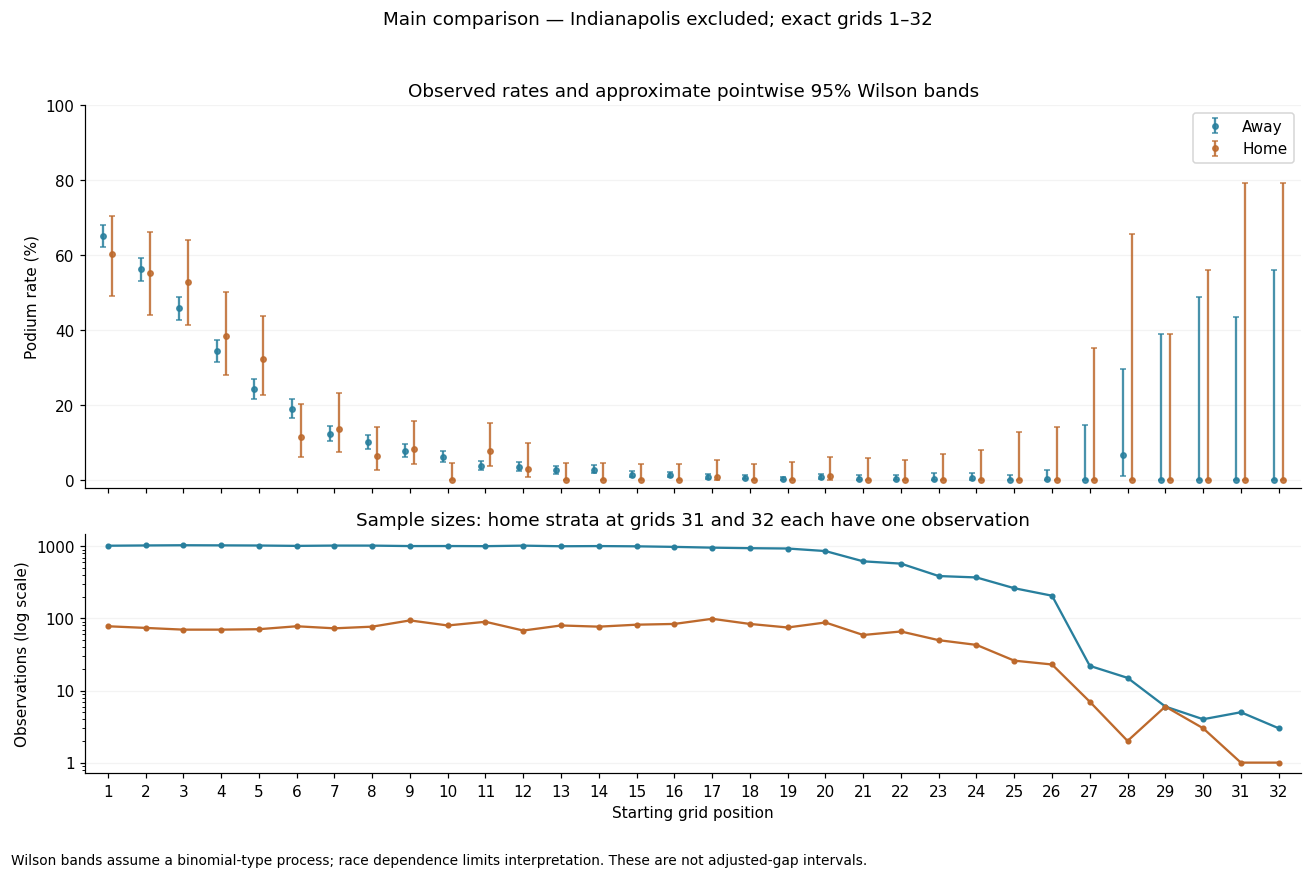

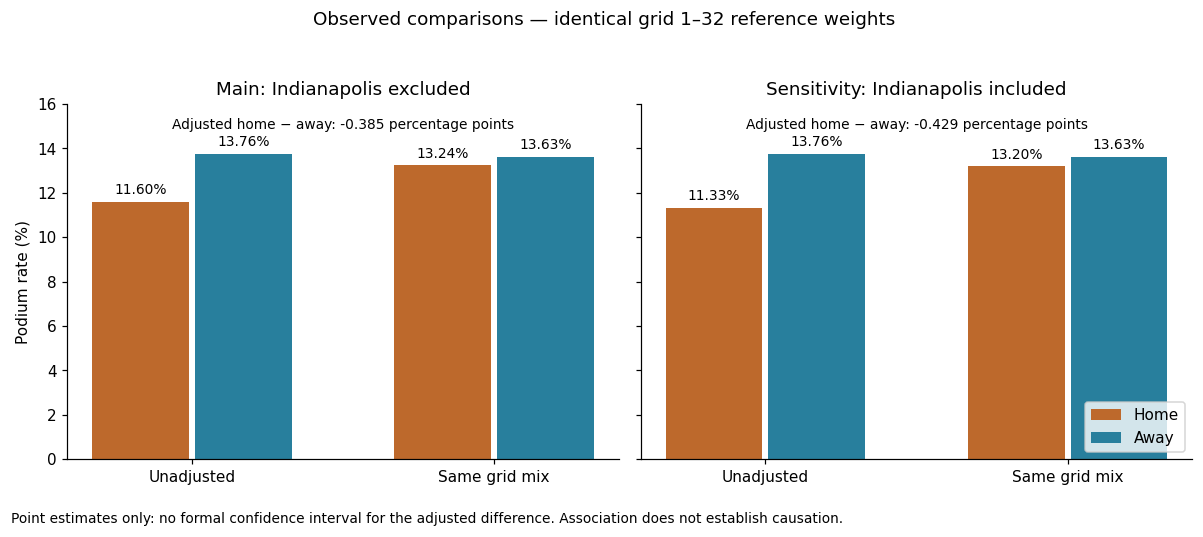

In [39]:
from matplotlib.ticker import ScalarFormatter
q2_main_grid = q2_grid_rates.loc[q2_grid_rates.population.eq('main_without_indianapolis')]
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [1.6, 1]})
for home, color, label, offset in [(False, '#287f9d', 'Away', -0.12), (True, '#bd692c', 'Home', 0.12)]:
    rows = q2_main_grid.loc[q2_main_grid.is_home_nationality.eq(home)].sort_values('grid_position')
    axes[0].errorbar(rows.grid_position + offset,
        100 * rows.podium_rate,
        yerr=np.maximum(0,
        np.vstack([100 * (rows.podium_rate - rows.wilson_low),
        100 * (rows.wilson_high - rows.podium_rate)])),
        fmt='o',
        markersize=3.5,
        capsize=2,
        color=color,
        label=label,
        alpha=0.85)
    axes[1].plot(rows.grid_position, rows.observations, 'o-', markersize=3, color=color, label=label)
axes[0].set_ylim(-2, 100)
axes[0].set_ylabel('Podium rate (%)')
axes[0].legend()
axes[0].set_title('Observed rates and approximate pointwise 95% Wilson bands')
axes[1].set_yscale('log')
axes[1].set_yticks([1, 10, 100, 1000])
axes[1].yaxis.set_major_formatter(ScalarFormatter())
axes[1].set_ylabel('Observations (log scale)')
axes[1].set_xlabel('Starting grid position')
axes[1].set_xticks(range(1, 33))
axes[1].set_xlim(0.4, 32.6)
axes[1].set_title('Sample sizes: home strata at grids 31 and 32 each have one observation')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.15)
fig.suptitle('Main comparison — Indianapolis excluded; exact grids 1–32')
fig.text(0.01,
    0.01,
    'Wilson bands assume a binomial-type process; race dependence limits interpretation. These are not adjusted-gap intervals.',
    fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, population, title in zip(axes,
    ['main_without_indianapolis',
    'with_indianapolis'],
    ['Main: Indianapolis excluded',
    'Sensitivity: Indianapolis included']):
    group = q2_summary.loc[q2_summary.population.eq(population)].set_index('is_home_nationality')
    for home, color, label, offset in [(True, '#bd692c', 'Home', -0.17), (False, '#287f9d', 'Away', 0.17)]:
        values = 100 * group.loc[home, ['unadjusted_rate', 'adjusted_rate']].to_numpy(dtype=float)
        bars = ax.bar(np.arange(2) + offset, values, width=0.32, color=color, label=label)
        ax.bar_label(bars, labels=[f'{v:.2f}%' for v in values], padding=3, fontsize=9)
    ax.set_xticks([0, 1], ['Unadjusted', 'Same grid mix'])
    ax.set_ylim(0, 16)
    ax.set_title(title)
    ax.spines[['top', 'right']].set_visible(False)
    gap = q2_difference_table.set_index('population').loc[population, 'adjusted_home_minus_away_pp']
    ax.text(0.5,
        0.96,
        f'Adjusted home − away: {gap:+.3f} percentage points',
        ha='center',
        va='top',
        transform=ax.transAxes,
        fontsize=9)
axes[0].set_ylabel('Podium rate (%)')
axes[1].legend(loc='lower right')
fig.suptitle('Observed comparisons — identical grid 1–32 reference weights')
fig.text(0.01,
    0.01,
    'Point estimates only: no formal confidence interval for the adjusted difference. Association does not establish causation.',
    fontsize=9)
fig.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()

### Answer to Question 2
- **Unadjusted:** home drivers podium **11.60% (218/1,879)** vs away **13.76% (3,092/22,469)** — a gap of **−2.16 percentage points**.
- **At the same grid mix:** home **13.24%** vs away **13.63%** — the gap shrinks to **−0.38 points**. Standardizing both groups to the same grid distribution substantially reduces the observed gap; it does not isolate the causal effect of racing at home.
- **Example of the control:** at grid 1, home drivers convert 47/78 (60.3%) and away drivers 666/1,022 (65.2%); both are weighted by the same grid-1 share (4.5%).
- **Sensitivity:** including the Indianapolis 500 changes the adjusted gap only to −0.43 points.
- **Conclusion:** in this sample the grid-standardized home rate is slightly lower, not higher. No confidence interval for this aggregate adjusted gap is calculated, so its statistical significance is not established. Positions 27–32 have fewer than 10 home observations each, and positions 31–32 each have only one. This sparse support is a limitation of an uncertainty analysis using exact grid positions. No bootstrap diagnostic is run here, so no claim about the frequency of unsupported resamples is made. Driver, constructor and era differences may also remain.

**Grain, missingness and cutoff:** one row per driver–race; unresolved nationalities and unclear grids are excluded from Q2 only. Wilson bands are per grid position and assume independent observations; no confidence interval for the adjusted gap is claimed. Home status is pre-race information, but this is a descriptive comparison, not a model feature.

## 5. Data question 3 — recorded mechanical retirements
**Question:** which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Joins:** `results` → `status` (reason) → `races` (year) → `constructors` (name) → `drivers` (for traceable examples).

**Definition:** a mechanical retirement is a **race start** that ended because a car component failed. Each status label is placed in exactly one of three groups:
1. **Mechanical** — named component failures (Engine, Gearbox, Hydraulics, Brakes, Power Unit, ERS, …).
2. **Finished or other cause** — Finished, +N Laps, Accident, Collision, Spun off, Disqualified, Illness, … (crash-, driver- and regulation-caused stops are not mechanical).
3. **Unresolved** — labels that do not identify the cause (Retired, Puncture, Damage, Wheel, Withdrew, …). These are not silently called mechanical or non-mechanical; they define a **scenario range** from "none mechanical" to "all mechanical".

**Denominator:** recorded starts. Entries marked `W` are excluded under an explicit recorded-marker rule; this is an operational denominator, not an independently reconstructed start roster; zero completed laps alone is *not* proof of a non-start (first-lap crashes and an in-race disqualification have 0 laps). Constructor IDs are kept as recorded (no team-lineage merges), and all constructors are shown with their counts.

In [40]:
q3_cause_results = analysis_tables['results'].copy()
q3_cause_races = analysis_tables['races'].copy()
q3_cause_status = analysis_tables['status'].copy()
q3_cause_drivers = analysis_tables['drivers'].copy()
q3_cause_constructors = analysis_tables['constructors'].copy()
q3_cause_source = q3_cause_results.merge(q3_cause_races[['raceId',
    'year',
    'name']].rename(columns={'name': 'race_name'}),
    on='raceId',
    how='left',
    validate='many_to_one').merge(q3_cause_status,
    on='statusId',
    how='left',
    validate='many_to_one').merge(q3_cause_drivers[['driverId',
    'forename',
    'surname']],
    on='driverId',
    how='left',
    validate='many_to_one').merge(q3_cause_constructors[['constructorId',
    'name']].rename(columns={'name': 'constructor_name'}),
    on='constructorId',
    how='left',
    validate='many_to_one')
q3_cause_source = q3_cause_source.loc[q3_cause_source.year.between(2014, 2024)].copy()
q3_mechanical_labels = {'Engine',
    'Gearbox',
    'Transmission',
    'Clutch',
    'Hydraulics',
    'Electrical',
    'Radiator',
    'Suspension',
    'Brakes',
    'Differential',
    'Overheating',
    'Mechanical',
    'Driveshaft',
    'Fuel pressure',
    'Water pressure',
    'Throttle',
    'Steering',
    'Electronics',
    'Exhaust',
    'Oil leak',
    'Water leak',
    'Fuel pump',
    'Oil pressure',
    'Fuel system',
    'Power loss',
    'Drivetrain',
    'Battery',
    'Fuel leak',
    'Turbo',
    'Water pump',
    'Spark plugs',
    'Power Unit',
    'ERS',
    'Cooling system'}
q3_unresolved_labels = {'Retired',
    'Technical',
    'Vibrations',
    'Tyre',
    'Puncture',
    'Front wing',
    'Rear wing',
    'Wheel',
    'Wheel nut',
    'Brake duct',
    'Seat',
    'Damage',
    'Undertray',
    'Out of fuel',
    'Withdrew'}
q3_explicit_other_labels = {'Finished',
    'Accident',
    'Collision',
    'Collision damage',
    'Spun off',
    'Disqualified',
    'Excluded',
    'Illness',
    'Debris'}
q3_lapped_labels = set(q3_cause_source.loc[q3_cause_source.status.str.fullmatch('[+]\\d+ Laps?'), 'status'])
q3_other_labels = q3_explicit_other_labels | q3_lapped_labels
q3_cause_mapping = {**dict.fromkeys(q3_mechanical_labels,
    'recorded_mechanical_cause'),
    **dict.fromkeys(q3_unresolved_labels,
    'unresolved_cause'),
    **dict.fromkeys(q3_other_labels,
    'completion_or_explicit_other_cause')}
q3_cause_prepared = q3_cause_source.copy(deep=True)
q3_cause_prepared['q3_cause_category'] = q3_cause_prepared.status.map(q3_cause_mapping)
q3_cause_prepared['q3_descriptive_era'] = q3_cause_prepared.year.lt(2022).map({True: '2014–2021', False: '2022–2024'})
q3_cause_summary = q3_cause_prepared.groupby(['q3_cause_category', 'q3_descriptive_era']).size().unstack(fill_value=0)
q3_cause_crosswalk = q3_cause_prepared.groupby(['statusId',
    'status',
    'q3_cause_category']).size().rename('record_count_before_start_policy').reset_index()
q3_unresolved_audit = q3_cause_prepared.loc[q3_cause_prepared.q3_cause_category.eq('unresolved_cause')].copy()
print('Recorded-cause categories BEFORE start eligibility — not retirement counts:\n', q3_cause_summary.to_string())
print('\nUnresolved label counts:\n', q3_unresolved_audit.status.value_counts().to_string())
q3_start_audit = q3_cause_prepared.groupby(['positionText',
    'status']).agg(records=('resultId',
    'size'),
    min_laps=('laps',
    'min'),
    max_laps=('laps',
    'max')).reset_index()
q3_zero_examples = q3_cause_prepared.loc[q3_cause_prepared.laps.eq(0) & q3_cause_prepared.positionText.isin(['W',
    'D']) | q3_cause_prepared.laps.eq(0) & q3_cause_prepared.status.eq('Collision') | q3_cause_prepared.status.eq('Withdrew') & q3_cause_prepared.laps.gt(0)].groupby(['status',
    'positionText']).head(2)
print('\nZero-lap records by finishing marker:\n',
    q3_cause_prepared.loc[q3_cause_prepared.laps.eq(0)].groupby('positionText').size().to_string())
print('\nW observations and recorded causes:\n',
    q3_cause_prepared.loc[q3_cause_prepared.positionText.eq('W')].groupby('q3_cause_category').size().to_string())
print('\nStart-rule examples:\n',
    q3_zero_examples[['resultId',
    'year',
    'race_name',
    'forename',
    'surname',
    'status',
    'positionText',
    'grid',
    'laps']].to_string(index=False))

Recorded-cause categories BEFORE start eligibility — not retirement counts:
 q3_descriptive_era                  2014–2021  2022–2024
q3_cause_category                                       
completion_or_explicit_other_cause       2887       1259
recorded_mechanical_cause                 297         75
unresolved_cause                           83         25

Unresolved label counts:
 status
Retired        50
Withdrew       14
Wheel          11
Puncture        7
Tyre            4
Undertray       4
Rear wing       3
Wheel nut       3
Front wing      3
Technical       2
Vibrations      2
Damage          2
Brake duct      1
Seat            1
Out of fuel     1

Zero-lap records by finishing marker:
 positionText
D      1
R    111
W     28

W observations and recorded causes:
 q3_cause_category
completion_or_explicit_other_cause     1
recorded_mechanical_cause             15
unresolved_cause                      12

Start-rule examples:
  resultId  year              race_name  forename    

### 5.1 Verify the cause taxonomy and zero-lap interpretation

The cause mapping is an explicit domain definition applied to all observed status labels, not a learned result or an assertion about independently verified incident causation. Check that the categories are disjoint and every observed label is covered. Then inspect **every zero-lap disqualification in the required eras** against lap timing and pit-stop records. A timing record supplies participation evidence even when the result table records zero completed laps; it does not authorize replacing that lap count.

In [41]:
assert not (q3_mechanical_labels & q3_unresolved_labels)
assert not (q3_mechanical_labels & q3_other_labels)
assert not (q3_unresolved_labels & q3_other_labels)
q3_unmapped_labels = sorted(set(q3_cause_source.status) - set(q3_cause_mapping))
print('Unmapped observed status labels:', q3_unmapped_labels)
assert not q3_unmapped_labels
assert q3_cause_prepared.q3_cause_category.notna().all()
assert q3_cause_crosswalk.record_count_before_start_policy.sum() == len(q3_cause_source)
show(q3_cause_crosswalk.sort_values(['q3_cause_category', 'status']))

q3_zero_disqualifications = q3_cause_source.loc[
    q3_cause_source.positionText.eq('D') & q3_cause_source.laps.eq(0),
    ['resultId', 'raceId', 'driverId', 'year', 'race_name', 'forename', 'surname', 'laps', 'status'],
].copy()
q3_timing_counts = analysis_tables['lap_times'].groupby(
    ['raceId', 'driverId']).size().rename('lap_timing_rows').reset_index()
q3_stop_counts = analysis_tables['pit_stops'].groupby(
    ['raceId', 'driverId']).size().rename('pit_stop_rows').reset_index()
q3_participation_evidence = q3_zero_disqualifications.merge(
    q3_timing_counts, on=['raceId', 'driverId'], how='left', validate='one_to_one'
).merge(q3_stop_counts, on=['raceId', 'driverId'], how='left', validate='one_to_one')
q3_participation_evidence[['lap_timing_rows', 'pit_stop_rows']] = (
    q3_participation_evidence[['lap_timing_rows', 'pit_stop_rows']].fillna(0).astype(int))
print('All zero-lap disqualifications in 2014–2024, with available participation evidence:')
show(q3_participation_evidence)

Unmapped observed status labels: []
 statusId           status                  q3_cause_category  record_count_before_start_policy
       11           +1 Lap completion_or_explicit_other_cause                              1178
       12          +2 Laps completion_or_explicit_other_cause                               208
       13          +3 Laps completion_or_explicit_other_cause                                24
       14          +4 Laps completion_or_explicit_other_cause                                 6
       15          +5 Laps completion_or_explicit_other_cause                                 1
       16          +6 Laps completion_or_explicit_other_cause                                 2
       17          +7 Laps completion_or_explicit_other_cause                                 1
       18          +8 Laps completion_or_explicit_other_cause                                 2
        3         Accident completion_or_explicit_other_cause                                85
    

In [42]:
q3_start_before = q3_cause_prepared.copy()
q3_start_prepared = q3_start_before.copy(deep=True)
q3_start_prepared['q3_is_recorded_start'] = ~q3_start_prepared.positionText.eq('W')
q3_start_prepared['q3_start_eligibility_reason'] = q3_start_prepared.q3_is_recorded_start.map({True: 'retained_non_W_recorded_start',
    False: 'withheld_W_recorded_nonstart'})
q3_start_prepared['q3_recorded_mechanical_retirement'] = q3_start_prepared.q3_is_recorded_start & q3_start_prepared.q3_cause_category.eq('recorded_mechanical_cause')
q3_start_prepared['q3_unresolved_retirement'] = q3_start_prepared.q3_is_recorded_start & q3_start_prepared.q3_cause_category.eq('unresolved_cause')
q3_starters = q3_start_prepared.loc[q3_start_prepared.q3_is_recorded_start].copy()
q3_nonstarters = q3_start_prepared.loc[~q3_start_prepared.q3_is_recorded_start].copy()
q3_start_summary = q3_start_prepared.groupby('q3_descriptive_era').agg(result_records=('resultId',
    'size'),
    recorded_starts=('q3_is_recorded_start',
    'sum'),
    recorded_mechanical_retirements=('q3_recorded_mechanical_retirement',
    'sum'),
    unresolved_retirements=('q3_unresolved_retirement',
    'sum'))
q3_start_summary['withheld_nonstarts'] = q3_start_summary.result_records - q3_start_summary.recorded_starts
print('Start policy — counts per era:\n', q3_start_summary.to_string())
q3_constructor_start_coverage = q3_starters.groupby(['constructorId',
    'constructor_name',
    'q3_descriptive_era']).size().unstack(fill_value=0).reset_index()
q3_constructor_years = q3_starters.groupby(['constructorId',
    'constructor_name',
    'year']).size().rename('recorded_starts').reset_index()
q3_first_era_ids = set(q3_constructor_start_coverage.loc[q3_constructor_start_coverage['2014–2021'].gt(0), 'constructorId'])
q3_second_era_ids = set(q3_constructor_start_coverage.loc[q3_constructor_start_coverage['2022–2024'].gt(0), 'constructorId'])
q3_common_constructor_ids = q3_first_era_ids & q3_second_era_ids
q3_constructor_start_coverage['present_in_both_eras'] = q3_constructor_start_coverage.constructorId.isin(q3_common_constructor_ids)
print('\nConstructor coverage after start eligibility:\n', q3_constructor_start_coverage.to_string(index=False))
print('Distinct constructor IDs:',
    len(q3_first_era_ids | q3_second_era_ids),
    '| Earlier:',
    len(q3_first_era_ids),
    '| Later:',
    len(q3_second_era_ids),
    '| Common:',
    len(q3_common_constructor_ids))
print('\nSauber and Alfa Romeo year coverage (original IDs retained):\n',
    q3_constructor_years.loc[q3_constructor_years.constructorId.isin([15,
    51])].to_string(index=False))

Start policy — counts per era:
                     result_records  recorded_starts  recorded_mechanical_retirements  unresolved_retirements  withheld_nonstarts
q3_descriptive_era                                                                                                              
2014–2021                     3267             3246                              285                      75                  21
2022–2024                     1359             1352                               72                      21                   7

Constructor coverage after start eligibility:
  constructorId constructor_name  2014–2021  2022–2024  present_in_both_eras
             1          McLaren        316        136                  True
             3         Williams        319        134                  True
             4          Renault        199          0                 False
             5       Toro Rosso        242          0                 False
             6          

**Observed:** 28 `W` entries are removed from the denominator, leaving 3,246 starts in 2014–2021 and 1,352 in 2022–2024, with **285** and **72** recorded mechanical retirements (8.8% and 5.3% of starts) plus 75 and 21 unresolved retirements. 20 constructor IDs appear, 11 in both eras; some IDs cover only part of an era (e.g. Sauber 2014–2018 and 2024, Alfa Romeo 2019–2023), so contributing years are shown next to every rate.

In [43]:
from fractions import Fraction
from scipy.stats import binomtest
q3_result_starts = q3_starters.copy()
q3_constructor_results = q3_result_starts.groupby(['constructorId',
    'constructor_name',
    'q3_descriptive_era']).agg(starts=('resultId',
    'size'),
    race_count=('raceId',
    'nunique'),
    mechanical_retirements=('q3_recorded_mechanical_retirement',
    'sum'),
    unresolved_retirements=('q3_unresolved_retirement',
    'sum'),
    contributing_years=('year',
    lambda values: ', '.join((str(y) for y in sorted(values.unique()))))).reset_index()
q3_constructor_results['completion_or_other_starts'] = q3_constructor_results.starts - q3_constructor_results.mechanical_retirements - q3_constructor_results.unresolved_retirements
q3_constructor_results['recorded_mechanical_rate'] = q3_constructor_results.mechanical_retirements / q3_constructor_results.starts
q3_constructor_results['unresolved_rate'] = q3_constructor_results.unresolved_retirements / q3_constructor_results.starts
q3_constructor_results['scenario_low'] = q3_constructor_results.recorded_mechanical_rate
q3_constructor_results['scenario_high'] = (q3_constructor_results.mechanical_retirements + q3_constructor_results.unresolved_retirements) / q3_constructor_results.starts
q3_wilson = [binomtest(int(k),
    int(n)).proportion_ci(confidence_level=0.95,
    method='wilson') for k,
    n in zip(q3_constructor_results.mechanical_retirements,
    q3_constructor_results.starts)]
q3_constructor_results['wilson_low'] = [ci.low for ci in q3_wilson]
q3_constructor_results['wilson_high'] = [ci.high for ci in q3_wilson]
q3_constructor_results['recorded_rate_rank'] = 0
for era, indices in q3_constructor_results.groupby('q3_descriptive_era').groups.items():
    fractions = {idx: Fraction(int(q3_constructor_results.loc[idx,
        'mechanical_retirements']),
        int(q3_constructor_results.loc[idx,
        'starts'])) for idx in indices}
    for idx, value in fractions.items():
        q3_constructor_results.loc[idx, 'recorded_rate_rank'] = 1 + sum((other > value for other in fractions.values()))
q3_constructor_results = q3_constructor_results.sort_values(['q3_descriptive_era',
    'recorded_rate_rank',
    'constructorId']).reset_index(drop=True)
q3_id_sets = [set(q3_constructor_results.loc[q3_constructor_results.q3_descriptive_era.eq(era),
    'constructorId']) for era in ['2014–2021',
    '2022–2024']]
q3_common_ids = q3_id_sets[0] & q3_id_sets[1]
q3_earlier = q3_constructor_results.loc[q3_constructor_results.q3_descriptive_era.eq('2014–2021')].set_index('constructorId')
q3_later = q3_constructor_results.loc[q3_constructor_results.q3_descriptive_era.eq('2022–2024')].set_index('constructorId')
q3_common_change = q3_earlier.loc[sorted(q3_common_ids),
    ['constructor_name',
    'starts',
    'mechanical_retirements',
    'recorded_mechanical_rate',
    'contributing_years',
    'scenario_low',
    'scenario_high']].add_suffix('_earlier').join(q3_later.loc[sorted(q3_common_ids),
    ['constructor_name',
    'starts',
    'mechanical_retirements',
    'recorded_mechanical_rate',
    'contributing_years',
    'scenario_low',
    'scenario_high']].add_suffix('_later'))
q3_common_change['change_pp'] = 100 * (q3_common_change.recorded_mechanical_rate_later - q3_common_change.recorded_mechanical_rate_earlier)
q3_common_change['classification_change_min_pp'] = 100 * (q3_common_change.scenario_low_later - q3_common_change.scenario_high_earlier)
q3_common_change['classification_change_max_pp'] = 100 * (q3_common_change.scenario_high_later - q3_common_change.scenario_low_earlier)
q3_common_change = q3_common_change.reset_index().sort_values('change_pp')
q3_all_constructor_comparison = q3_earlier[['constructor_name',
    'starts',
    'recorded_mechanical_rate']].add_suffix('_earlier').join(q3_later[['constructor_name',
    'starts',
    'recorded_mechanical_rate']].add_suffix('_later'),
    how='outer').reset_index()
print('All constructor-era results:\n',
    q3_constructor_results[['constructor_name',
    'q3_descriptive_era',
    'starts',
    'mechanical_retirements',
    'unresolved_retirements',
    'recorded_mechanical_rate',
    'scenario_high',
    'recorded_rate_rank',
    'contributing_years']].to_string(index=False))
print('\nCommon constructor changes — percentage points:\n',
    q3_common_change[['constructorId',
    'constructor_name_earlier',
    'starts_earlier',
    'starts_later',
    'change_pp',
    'classification_change_min_pp',
    'classification_change_max_pp']].to_string(index=False))
print('\nEra leaders:\n', q3_constructor_results.loc[q3_constructor_results.recorded_rate_rank.eq(1)].to_string(index=False))

All constructor-era results:
 constructor_name q3_descriptive_era  starts  mechanical_retirements  unresolved_retirements  recorded_mechanical_rate  scenario_high  recorded_rate_rank                             contributing_years
        Caterham          2014–2021      33                       7                       3                  0.212121       0.303030                   1                                           2014
        Lotus F1          2014–2021      75                      13                       5                  0.173333       0.240000                   2                                     2014, 2015
      Toro Rosso          2014–2021     242                      39                       5                  0.161157       0.181818                   3             2014, 2015, 2016, 2017, 2018, 2019
         Renault          2014–2021     199                      26                       6                  0.130653       0.160804                   4                  

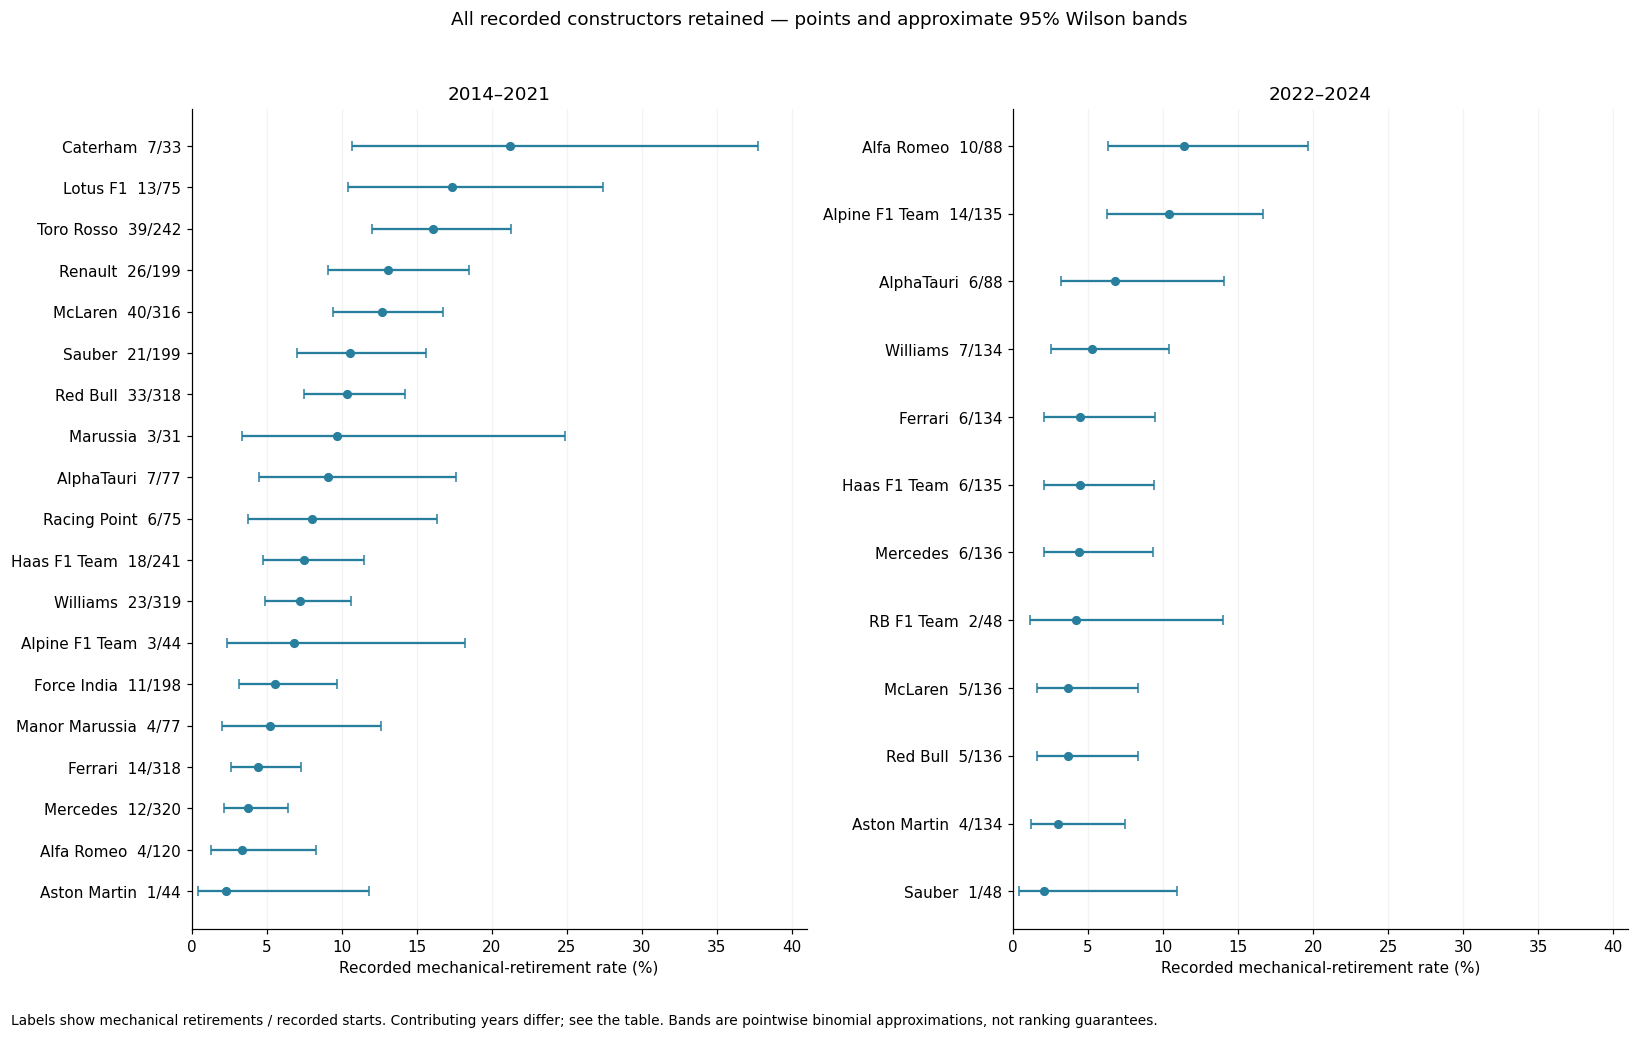

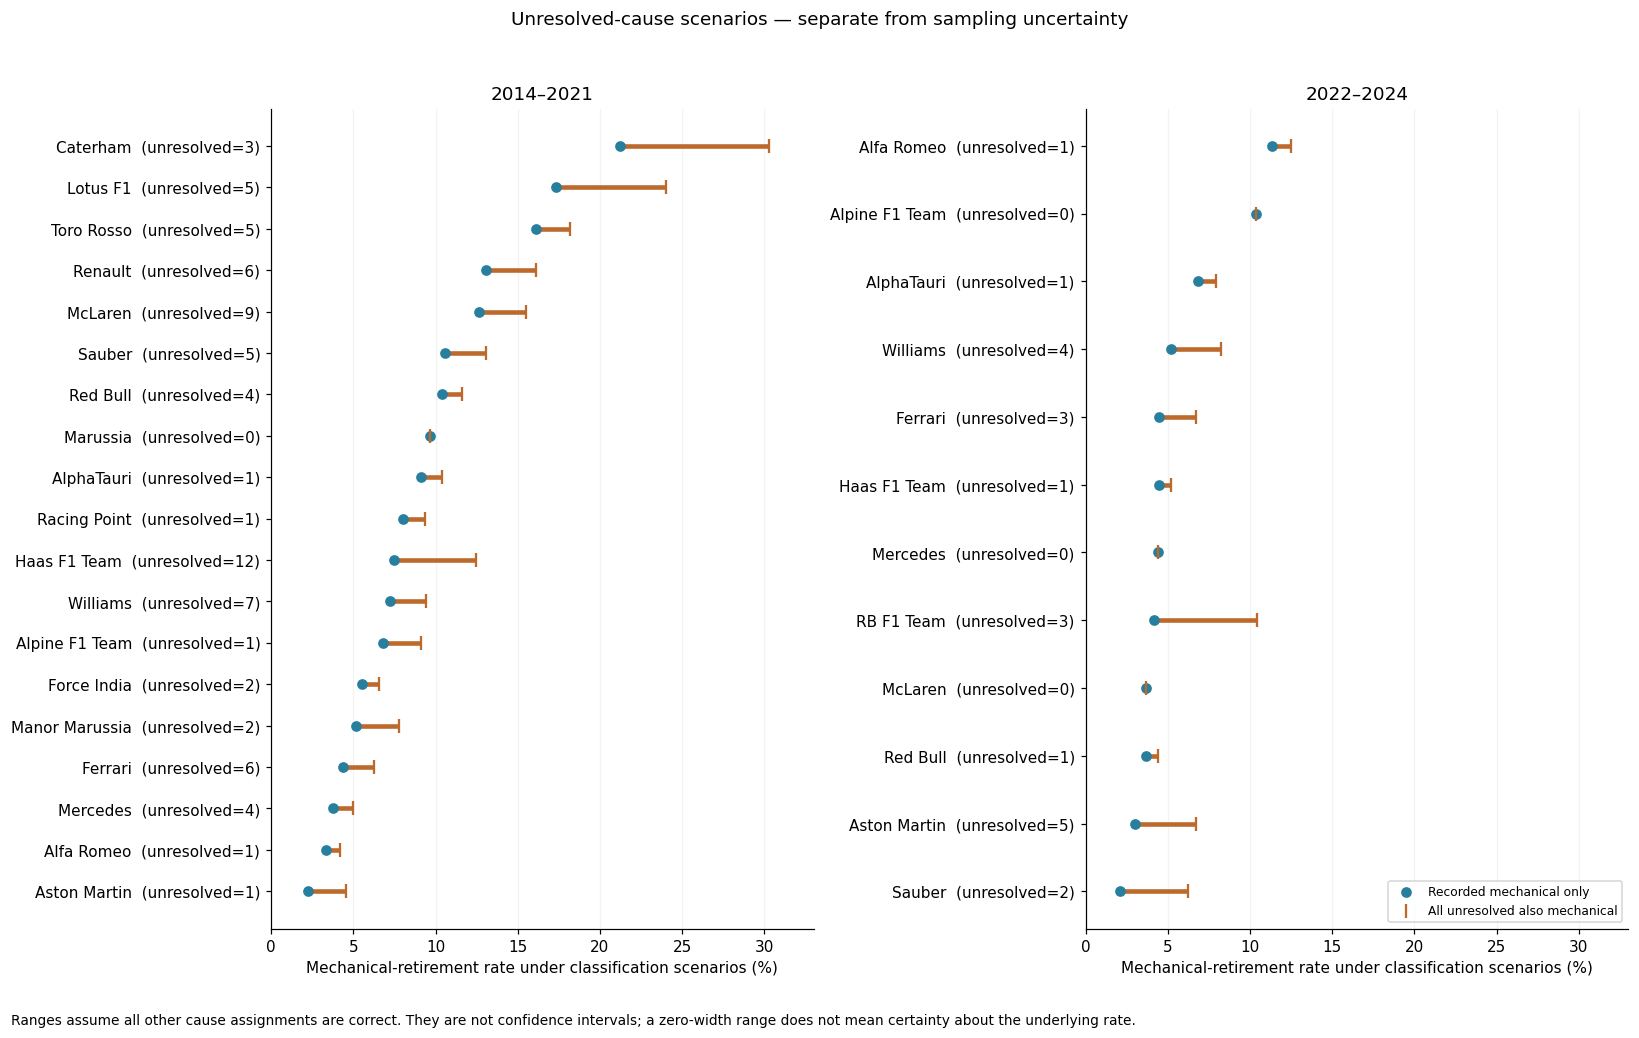

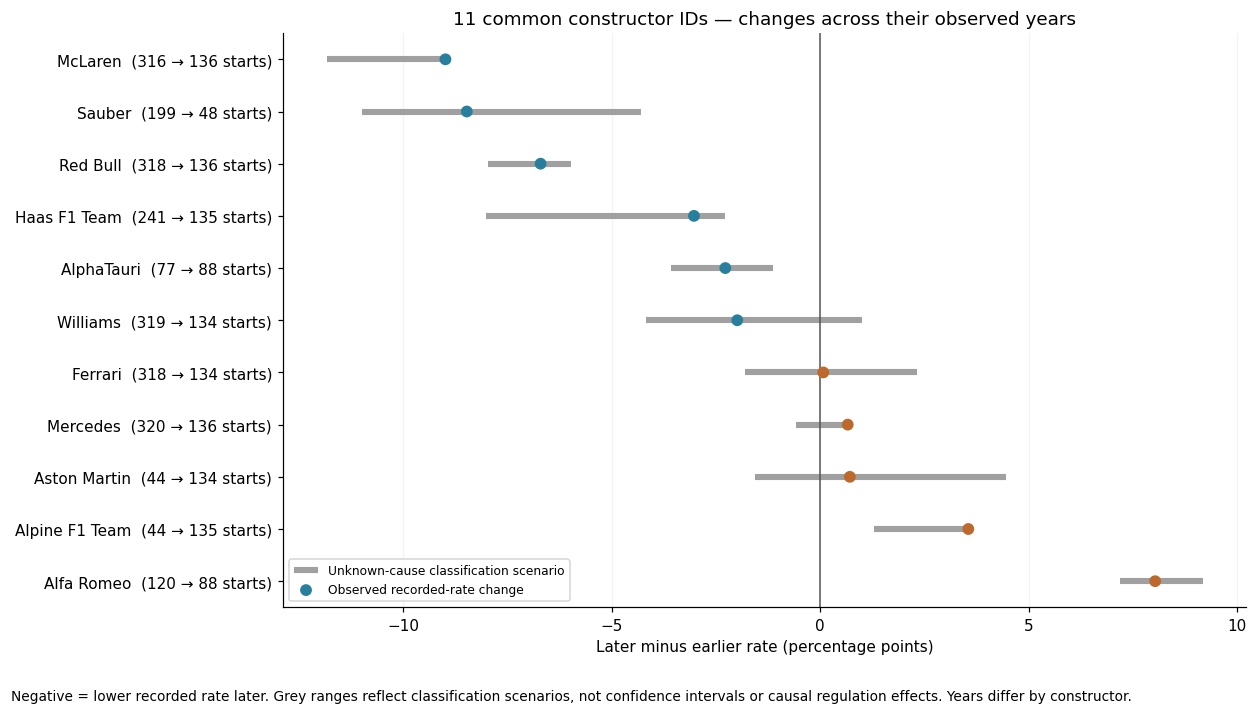

In [44]:
q3_eras = ['2014–2021', '2022–2024']
fig, axes = plt.subplots(1, 2, figsize=(15, 9.5), sharex=True)
for ax, era in zip(axes, q3_eras):
    rows = q3_constructor_results.loc[q3_constructor_results.q3_descriptive_era.eq(era)].sort_values(['recorded_rate_rank',
        'constructorId'])
    y = np.arange(len(rows))
    rate = 100 * rows.recorded_mechanical_rate.to_numpy()
    ax.errorbar(rate,
        y,
        xerr=np.vstack([rate - 100 * rows.wilson_low.to_numpy(),
        100 * rows.wilson_high.to_numpy() - rate]),
        fmt='o',
        capsize=3,
        color='#287f9d',
        markersize=5)
    ax.set_yticks(y, [f'{row.constructor_name}  {row.mechanical_retirements}/{row.starts}' for row in rows.itertuples()])
    ax.invert_yaxis()
    ax.set_title(era)
    ax.set_xlim(0, 41)
    ax.set_xlabel('Recorded mechanical-retirement rate (%)')
    ax.grid(axis='x', alpha=0.15)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('All recorded constructors retained — points and approximate 95% Wilson bands')
fig.text(0.01,
    0.01,
    'Labels show mechanical retirements / recorded starts. Contributing years differ; see the table. Bands are pointwise binomial approximations, not ranking guarantees.',
    fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 9.5), sharex=True)
for ax, era in zip(axes, q3_eras):
    rows = q3_constructor_results.loc[q3_constructor_results.q3_descriptive_era.eq(era)].sort_values(['recorded_rate_rank',
        'constructorId'])
    y = np.arange(len(rows))
    low = 100 * rows.scenario_low.to_numpy()
    high = 100 * rows.scenario_high.to_numpy()
    ax.hlines(y, low, high, color='#bd692c', linewidth=3)
    ax.scatter(low, y, color='#287f9d', label='Recorded mechanical only', zorder=3)
    ax.scatter(high, y, color='#bd692c', marker='|', s=90, label='All unresolved also mechanical', zorder=3)
    ax.set_yticks(y, [f'{row.constructor_name}  (unresolved={row.unresolved_retirements})' for row in rows.itertuples()])
    ax.invert_yaxis()
    ax.set_title(era)
    ax.set_xlim(0, 33)
    ax.set_xlabel('Mechanical-retirement rate under classification scenarios (%)')
    ax.grid(axis='x', alpha=0.15)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].legend(loc='lower right', fontsize=8)
fig.suptitle('Unresolved-cause scenarios — separate from sampling uncertainty')
fig.text(0.01,
    0.01,
    'Ranges assume all other cause assignments are correct. They are not confidence intervals; a zero-width range does not mean certainty about the underlying rate.',
    fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()
rows = q3_common_change.sort_values('change_pp')
y = np.arange(len(rows))
changes = rows.change_pp.to_numpy()
fig, ax = plt.subplots(figsize=(11.5, 6.5))
ax.hlines(y,
    rows.classification_change_min_pp,
    rows.classification_change_max_pp,
    color='#a0a0a0',
    linewidth=4,
    label='Unknown-cause classification scenario')
ax.scatter(changes,
    y,
    color=np.where(changes < 0,
    '#287f9d',
    '#bd692c'),
    s=45,
    zorder=3,
    label='Observed recorded-rate change')
ax.axvline(0, color='#555', linewidth=1)
ax.set_yticks(y,
    [f'{r.constructor_name_earlier}  ({r.starts_earlier} → {r.starts_later} starts)' for r in rows.itertuples()])
ax.invert_yaxis()
ax.set_xlabel('Later minus earlier rate (percentage points)')
ax.set_title('11 common constructor IDs — changes across their observed years')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.15)
ax.legend(loc='lower left', fontsize=8)
fig.text(0.01,
    0.01,
    'Negative = lower recorded rate later. Grey ranges reflect classification scenarios, not confidence intervals or causal regulation effects. Years differ by constructor.',
    fontsize=9)
fig.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

### Answer to Question 3
- **2014–2021:** highest recorded mechanical-retirement rates are **Caterham 7/33 = 21.2%** (2014 only), **Lotus F1 13/75 = 17.3%** and **Toro Rosso 39/242 = 16.1%**.
- **2022–2024:** **Alfa Romeo 10/88 = 11.4%**, **Alpine 14/135 = 10.4%** and **AlphaTauri 6/88 = 6.8%**.
- **Recorded mechanical-retirement rates were lower:** 8.8% under the defined start/cause rules in 2014–2021 vs 5.3% in 2022–2024. This is descriptive and does not isolate improvements from changing constructors, schedules or classification coverage. Among the 11 constructors in both eras, **McLaren** fell the most (12.7% → 3.7%, −9.0 points) and **Alfa Romeo** rose the most (3.3% → 11.4%, +8.0 points).
- **Robustness:** Caterham leads both on recorded mechanical causes (21.2% vs Lotus 17.3%) and when every unresolved retirement is counted as mechanical (30.3% vs 24.0%). Its lead is sensitive only to *mixed* assignments: if Lotus F1's unresolved retirements were mechanical but Caterham's were not, Lotus (24.0%) would exceed Caterham (21.2%). Alfa Romeo's later-era lead holds under every unresolved-cause scenario.

**Grain, missingness and cutoff:** one row per recorded start; unresolved causes are shown as a range, not hidden. Wilson bands describe sampling uncertainty; scenario ranges describe classification uncertainty — they are different things. Status is post-race information, used here for description only and never as a model input.

## 6. Build features available before the Grand Prix
Fourteen inputs in eight groups. Each is known **after the grid is fixed and before the race starts**:

| Group | Input(s) | Why it is valid at the cutoff | Why we expect it to help |
|---|---|---|---|
| Grid | `grid_position`, `grid_zero_recorded` | Starting grid is published before the start | Q1/Q2: front-row starters podium 56–76% of the time |
| Qualifying | `qualifying_position`, `qualifying_record_present` | Qualifying ends before the race | Raw pace; differs from grid when penalties apply (Q1) |
| Driver career | `driver_prior_participations`, `driver_prior_podium_rate` | Only **earlier** races | Experience and long-run strength |
| Driver recent form | `driver_last5_podium_rate` | Driver's last 5 earlier races | Current form |
| Constructor recent form | `constructor_last5_races_podium_rate` | Team's last 5 earlier races | Recent constructor performance; its association is inspected below |
| Driver circuit history | `driver_circuit_prior_participations`, `driver_circuit_prior_podium_rate` | Earlier visits to this circuit | Track-specific strength |
| Driver standings | `driver_prior_GP_season_points/rank` | Latest available **earlier GP** snapshot for this entity in the same season | Season-level strength |
| Constructor standings | `constructor_prior_GP_season_points/rank` | Latest available **earlier GP** snapshot for this entity in the same season | Season-level car strength |

**Leakage controls:**
- Histories are built on the **full 1950–2024 timeline in date order**: for each race, every entrant's features are snapshot **first**, and only then is that race's result used to update history for later races. A driver's own result — or a teammate's — can never enter the current row.
- Standings use an *as-of* join that forbids same-date matches, so the current race's post-race standings are never used; season points reset to 0 at each season opener.
- Histories are computed before the train/validation/test split, so a veteran is not reset to a rookie when a training window starts.

**Population:** prediction rows exclude pairs whose every record is `F` (failed to qualify), under a retrospective recorded-marker cohort rule. This does not claim to reconstruct an official pre-start roster. Historical updates also ignore `W` entries without completed laps. The two rules answer different questions, so they are kept separate. Raw lap times, sprint results, IDs and any same-race outcome are deliberately **not** used.

In [45]:
from collections import defaultdict, deque
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve,
    roc_auc_score, auc, f1_score, precision_score, recall_score,
    confusion_matrix, roc_curve, log_loss)
from scipy.special import expit
from threadpoolctl import threadpool_limits
import copy
import numbers
import warnings
from io import StringIO

# The baseline logistic model is fitted on a DataFrame and later scored on NumPy arrays;
# the resulting 'feature names' warning is harmless, so it is silenced for readability.
warnings.filterwarnings('ignore', message='X does not have valid feature names')

def reference_precision(frame):
    # Preserve the original notebook's pandas CSV numeric parsing at its
    # feature-table boundaries, without creating intermediate files. Tiny
    # rounding changes can alter a numerical optimizer's stopping point.
    return pd.read_csv(StringIO(frame.to_csv(index=False)))

SEED = 20261017
THRESHOLD = 0.5
KEYS = ['raceId', 'driverId']
race_calendar = analysis_tables['races'][['raceId', 'year', 'round', 'date', 'circuitId']].rename(
    columns={'date': 'race_date'}).sort_values(['race_date', 'year', 'round', 'raceId']).reset_index(drop=True)
race_calendar['race_sequence'] = np.arange(1, len(race_calendar) + 1)
full_index = analysis_driver_race[KEYS + ['constructorId']].merge(
    race_calendar, on='raceId', validate='many_to_one').sort_values(
    ['race_sequence', 'driverId']).reset_index(drop=True)
source_results = analysis_tables['results'].copy()
source_results['history_source_eligible'] = (~source_results.positionText.eq('F')) & (
    ~source_results.positionText.eq('W') | source_results.laps.gt(0))
history_eligibility = source_results.groupby(KEYS, as_index=False).agg(
    history_source_eligible=('history_source_eligible', 'any'))
full_timeline = full_index.merge(analysis_driver_race[KEYS + ['podium']], on=KEYS,
    validate='one_to_one').merge(history_eligibility, on=KEYS, validate='one_to_one')

### History and prediction membership: inspect the source markers

History updates and prediction membership answer different questions. Inspect the complete source table before filtering: ordinary recorded participations update history, `F` stays withheld even if laps conflict, and `W` updates history only with positive recorded laps. Zero-lap `R`/`D` records are not excluded solely because of their lap count. Prediction membership excludes only pairs whose every source record is `F`. These rules leave the original records and identities intact.

In [46]:
history_marker_evidence = source_results.merge(
    analysis_tables['status'], on='statusId', validate='many_to_one'
).merge(
    analysis_tables['races'][['raceId', 'year', 'name']].rename(columns={'name': 'race_name'}),
    on='raceId', validate='many_to_one'
).merge(
    analysis_tables['drivers'][['driverId', 'forename', 'surname']],
    on='driverId', validate='many_to_one')
history_marker_summary = history_marker_evidence.assign(
    positive_laps=history_marker_evidence.laps.gt(0)
).groupby(['positionText', 'status']).agg(
    source_rows=('resultId', 'size'), positive_lap_rows=('positive_laps', 'sum'),
    history_update_rows=('history_source_eligible', 'sum')).reset_index()
print('F/W marker groups, scanned over the entire source table:')
show(history_marker_summary.loc[history_marker_summary.positionText.isin(['F', 'W'])])
history_marker_exceptions = history_marker_evidence.loc[
    history_marker_evidence.positionText.isin(['F', 'W']) & history_marker_evidence.laps.gt(0),
    ['raceId', 'driverId', 'year', 'race_name', 'forename', 'surname', 'positionText',
     'status', 'laps', 'history_source_eligible'],
]
print('Every F/W record with positive laps, selected by source fields:')
show(history_marker_exceptions)
assert not source_results.loc[source_results.positionText.eq('F'), 'history_source_eligible'].any()
assert source_results.loc[
    source_results.positionText.eq('W') & source_results.laps.gt(0), 'history_source_eligible'].all()
assert not source_results.loc[
    source_results.positionText.eq('W') & ~source_results.laps.gt(0), 'history_source_eligible'].any()
assert source_results.loc[
    source_results.positionText.isin(['R', 'D']) & source_results.laps.eq(0), 'history_source_eligible'].all()

history_pair_summary = history_eligibility.groupby('history_source_eligible').size().rename('driver_race_pairs')
prediction_pair_flags = source_results.assign(is_F=source_results.positionText.eq('F')).groupby(KEYS).is_F.all()
population_rule_summary = pd.DataFrame([
    {'population': 'Full unique driver–race view', 'pairs': len(full_index)},
    {'population': 'Eligible to update later-race history', 'pairs': int(history_eligibility.history_source_eligible.sum())},
    {'population': 'Withheld from history updates', 'pairs': int((~history_eligibility.history_source_eligible).sum())},
    {'population': 'Retained for prediction', 'pairs': int((~prediction_pair_flags).sum())},
    {'population': 'Excluded from prediction: every source F', 'pairs': int(prediction_pair_flags.sum())},
])
show(population_rule_summary)
assert len(history_eligibility) == len(full_index)

F/W marker groups, scanned over the entire source table:
positionText             status  source_rows  positive_lap_rows  history_update_rows
           F          107% Rule            9                  0                    0
           F Did not prequalify          331                  0                    0
           F    Did not qualify         1025                  1                    0
           F             Injury            3                  0                    0
           W           Accident           29                  0                    0
           W             Brakes            1                  0                    0
           W             Clutch            1                  0                    0
           W          Collision            4                  0                    0
           W      Driver unwell            1                  0                    0
           W         Driveshaft            1                  0                    0
        

In [47]:
"""Six pre-race features from full-timeline, eligible driver-race history.

Outcomes/eligibility from a race update state only after every row in that
race has received its snapshot. No fit, imputation, or time-window slicing.
"""
from collections import defaultdict, deque
import numpy as np
import pandas as pd
def require_full_history(candidate, canonical_index):
    keys = ["raceId", "driverId"]
    required = keys + ["race_date", "race_sequence"]
    if any(column not in candidate.columns for column in required):
        raise ValueError("History input is missing chronology/key columns")
    if candidate.duplicated(keys).any():
        raise ValueError("History input has duplicate driver-race keys")
    expected = pd.MultiIndex.from_frame(canonical_index[keys]).sort_values()
    actual = pd.MultiIndex.from_frame(candidate[keys]).sort_values()
    if not actual.equals(expected):
        raise ValueError("History input was truncated or changed: use the full cleaned timeline before modeling-window filters")
    chronology = candidate[required].merge(canonical_index[required],
        on=keys,
        how="left",
        validate="one_to_one",
        suffixes=("_input",
        "_reference"))
    if not (chronology.race_date_input.eq(chronology.race_date_reference).all() and chronology.race_sequence_input.eq(chronology.race_sequence_reference).all()):
        raise ValueError("History chronology differs from the canonical race chronology")
    return candidate.sort_values(["race_sequence", "driverId"]).copy()

FEATURE_COLUMNS = [
    "driver_prior_participations",
    "driver_prior_podium_rate",
    "driver_last5_podium_rate",
    "constructor_last5_races_podium_rate",
    "driver_circuit_prior_participations",
    "driver_circuit_prior_podium_rate",
]
KEY_COLUMNS = ["raceId", "driverId"]


def build_history_features(timeline, canonical_index):
    """Return features and separate denominator/provenance diagnostics.

    timeline includes keys, canonical chronology/circuit, reconciled constructor,
    binary podium outcome, and the agreed history_source_eligible flag. All
    canonical pairs are retained, including those withheld from history updates.
    Constructor form uses its last five races with >=1 eligible known-ID entry;
    the rate pools driver entries (podiums / eligible entries), not race means.
    A short window uses all available prior entries/races. No history => NaN
    rate, zero participation count. An unknown current constructor => NaN form.
    """
    required = set(KEY_COLUMNS + ["race_date", "race_sequence", "circuitId",
                                  "constructorId", "podium", "history_source_eligible"])
    if not required.issubset(timeline.columns):
        raise ValueError("Missing required history fields: " + str(sorted(required - set(timeline.columns))))
    data = require_full_history(timeline, canonical_index)
    if data["podium"].isna().any() or not data["podium"].isin([0, 1]).all():
        raise ValueError("Historical podium outcomes must be complete and binary")
    if data["history_source_eligible"].isna().any() or not data["history_source_eligible"].isin([True, False]).all():
        raise ValueError("History eligibility must be complete and boolean")
    if data[["race_sequence", "race_date", "circuitId"]].isna().any().any():
        raise ValueError("Incomplete race chronology or circuit")
    races = data[["raceId", "race_sequence", "race_date", "circuitId"]].drop_duplicates()
    if races["raceId"].duplicated().any() or races["race_sequence"].duplicated().any():
        raise ValueError("Each race must have one circuit, date and sequence")
    # A date tie would need a finer cutoff/order decision rather than assuming one.
    dates = pd.to_datetime(races.sort_values("race_sequence")["race_date"], errors="raise")
    if dates.duplicated().any() or not dates.is_monotonic_increasing:
        raise ValueError("Race order requires strictly increasing completed-race dates")

    driver = defaultdict(lambda: [0, 0])  # participations, podiums
    circuit = defaultdict(lambda: [0, 0])  # (driverId, circuitId)
    recent_driver = defaultdict(lambda: deque(maxlen=5))
    recent_constructor = defaultdict(lambda: deque(maxlen=5))  # (race podiums, eligible entries)
    constructor_career_entries = defaultdict(int)  # diagnostic only, not a seventh feature
    driver_last_sequence = {}
    constructor_last_sequence = {}
    circuit_last_sequence = {}
    features, diagnostics = [], []

    for sequence, race in data.groupby("race_sequence", sort=True):
        # Phase 1: snapshot ALL entrants. This phase never reads current outcomes
        # or current history eligibility; teammates receive the same team history.
        for row in race.itertuples(index=False):
            d, c = row.driverId, row.circuitId
            constructor = None if pd.isna(row.constructorId) else int(row.constructorId)
            n, wins = driver.get(d, [0, 0])
            cn, cwins = circuit.get((d, c), [0, 0])
            recent = recent_driver.get(d, ())
            team = recent_constructor.get(constructor, ()) if constructor is not None else ()
            team_n = sum(item[1] for item in team)
            team_podiums = sum(item[0] for item in team)
            features.append({
                "raceId": row.raceId, "driverId": d,
                "driver_prior_participations": n,
                "driver_prior_podium_rate": wins / n if n else np.nan,
                "driver_last5_podium_rate": sum(recent) / len(recent) if recent else np.nan,
                "constructor_last5_races_podium_rate": team_podiums / team_n if team_n else np.nan,
                "driver_circuit_prior_participations": cn,
                "driver_circuit_prior_podium_rate": cwins / cn if cn else np.nan,
            })
            diagnostics.append({
                "raceId": row.raceId, "driverId": d, "race_sequence": sequence,
                "driver_prior_podiums": wins,
                "driver_last5_n": len(recent), "driver_last5_podiums": sum(recent),
                "constructor_last5_n_races": len(team),
                "constructor_last5_n_entries": team_n,
                "constructor_last5_podiums": team_podiums,
                "constructor_prior_known_entries": constructor_career_entries.get(constructor,
                    0) if constructor is not None else np.nan,
                "driver_circuit_prior_podiums": cwins,
                "driver_last_update_sequence": driver_last_sequence.get(d, np.nan),
                "constructor_last_update_sequence": constructor_last_sequence.get(constructor, np.nan),
                "driver_circuit_last_update_sequence": circuit_last_sequence.get((d, c), np.nan),
            })

        # Phase 2: use this completed race to update histories for LATER races.
        team_updates = defaultdict(lambda: [0, 0])
        for row in race.itertuples(index=False):
            if not row.history_source_eligible:
                continue
            d, c, podium = row.driverId, row.circuitId, int(row.podium)
            driver[d][0] += 1
            driver[d][1] += podium
            circuit[(d, c)][0] += 1
            circuit[(d, c)][1] += podium
            recent_driver[d].append(podium)
            driver_last_sequence[d] = sequence
            circuit_last_sequence[(d, c)] = sequence
            if pd.notna(row.constructorId):
                constructor = int(row.constructorId)
                team_updates[constructor][0] += podium
                team_updates[constructor][1] += 1
        # Append ONE aggregated event per team; a two-driver team is not two races.
        for constructor, (podiums, entries) in team_updates.items():
            recent_constructor[constructor].append((podiums, entries))
            constructor_career_entries[constructor] += entries
            constructor_last_sequence[constructor] = sequence

    result, audit = pd.DataFrame(features), pd.DataFrame(diagnostics)
    count_cols = ["driver_prior_participations", "driver_circuit_prior_participations"]
    result[count_cols] = result[count_cols].astype("int64")
    if len(result) != len(data) or result.duplicated(KEY_COLUMNS).any():
        raise AssertionError("History builder changed the driver-race universe")
    return result[KEY_COLUMNS + FEATURE_COLUMNS], audit

In [48]:
history_features, history_audit = build_history_features(full_timeline, full_index)
history_features = reference_precision(history_features)
all_failed = source_results.assign(is_F=source_results.positionText.eq('F')).groupby(KEYS).is_F.all()
included_keys = all_failed.loc[~all_failed].reset_index()[KEYS]
prediction_index = full_index.merge(included_keys, on=KEYS, validate='one_to_one').sort_values(
    ['race_sequence', 'driverId']).reset_index(drop=True)
prediction_view = analysis_driver_race.merge(included_keys, on=KEYS, validate='one_to_one')
print('All unique pairs:', len(full_index), '| prediction pairs:', len(prediction_index))
print('History-update eligible:', int(history_eligibility.history_source_eligible.sum()))

All unique pairs: 26668 | prediction pairs: 25302
History-update eligible: 24972


In [49]:
CURRENT_INPUT_COLUMNS = ["grid_position", "grid_zero_recorded", "qualifying_position", "qualifying_record_present"]
GRID_INPUT_KEYS = KEYS
def build_grid_qualifying_inputs(population_view,original_results,qualifying):
    """Pure row-preserving source transformation; no fitting or imputation.

    original_results must be the full source table, not a filtered model cohort.
    The ownership map uses all original positive-grid rows, including owners
    later withheld from prediction. It measures source consistency, not starters.
    """
    keys=GRID_INPUT_KEYS
    if population_view.duplicated(keys).any() or qualifying.duplicated(keys).any():
        raise ValueError("Population and qualifying must each be unique per driver-race")
    owners=original_results.loc[original_results.grid.gt(0),
        ["raceId",
        "grid",
        "driverId"]].drop_duplicates().groupby(["raceId",
        "grid"],
        as_index=False).agg(original_source_slot_drivers=("driverId",
        "nunique")).rename(columns={"grid":"grid_position"})
    audit=population_view[keys+["grid_position",
        "grid_zero_recorded",
        "grid_conflict",
        "qualifying_record_present"]].rename(columns={"grid_position":"recorded_reconciled_grid"}).copy()
    audit=audit.merge(owners.rename(columns={"grid_position":"recorded_reconciled_grid"}),
        on=["raceId",
        "recorded_reconciled_grid"],
        how="left",
        validate="many_to_one")
    audit=audit.merge(qualifying[keys+["position"]].rename(columns={"position":"qualifying_position"}),
        on=keys,
        how="left",
        validate="one_to_one",
        indicator="qualifying_source_link")
    presence=audit.qualifying_source_link.eq("both")
    if not presence.eq(audit.qualifying_record_present).all():
        raise ValueError("Qualifying source join disagrees with the recorded presence flag")
    if audit.loc[audit.recorded_reconciled_grid.notna(),"original_source_slot_drivers"].isna().any():
        raise ValueError("A numeric grid has no matching original source ownership")
    audit["source_slot_masked"]=audit.recorded_reconciled_grid.notna()&audit.original_source_slot_drivers.gt(1)
    result=audit[keys].copy()
    result["grid_position"]=audit.recorded_reconciled_grid.mask(audit.source_slot_masked)
    result["grid_zero_recorded"]=audit.grid_zero_recorded.astype(bool)
    result["qualifying_position"]=audit.qualifying_position
    result["qualifying_record_present"]=presence.astype(bool)
    audit["model_grid_position"]=result.grid_position
    if len(result)!=len(population_view):
        raise AssertionError("Current-input build changed the prediction population")
    return result[keys+CURRENT_INPUT_COLUMNS],audit

In [50]:
STANDINGS_KEYS = KEYS
STANDINGS_COLUMNS = ['driver_prior_GP_season_points',
    'driver_prior_GP_season_rank',
    'constructor_prior_GP_season_points',
    'constructor_prior_GP_season_rank']
def build_prior_gp_standings(timeline, races, driver_standings, constructor_standings):
    """Return a row-preserving feature table and a separate provenance ledger.

    Use the full race calendar, even for a subset of target rows. The calendar
    establishes the actual season opening; the earliest target row does not.
    Source-series absence for an entire season stays missing. When that series
    is recorded in the season, opening-GP points are a structural zero and rank
    is undefined. Other unavailable snapshots stay missing, including debuts or
    source omissions. Missing constructor identity stays missing.
    """
    if timeline.duplicated(STANDINGS_KEYS).any():
        raise ValueError('Target driver-race keys must be unique')
    calendar = races[['raceId', 'year', 'date']].copy()
    calendar['date'] = pd.to_datetime(calendar.date, errors='raise')
    if calendar.raceId.duplicated().any() or calendar.date.isna().any():
        raise ValueError('Race calendar needs unique IDs and complete dates')
    if calendar.duplicated(['year', 'date']).any():
        raise ValueError('Same-day GPs need an explicit event-order policy')
    calendar = calendar.sort_values(['date', 'raceId'])
    calendar['season_gp_number'] = calendar.groupby('year').cumcount() + 1
    target = timeline[STANDINGS_KEYS+['constructorId']].copy().merge(
        calendar, on='raceId', how='left', validate='many_to_one')
    if target.date.isna().any():
        raise ValueError('Every target race must link to the complete calendar')
    target['_target_order'] = np.arange(len(target))
    features = target[STANDINGS_KEYS].copy()
    ledgers = []
    for series, entity, source in [
        ('driver', 'driverId', driver_standings),
        ('constructor', 'constructorId', constructor_standings),
    ]:
        if source.duplicated(['raceId', entity]).any():
            raise ValueError(f'{series} snapshots must have unique race/entity keys')
        snapshots = source[['raceId', entity, 'points', 'position']].copy().merge(
            calendar, on='raceId', how='left', validate='many_to_one')
        if snapshots.date.isna().any() or snapshots[entity].isna().any():
            raise ValueError(f'{series} source calendar/identity link is missing')
        coverage_years = set(snapshots.year)
        snapshots = snapshots.rename(columns={
            'raceId':'source_raceId', 'date':'source_date',
            'points':'source_points', 'position':'source_rank',
            'season_gp_number':'source_season_gp_number',
        })
        known_targets = target.loc[target[entity].notna()].copy()
        known_targets[entity] = known_targets[entity].astype('int64')
        snapshots[entity] = snapshots[entity].astype('int64')
        match_cols = ['source_raceId', 'source_date', 'source_points',
                      'source_rank', 'source_season_gp_number']
        matched = pd.merge_asof(
            known_targets.sort_values('date'),
            snapshots[['year', entity]+match_cols].sort_values('source_date'),
            left_on='date', right_on='source_date', by=['year', entity],
            direction='backward', allow_exact_matches=False,
        )
        audit = target.merge(matched[['_target_order']+match_cols],
                             on='_target_order', how='left', validate='one_to_one')
        audit = audit.sort_values('_target_order').reset_index(drop=True)
        audit['series'] = series
        audit['reason'] = 'earlier_same_season_snapshot'
        audit.loc[audit.source_raceId.isna(), 'reason'] = 'no_earlier_entity_snapshot'
        audit.loc[audit.season_gp_number.eq(1), 'reason'] = 'season_opening'
        audit.loc[~audit.year.isin(coverage_years), 'reason'] = 'series_not_recorded_in_season'
        audit.loc[audit[entity].isna(), 'reason'] = 'entity_identity_unresolved'
        opening = audit.reason.eq('season_opening')
        points = audit.source_points.copy()
        rank = audit.source_rank.copy()
        points.loc[opening] = 0.0
        rank.loc[opening] = np.nan
        features[f'{series}_prior_GP_season_points'] = points
        features[f'{series}_prior_GP_season_rank'] = rank
        audit['feature_points'] = points
        audit['feature_rank'] = rank
        ledgers.append(audit.drop(columns='_target_order'))
    return features[STANDINGS_KEYS+STANDINGS_COLUMNS], pd.concat(ledgers, ignore_index=True)

In [51]:
current_features, current_audit = build_grid_qualifying_inputs(
    prediction_view, source_results, analysis_tables['qualifying'])
standings_features, standings_audit = build_prior_gp_standings(
    full_index, analysis_tables['races'], analysis_tables['driver_standings'],
    analysis_tables['constructor_standings'])
history_for_prediction = reference_precision(history_features.merge(
    included_keys, on=KEYS, validate='one_to_one'))
current_and_history = reference_precision(history_for_prediction.merge(
    current_features, on=KEYS, validate='one_to_one'))
features = reference_precision(current_and_history.merge(
    standings_features, on=KEYS, validate='one_to_one'))
data = prediction_index.merge(features, on=KEYS, validate='one_to_one').merge(
    prediction_view[KEYS + ['podium']], on=KEYS, validate='one_to_one')
assert len(data) == 25302 and not data.duplicated(KEYS).any()
assert (standings_audit.source_date.dropna() < standings_audit.loc[
    standings_audit.source_date.notna(), 'date']).all()
print(data.head().to_string(index=False))

 raceId  driverId  constructorId  year  round  race_date  circuitId  race_sequence  driver_prior_participations  driver_prior_podium_rate  driver_last5_podium_rate  constructor_last5_races_podium_rate  driver_circuit_prior_participations  driver_circuit_prior_podium_rate  grid_position  grid_zero_recorded  qualifying_position  qualifying_record_present  driver_prior_GP_season_points  driver_prior_GP_season_rank  constructor_prior_GP_season_points  constructor_prior_GP_season_rank  podium
    833       579           51.0  1950      1 1950-05-13          9              1                            0                       NaN                       NaN                                  NaN                                    0                               NaN            3.0               False                  NaN                      False                            0.0                          NaN                                 NaN                               NaN       0
    833       

### 6.0a Shared source grid slots are masked as missing model inputs
A reconciled grid can still be ambiguous when the *original* results attach **several different drivers to the same numbered slot**. The audit below includes modern cases as well as historical ones; duplicate slot assignments alone do not establish their cause. For model inputs, such grids become missing (`Unknown`) instead of selecting one driver's recorded position; the row and its label are kept. The table counts the effect on the prediction rows and displays all modern examples.

In [52]:
mask_audit = current_audit.merge(prediction_index[KEYS + ['year']], on=KEYS, validate='one_to_one').merge(
    data[KEYS + ['podium']], on=KEYS, validate='one_to_one')
mask_rows = []
for label, part in [('1950–2024', mask_audit), ('2006–2024', mask_audit.loc[mask_audit.year.ge(2006)]),
                    ('2020–2024 (validation + test)', mask_audit.loc[mask_audit.year.ge(2020)])]:
    masked = part.loc[part.source_slot_masked]
    mask_rows.append({'period': label, 'prediction_pairs': len(part),
        'missing_grid_before_masking': int(part.recorded_reconciled_grid.isna().sum()),
        'masked_shared_slot_rows': len(masked),
        'masked_slots': int(masked[['raceId', 'recorded_reconciled_grid']].drop_duplicates().shape[0]),
        'races_affected': int(masked.raceId.nunique()),
        'missing_grid_after_masking': int(part.model_grid_position.isna().sum()),
        'podium_rate_masked_rows_pct': round(100 * masked.podium.mean(), 1) if len(masked) else float('nan')})
show(pd.DataFrame(mask_rows))
mask_examples = mask_audit.loc[mask_audit.source_slot_masked & mask_audit.year.ge(2006)].merge(
    analysis_tables['races'][['raceId', 'name']], on='raceId').merge(
    analysis_tables['drivers'][['driverId', 'surname']], on='driverId')
print('\nModern masked examples (both drivers recorded on the same grid slot in the source results):')
show(mask_examples[['year', 'name', 'surname', 'recorded_reconciled_grid', 'original_source_slot_drivers',
                    'qualifying_position', 'model_grid_position']].sort_values(['year', 'name']))
assert int(mask_audit.source_slot_masked.sum()) == int((mask_audit.recorded_reconciled_grid.notna() & mask_audit.model_grid_position.isna()).sum())

                       period  prediction_pairs  missing_grid_before_masking  masked_shared_slot_rows  masked_slots  races_affected  missing_grid_after_masking  podium_rate_masked_rows_pct
                    1950–2024             25302                          370                      263           161             104                         633                         12.2
                    2006–2024              7910                           82                        6             3               3                          88                         16.7
2020–2024 (validation + test)              2139                           57                        2             1               1                          59                         50.0

Modern masked examples (both drivers recorded on the same grid slot in the source results):
 year                 name    surname  recorded_reconciled_grid  original_source_slot_drivers  qualifying_position  model_grid_position
 2015   Italian

### 6.0b Why withdrawn (`W`) entries stay in the prediction population
The prediction cohort excludes pairs whose every source record has `positionText == "F"`, under the documented **recorded-marker rule**. This is not proof that every excluded driver had no race participation: the source-marker audit above shows Hans Heyer at the 1977 German GP with `F`, "Did not qualify" and nine recorded laps. That exception is retained in the audit and remains excluded by the same rule.

A `W` marker is also a final result field, and these tables do not establish when each withdrawal became known relative to the prediction cutoff. We therefore keep `W` pairs in the retrospective prediction population rather than assume a verified pre-start withdrawal roster. The comparison below shows the membership consequences of this choice; it does not establish an official entrant list or a predictive advantage.

In [53]:
pop_marks = source_results.groupby(KEYS).agg(
    all_F=('positionText', lambda s: s.eq('F').all()),
    only_W=('positionText', lambda s: s.eq('W').all())).reset_index()
pop = full_index[KEYS + ['year']].merge(pop_marks, on=KEYS, validate='one_to_one').merge(
    history_eligibility, on=KEYS, validate='one_to_one').merge(
    analysis_driver_race[KEYS + ['grid_position', 'qualifying_record_present', 'podium']], on=KEYS, validate='one_to_one')
pop_candidates = {
    'Keep every recorded pair': pd.Series(True, index=pop.index),
    'Exclude only all-F pairs (chosen)': ~pop.all_F,
    'Reuse the history-update mask (drops W without laps)': pop.history_source_eligible,
    'Require a numbered grid': pop.grid_position.notna(),
    'Require grid and a qualifying record': pop.grid_position.notna() & pop.qualifying_record_present,
}
pop_rows = []
for name, keep in pop_candidates.items():
    kept = pop.loc[keep]
    pop_rows.append({'candidate_population': name, 'pairs': len(kept), 'pairs_2006_2024': int(kept.year.ge(2006).sum()),
        'validation_rows': int(kept.year.between(2020, 2021).sum()), 'test_rows': int(kept.year.between(2022, 2024).sum()),
        'podium_labels': int(kept.podium.sum())})
show(pd.DataFrame(pop_rows))
retained_W = data.merge(pop[KEYS + ['only_W', 'history_source_eligible']], on=KEYS, validate='one_to_one')
retained_W = retained_W.loc[retained_W.only_W & ~retained_W.history_source_eligible]
print('\nRetained W-only rows without completed laps:', len(retained_W),
      '| podium labels among them:', int(retained_W.podium.sum()),
      '| in validation:', int(retained_W.year.between(2020, 2021).sum()),
      '| in test:', int(retained_W.year.between(2022, 2024).sum()))
assert len(data) == pop_rows[1]['pairs']

                                candidate_population  pairs  pairs_2006_2024  validation_rows  test_rows  podium_labels
                            Keep every recorded pair  26668             7914              780       1359           3395
                   Exclude only all-F pairs (chosen)  25302             7910              780       1359           3395
Reuse the history-update mask (drops W without laps)  24972             7871              775       1352           3395
                             Require a numbered grid  24952             7828              763       1319           3373
                Require grid and a qualifying record  10407             7807              762       1319           1482

Retained W-only rows without completed laps: 330 | podium labels among them: 0 | in validation: 5 | in test: 7


**Observed:** requiring a numbered grid, or grid plus qualifying, changes membership with recording coverage; requiring both retains only 10,407 of the 26,668 unique pairs. Reusing the history-update mask instead of the prediction rule would remove 330 additional `W`-only pairs without completed laps, including five validation and seven test rows. The chosen rule excludes only all-`F` pairs, with the recorded exception documented above. Those 330 retained `W` pairs have no podium labels, so their inclusion lowers the positive proportion. This does not determine whether AP, F1 or ROC-AUC rises or falls; no score benefit or conservatism is inferred from the class proportion.

### 6.1 Leakage test
A feature is leakage-safe if changing the **current and all later** race outcomes leaves the current race's inputs unchanged. Below we flip every podium label from the first 2021 race onward and corrupt the standings snapshots from that race onward, rebuild all features, and compare.

In [54]:
lk_start = int(race_calendar.loc[race_calendar.year.eq(2021), 'race_sequence'].min())
lk_sequence = full_index[KEYS + ['race_sequence']]

# 1) Flip every outcome from lk_start onward and rebuild the six history features.
lk_timeline = full_timeline.copy()
lk_future = lk_timeline.race_sequence.ge(lk_start)
lk_timeline.loc[lk_future, 'podium'] = 1 - lk_timeline.loc[lk_future, 'podium']
lk_history, _ = build_history_features(lk_timeline, full_index)
lk_compare = reference_precision(history_features).merge(reference_precision(lk_history), on=KEYS,
    suffixes=('', '_perturbed')).merge(lk_sequence, on=KEYS)
lk_rows = []
for name in FEATURE_COLUMNS:
    same = np.isclose(lk_compare[name], lk_compare[name + '_perturbed'], equal_nan=True, atol=1e-12)
    up_to_now = lk_compare.race_sequence.le(lk_start)
    lk_rows.append({'feature': name, 'changed_at_or_before_perturbed_race': int((~same & up_to_now).sum()),
                    'changed_in_later_races': int((~same & ~up_to_now).sum())})

# 2) Corrupt the standings tables from lk_start onward and rebuild the four standings features.
lk_future_races = race_calendar.loc[race_calendar.race_sequence.ge(lk_start), 'raceId']
lk_ds = analysis_tables['driver_standings'].copy()
lk_cs = analysis_tables['constructor_standings'].copy()
lk_ds.loc[lk_ds.raceId.isin(lk_future_races), 'points'] += 999
lk_cs.loc[lk_cs.raceId.isin(lk_future_races), 'points'] += 999
lk_standings, _ = build_prior_gp_standings(full_index, analysis_tables['races'], lk_ds, lk_cs)
lk_compare2 = standings_features.merge(lk_standings, on=KEYS, suffixes=('', '_perturbed')).merge(lk_sequence, on=KEYS)
for name in ['driver_prior_GP_season_points', 'constructor_prior_GP_season_points']:
    same = np.isclose(lk_compare2[name], lk_compare2[name + '_perturbed'], equal_nan=True)
    up_to_now = lk_compare2.race_sequence.le(lk_start)
    lk_rows.append({'feature': name, 'changed_at_or_before_perturbed_race': int((~same & up_to_now).sum()),
                    'changed_in_later_races': int((~same & ~up_to_now).sum())})
lk_result = pd.DataFrame(lk_rows)
show(lk_result)
assert lk_result.changed_at_or_before_perturbed_race.eq(0).all(), 'Leakage: a current/past input changed'
lk_outcome_based = ~lk_result.feature.isin(['driver_prior_participations', 'driver_circuit_prior_participations'])   # counts do not depend on outcomes
assert lk_result.loc[lk_outcome_based, 'changed_in_later_races'].gt(0).all(), 'Test is vacuous: later races did not change'
print('\nLeakage test passed: perturbing a race and everything after it never changes that race\'s own inputs,')
print('while outcome-based features of later races do change (so the test is not vacuous).')
print('Participation counts never change here because they do not depend on outcomes.')

                            feature  changed_at_or_before_perturbed_race  changed_in_later_races
        driver_prior_participations                                    0                       0
           driver_prior_podium_rate                                    0                    1757
           driver_last5_podium_rate                                    0                    1765
constructor_last5_races_podium_rate                                    0                    1695
driver_circuit_prior_participations                                    0                       0
   driver_circuit_prior_podium_rate                                    0                    1005
      driver_prior_GP_season_points                                    0                    1710
 constructor_prior_GP_season_points                                    0                    1719

Leakage test passed: perturbing a race and everything after it never changes that race's own inputs,
while outcome-based featu

**Extended leakage checks:** the same test is repeated for two additional potential routes for future information: (a) flipping the **history-eligibility** flag of the perturbed race and every later race, which affects participation counts as well as rates; (b) corrupting the **championship rank** (`position`) in future standings snapshots, not only the points.

In [55]:
# (a) History eligibility from lk_start onward.
lk_timeline_elig = full_timeline.copy()
lk_future_elig = lk_timeline_elig.race_sequence.ge(lk_start)
lk_timeline_elig.loc[lk_future_elig, 'history_source_eligible'] = ~lk_timeline_elig.loc[lk_future_elig, 'history_source_eligible'].astype(bool)
lk_history_elig, _ = build_history_features(lk_timeline_elig, full_index)
lk_compare_elig = reference_precision(history_features).merge(reference_precision(lk_history_elig), on=KEYS,
    suffixes=('', '_perturbed')).merge(lk_sequence, on=KEYS)
lk_rows_ext = []
for name in FEATURE_COLUMNS:
    same = np.isclose(lk_compare_elig[name], lk_compare_elig[name + '_perturbed'], equal_nan=True, atol=1e-12)
    up_to_now = lk_compare_elig.race_sequence.le(lk_start)
    lk_rows_ext.append({'perturbation': 'history eligibility', 'feature': name,
        'changed_at_or_before_perturbed_race': int((~same & up_to_now).sum()),
        'changed_in_later_races': int((~same & ~up_to_now).sum())})

# (b) Championship rank (position) in future standings snapshots.
lk_ds_rank = analysis_tables['driver_standings'].copy()
lk_cs_rank = analysis_tables['constructor_standings'].copy()
lk_ds_rank.loc[lk_ds_rank.raceId.isin(lk_future_races), 'position'] = 999
lk_cs_rank.loc[lk_cs_rank.raceId.isin(lk_future_races), 'position'] = 999
lk_standings_rank, _ = build_prior_gp_standings(full_index, analysis_tables['races'], lk_ds_rank, lk_cs_rank)
lk_compare_rank = standings_features.merge(lk_standings_rank, on=KEYS, suffixes=('', '_perturbed')).merge(lk_sequence, on=KEYS)
for name in ['driver_prior_GP_season_rank', 'constructor_prior_GP_season_rank']:
    same = np.isclose(lk_compare_rank[name], lk_compare_rank[name + '_perturbed'], equal_nan=True)
    up_to_now = lk_compare_rank.race_sequence.le(lk_start)
    lk_rows_ext.append({'perturbation': 'standings rank', 'feature': name,
        'changed_at_or_before_perturbed_race': int((~same & up_to_now).sum()),
        'changed_in_later_races': int((~same & ~up_to_now).sum())})
lk_result_ext = pd.DataFrame(lk_rows_ext)
show(lk_result_ext)
assert lk_result_ext.changed_at_or_before_perturbed_race.eq(0).all(), 'Leakage: a current/past input changed'
assert lk_result_ext.changed_in_later_races.gt(0).all(), 'Test is vacuous: later races did not change'
print('\nExtended leakage test passed for history eligibility (all six history features) and standings rank.')

       perturbation                             feature  changed_at_or_before_perturbed_race  changed_in_later_races
history eligibility         driver_prior_participations                                    0                    1767
history eligibility            driver_prior_podium_rate                                    0                    1545
history eligibility            driver_last5_podium_rate                                    0                    1149
history eligibility constructor_last5_races_podium_rate                                    0                     874
history eligibility driver_circuit_prior_participations                                    0                    1081
history eligibility    driver_circuit_prior_podium_rate                                    0                     703
     standings rank         driver_prior_GP_season_rank                                    0                    1710
     standings rank    constructor_prior_GP_season_rank         

### 6.2 Evidence for the feature choice
Training rows only (1950–2019), so validation and test outcomes play no part in choosing features. Each panel shows the observed podium rate for one input; the dashed line is the overall training podium rate.

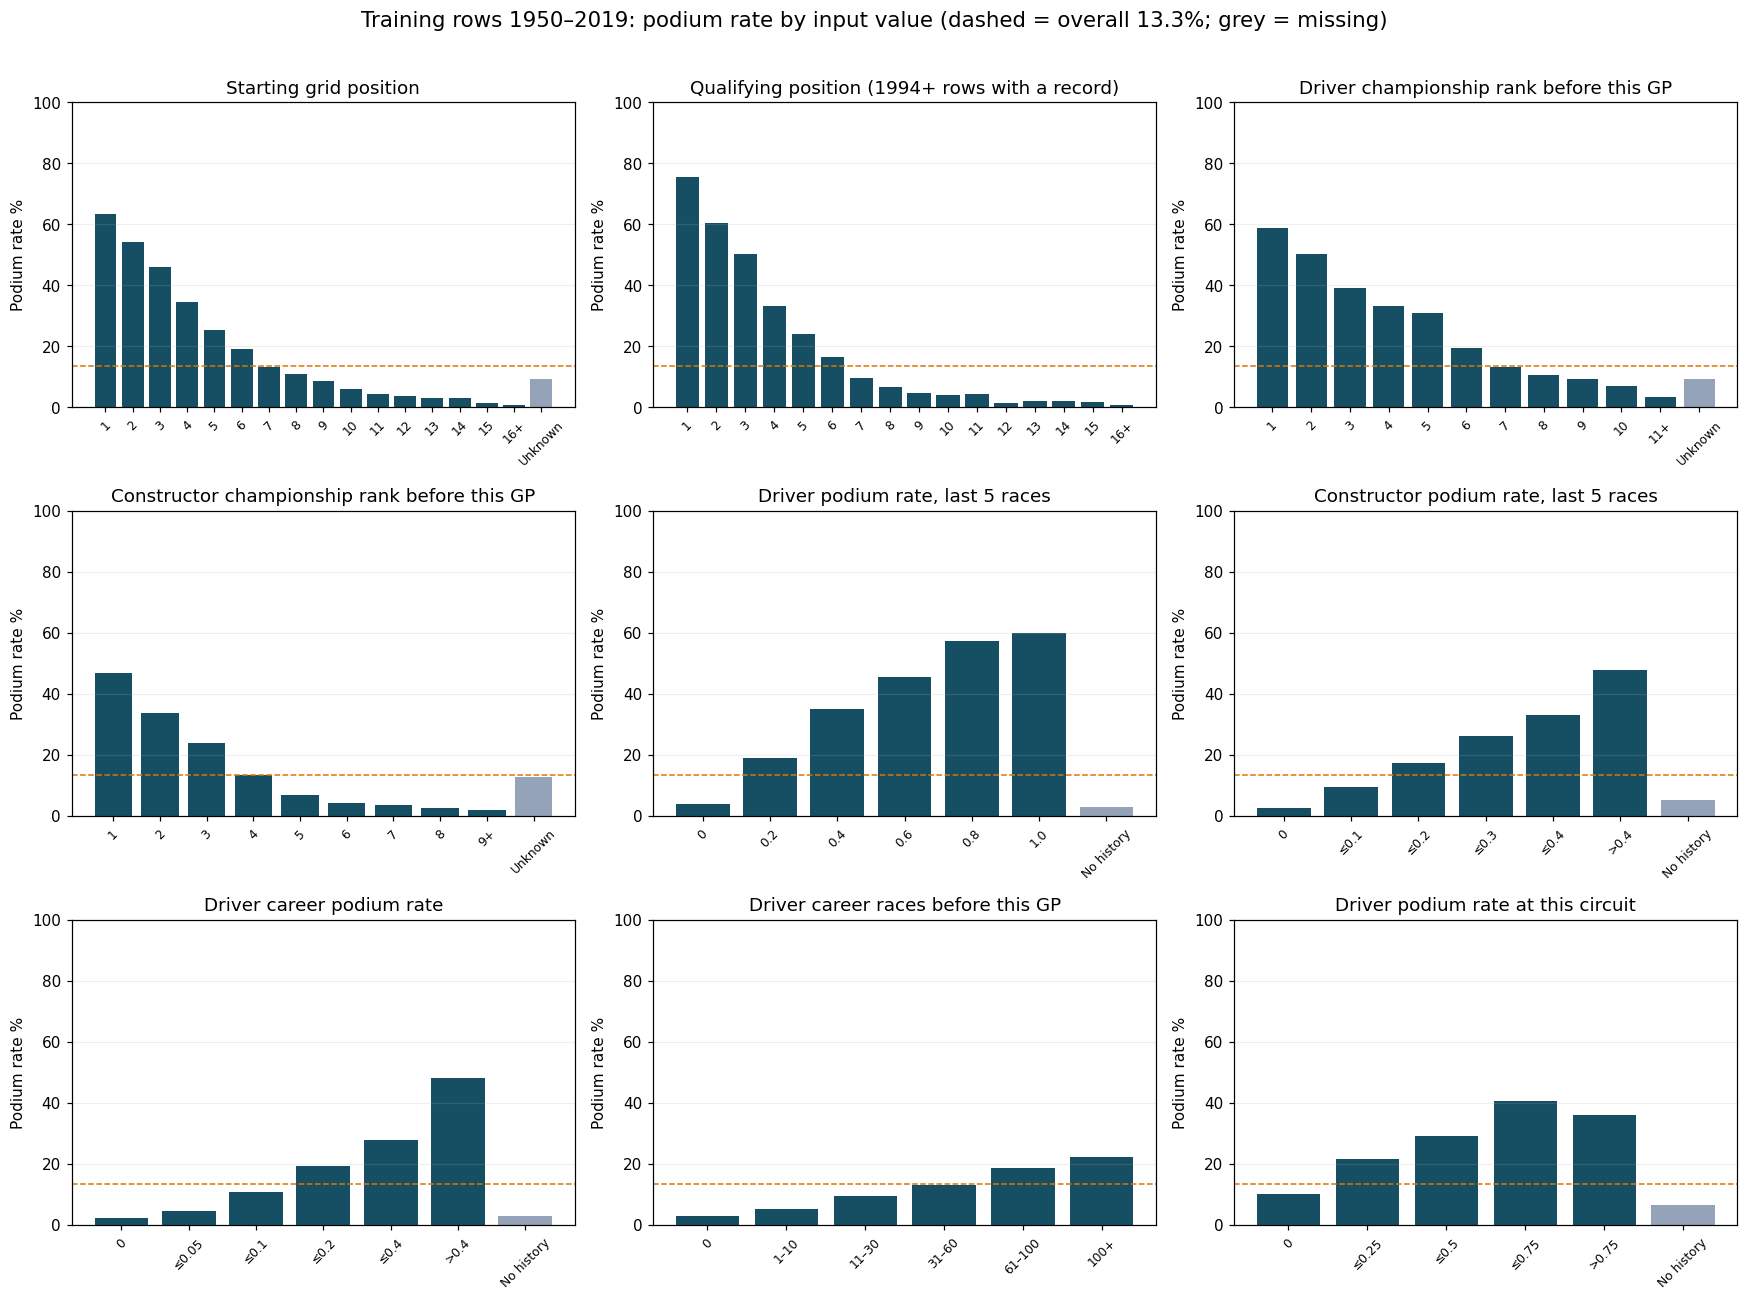

                                         input  min_bin_rate_pct  max_bin_rate_pct  rows
                        Starting grid position               0.7              63.1 23163
Qualifying position (1994+ rows with a record)               0.8              75.5  8348
       Driver championship rank before this GP               3.2              58.8 23163
  Constructor championship rank before this GP               1.8              46.7 23163
              Driver podium rate, last 5 races               2.9              59.9 23163
         Constructor podium rate, last 5 races               2.6              47.9 23163
                     Driver career podium rate               2.2              47.9 23163
            Driver career races before this GP               2.9              22.1 23163
            Driver podium rate at this circuit               6.6              40.6 23163


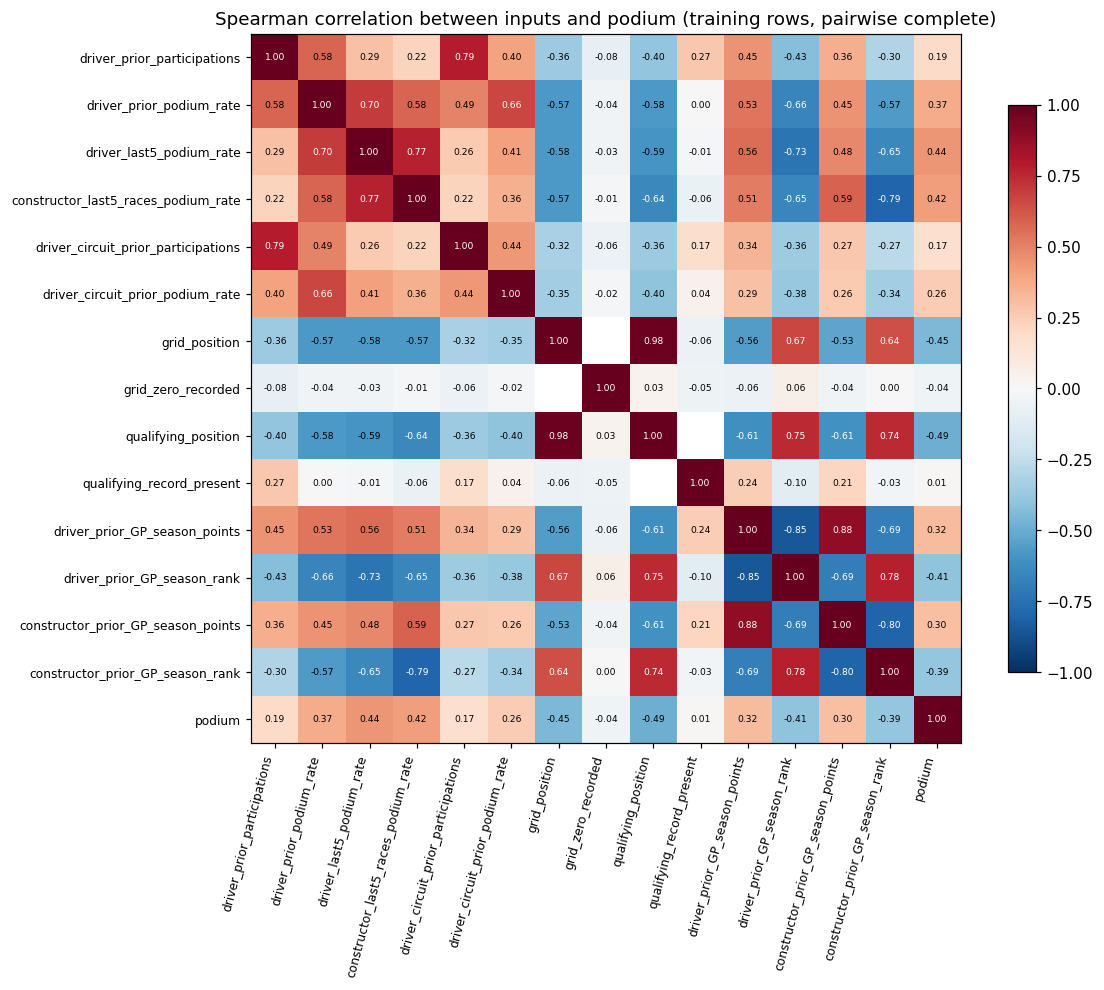

In [56]:
fe_train = data.loc[data.year.le(2019)].copy()
fe_base = fe_train.podium.mean()

def fe_position_bins(values, top):
    labels = values.map(lambda v: 'Unknown' if pd.isna(v) else (str(int(v)) if v <= top else f'{top + 1}+'))
    order = [str(i) for i in range(1, top + 1)] + [f'{top + 1}+', 'Unknown']
    return labels, order

def fe_rate_bins(values, edges, names):
    labels = pd.cut(values, edges, labels=names, include_lowest=True).astype(object)
    labels = labels.where(values.notna(), 'No history')
    return labels, names + ['No history']

fe_panels = [
    ('Starting grid position', *fe_position_bins(fe_train.grid_position, 15)),
    ('Qualifying position (1994+ rows with a record)', *fe_position_bins(
        fe_train.loc[fe_train.qualifying_record_present].qualifying_position, 15)),
    ('Driver championship rank before this GP', *fe_position_bins(fe_train.driver_prior_GP_season_rank, 10)),
    ('Constructor championship rank before this GP', *fe_position_bins(fe_train.constructor_prior_GP_season_rank, 8)),
    ('Driver podium rate, last 5 races', *fe_rate_bins(fe_train.driver_last5_podium_rate,
        [-0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0], ['0', '0.2', '0.4', '0.6', '0.8', '1.0'])),
    ('Constructor podium rate, last 5 races', *fe_rate_bins(fe_train.constructor_last5_races_podium_rate,
        [-0.01, 0.0, 0.1, 0.2, 0.3, 0.4, 1.0], ['0', '≤0.1', '≤0.2', '≤0.3', '≤0.4', '>0.4'])),
    ('Driver career podium rate', *fe_rate_bins(fe_train.driver_prior_podium_rate,
        [-0.01, 0.0, 0.05, 0.1, 0.2, 0.4, 1.0], ['0', '≤0.05', '≤0.1', '≤0.2', '≤0.4', '>0.4'])),
    ('Driver career races before this GP', *fe_rate_bins(fe_train.driver_prior_participations.astype(float),
        [-0.5, 0.5, 10, 30, 60, 100, 400], ['0', '1–10', '11–30', '31–60', '61–100', '100+'])),
    ('Driver podium rate at this circuit', *fe_rate_bins(fe_train.driver_circuit_prior_podium_rate,
        [-0.01, 0.0, 0.25, 0.5, 0.75, 1.0], ['0', '≤0.25', '≤0.5', '≤0.75', '>0.75'])),
]
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
fe_summary = []
for ax, (title, labels, order) in zip(axes.ravel(), fe_panels):
    frame = pd.DataFrame({'bin': labels, 'podium': fe_train.loc[labels.index, 'podium']})
    stats = frame.groupby('bin').podium.agg(['mean', 'size']).reindex([o for o in order if o in set(frame.bin)])
    colors = ['#94a3b8' if b in ('Unknown', 'No history') else '#164e63' for b in stats.index]
    ax.bar(stats.index.astype(str), 100 * stats['mean'], color=colors)
    ax.axhline(100 * fe_base, color='#d97706', linestyle='--', linewidth=1)
    ax.set(title=title, ylabel='Podium rate %', ylim=(0, 100))
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.grid(axis='y', alpha=0.2)
    fe_summary.append({'input': title, 'min_bin_rate_pct': 100 * stats['mean'].min(),
                       'max_bin_rate_pct': 100 * stats['mean'].max(), 'rows': int(stats['size'].sum())})
fig.suptitle(f'Training rows 1950–2019: podium rate by input value (dashed = overall {100 * fe_base:.1f}%; grey = missing)', fontsize=14)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()
show(pd.DataFrame(fe_summary).round(1))

fe_corr = fe_train[FEATURE_COLUMNS + CURRENT_INPUT_COLUMNS + STANDINGS_COLUMNS + ['podium']].astype(float).corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(fe_corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(fe_corr)), fe_corr.columns, rotation=75, ha='right', fontsize=8)
ax.set_yticks(range(len(fe_corr)), fe_corr.index, fontsize=8)
for (i, j), v in np.ndenumerate(fe_corr.to_numpy()):
    if not np.isnan(v):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=6, color='white' if abs(v) > 0.6 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Spearman correlation between inputs and podium (training rows, pairwise complete)')
plt.tight_layout()
plt.show()

**What the evidence shows (training rows only):**
- **Observed associations motivate the inputs.** Grid P1 has about 63% podium conversion versus under 1% from 16th or lower; qualifying P1 about 75%; the championship leader about 59%; and the top constructor about 47%. The driver recent-form, constructor recent-form and career-rate bins also show increasing podium rates. These are reasons to test the groups, not proof that each adds value after the other inputs are present.
- **Career length and circuit history:** career-length bins rise steadily from about 3% to 22%. Circuit-history bins show a less monotonic association, reaching about 41% before dipping in the highest-rate bin. Separate ablations below measure each complete group's incremental validation contribution.
- **Missingness stays explicit.** The grey bars display the observed podium rates for `Unknown` positions and `No history` rates. These missing states have a different meaning from a known position or a measured historical rate, so the main recipe preserves them with categories or indicators. Section 9 compares this recipe with indicators created after filling; no unshown comparison with median-valued rows is claimed.
- **Overlap between inputs:** grid versus qualifying position has Spearman correlation 0.98; driver versus constructor points 0.88; driver rank versus driver points −0.85; and constructor form versus constructor rank −0.79. Qualifying is missing for about 64% of training rows. These observations suggest overlap and coverage differences, but do not establish the cause of any later ablation result.
- **Correlations with podium:** qualifying position −0.49, grid −0.45, driver last-5 rate 0.44 and constructor last-5 rate 0.42. These are pairwise associations on available training values, not causal effects or a ranking of conditional predictive value.


## 7. Split chronologically and preprocess

**Split (by season, whole races only):** train **1950–2019**, validation **2020–2021**, test **2022–2024**.
- **Chronological, not random:** the model must predict future races from past ones. A random split would put 2023 races in training and 2019 races in testing, and drivers/teams from the same race on both sides.
- **No race is split across sets**, so teammates and rivals of one GP are always evaluated together.
- **Validation (39 races, 780 rows)** is used for every development choice: training window, model choice, NN epoch. **Test (68 races, 1,359 rows)** is scored once at the end.
- The boundaries follow the project's F1 guide and give a modern, similar-prevalence held-out period (15.0% podiums in both validation and test, vs 13.3% in training). Histories still use all earlier races, so 2020–2024 rows know a driver's full career.
- The training **start** year is not assumed: Section 8 compares 1950, 2003 (stable qualifying coverage), 2006 (Q1/Q2/Q3 format) and 2014 (hybrid era) on validation.

**Preprocessing (fitted on training rows only, then applied unchanged to validation/test):**
1. **Missingness indicators** are recorded for the six rates/points fields *before* filling, so "no history" stays visible.
2. **Median filling** for those six fields (a newcomer has no podium rate — the median is a placeholder, flagged by its indicator).
3. **Positions** (grid, qualifying, the two championship ranks) become **one-hot categories with a reserved `Unknown`**. A missing grid is not "median grid", and a rank is not a linear quantity.
4. **StandardScaler** on the eight numeric values; binary flags, indicators and one-hot columns stay 0/1.

The 14 inputs become 184 columns for the 1950 training window.

In [57]:
COUNT_COLUMNS = ['driver_prior_participations', 'driver_circuit_prior_participations']
RATE_COLUMNS = ['driver_prior_podium_rate', 'driver_last5_podium_rate',
    'constructor_last5_races_podium_rate', 'driver_circuit_prior_podium_rate']
POINT_COLUMNS = ['driver_prior_GP_season_points', 'constructor_prior_GP_season_points']
MEDIAN_COLUMNS = RATE_COLUMNS + POINT_COLUMNS
POSITION_COLUMNS = ['grid_position', 'qualifying_position',
    'driver_prior_GP_season_rank', 'constructor_prior_GP_season_rank']
FLAG_COLUMNS = ['grid_zero_recorded', 'qualifying_record_present']
INPUT_COLUMNS = FEATURE_COLUMNS + CURRENT_INPUT_COLUMNS + STANDINGS_COLUMNS
NUMERIC_COLUMNS = COUNT_COLUMNS + MEDIAN_COLUMNS

FEATURE_GROUPS = {
    'driver_career': ['driver_prior_participations', 'driver_prior_podium_rate'],
    'driver_recent_form': ['driver_last5_podium_rate'],
    'constructor_recent_form': ['constructor_last5_races_podium_rate'],
    'driver_circuit_history': ['driver_circuit_prior_participations', 'driver_circuit_prior_podium_rate'],
    'grid': ['grid_position', 'grid_zero_recorded'],
    'qualifying': ['qualifying_position', 'qualifying_record_present'],
    'driver_standings': ['driver_prior_GP_season_points', 'driver_prior_GP_season_rank'],
    'constructor_standings': ['constructor_prior_GP_season_points', 'constructor_prior_GP_season_rank'],
}
LOGISTIC_SETTINGS = dict(C=1.0, l1_ratio=0.0, solver='lbfgs', tol=1e-4,
    max_iter=5000, class_weight=None)

def position_tokens(frame):
    tokens = pd.DataFrame(index=frame.index)
    for name in POSITION_COLUMNS:
        tokens[name] = 'Unknown'
        observed = frame[name].notna()
        tokens.loc[observed, name] = frame.loc[observed, name].astype('int64').astype(str)
    return tokens

def encode_features(frame, fitted):
    frame = frame[INPUT_COLUMNS].copy()
    frame[COUNT_COLUMNS + MEDIAN_COLUMNS + POSITION_COLUMNS] = frame[
        COUNT_COLUMNS + MEDIAN_COLUMNS + POSITION_COLUMNS].astype(float)
    filled = pd.DataFrame(fitted['imputer'].transform(frame[MEDIAN_COLUMNS]),
        index=frame.index, columns=MEDIAN_COLUMNS)
    indicators = frame[MEDIAN_COLUMNS].isna().astype(float)
    indicators.columns = [name + '__was_missing' for name in MEDIAN_COLUMNS]
    positions = pd.DataFrame(fitted['encoder'].transform(position_tokens(frame)),
        index=frame.index, columns=fitted['encoder'].get_feature_names_out(POSITION_COLUMNS))
    return pd.concat([frame[COUNT_COLUMNS], filled, frame[FLAG_COLUMNS].astype(float),
        indicators, positions], axis=1).astype(float)

def fit_preprocessing(training):
    training = training[INPUT_COLUMNS].astype(float)
    imputer = SimpleImputer(strategy='median', keep_empty_features=True).fit(training[MEDIAN_COLUMNS])
    categories = [[str(int(v)) for v in sorted(training[name].dropna().unique())] + ['Unknown']
        for name in POSITION_COLUMNS]
    encoder = OneHotEncoder(categories=categories, handle_unknown='error',
        sparse_output=False, dtype=float).fit(position_tokens(training))
    fitted = {'imputer': imputer, 'encoder': encoder}
    encoded = encode_features(training, fitted)
    fitted['scaler'] = StandardScaler().fit(encoded[NUMERIC_COLUMNS])
    fitted['columns'] = encoded.columns.tolist()
    return fitted

def transform_features(frame, fitted):
    encoded = encode_features(frame, fitted)
    encoded[NUMERIC_COLUMNS] = fitted['scaler'].transform(encoded[NUMERIC_COLUMNS])
    return encoded[fitted['columns']]

splits = {
    'train': data.loc[data.year.le(2019)].copy(),
    'validation': data.loc[data.year.between(2020, 2021)].copy(),
    'test': data.loc[data.year.between(2022, 2024)].copy(),
}
assert [len(splits[s]) for s in splits] == [23163, 780, 1359]
for name, rows in splits.items():
    print(name, len(rows), 'rows;', rows.raceId.nunique(), 'races')

train 23163 rows; 1018 races
validation 780 rows; 39 races
test 1359 rows; 68 races


### 7.1 Effect of preprocessing on the values
Fitted on the training rows exactly as in the main model. The table shows each numeric input before and after; the plots compare spreads and show the standardized distributions.

                              input  missing_before  median_used  raw_min  raw_max  raw_mean  raw_std  scaled_mean  scaled_std  scaled_min  scaled_max
        driver_prior_participations               0          NaN      0.0    321.0    60.061   61.433         -0.0         1.0      -0.978       4.248
driver_circuit_prior_participations               0          NaN      0.0     18.0     2.517    3.012          0.0         1.0      -0.835       5.140
           driver_prior_podium_rate             820        0.049      0.0      1.0     0.122    0.158          0.0         1.0      -0.762       5.639
           driver_last5_podium_rate             820        0.000      0.0      1.0     0.137    0.234         -0.0         1.0      -0.569       3.750
constructor_last5_races_podium_rate             340        0.000      0.0      1.0     0.137    0.200          0.0         1.0      -0.676       4.333
   driver_circuit_prior_podium_rate            7326        0.000      0.0      1.0     0.145  

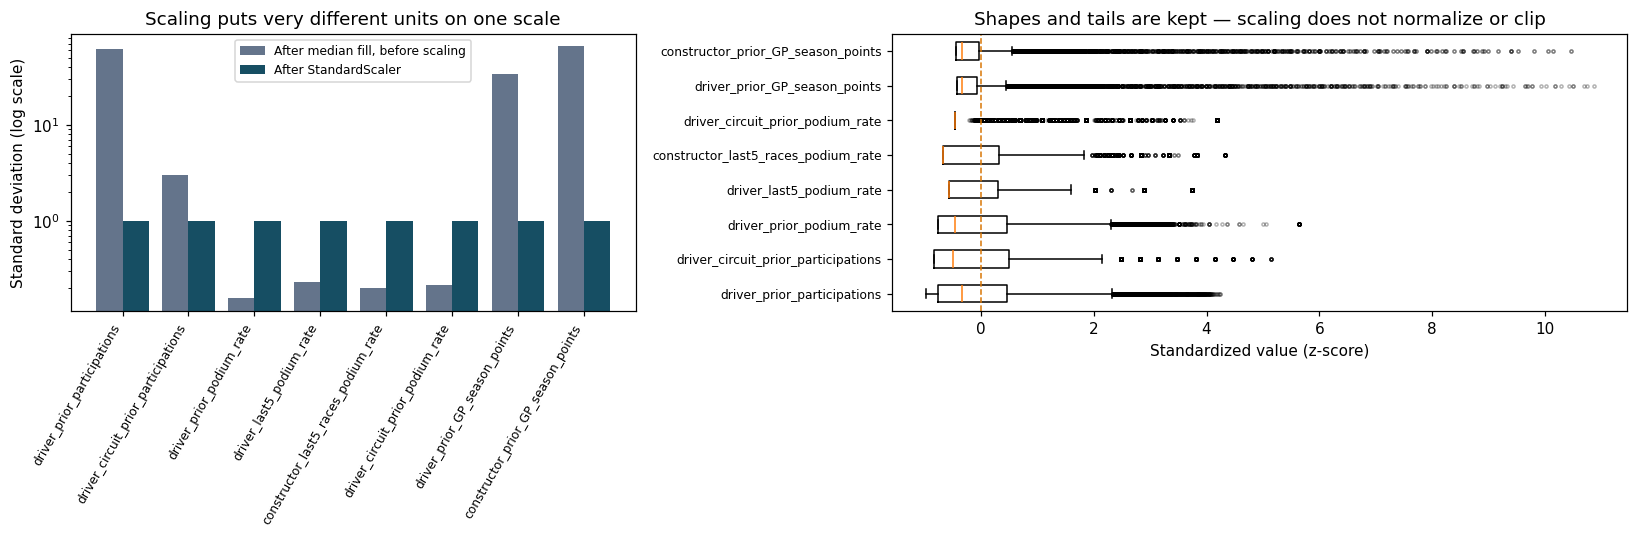

In [58]:
pp_fitted = fit_preprocessing(splits['train'])
pp_raw = splits['train'][NUMERIC_COLUMNS].astype(float)
pp_filled = encode_features(splits['train'], pp_fitted)[NUMERIC_COLUMNS]
pp_scaled = transform_features(splits['train'], pp_fitted)[NUMERIC_COLUMNS]
pp_medians = dict(zip(MEDIAN_COLUMNS, pp_fitted['imputer'].statistics_))
pp_table = pd.DataFrame({
    'missing_before': pp_raw.isna().sum(),
    'median_used': pd.Series(pp_medians),
    'raw_min': pp_raw.min(), 'raw_max': pp_raw.max(),
    'raw_mean': pp_raw.mean(), 'raw_std': pp_raw.std(ddof=0),
    'scaled_mean': pp_scaled.mean(), 'scaled_std': pp_scaled.std(ddof=0),
    'scaled_min': pp_scaled.min(), 'scaled_max': pp_scaled.max()}).loc[NUMERIC_COLUMNS]
show(pp_table.round(3).reset_index(names='input'))
pp_kinds = pd.Series({'numeric (scaled)': len(NUMERIC_COLUMNS), 'source flags (0/1)': len(FLAG_COLUMNS),
    'missingness indicators (0/1)': sum(c.endswith('__was_missing') for c in pp_fitted['columns']),
    'position one-hot incl. Unknown (0/1)': sum(any(c.startswith(p + '_') for p in POSITION_COLUMNS) for c in pp_fitted['columns'])})
print('\n14 inputs ->', len(pp_fitted['columns']), 'model columns:')
print(pp_kinds.to_string())
print('Rows with any missing value before preprocessing:', int(splits['train'][INPUT_COLUMNS].isna().any(axis=1).sum()),
      '| missing cells after preprocessing:', int(transform_features(splits['train'], pp_fitted).isna().sum().sum()))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.3]})
pos = np.arange(len(NUMERIC_COLUMNS))
axes[0].bar(pos - 0.2, pp_filled.std(ddof=0), 0.4, label='After median fill, before scaling', color='#64748b')
axes[0].bar(pos + 0.2, pp_scaled.std(ddof=0), 0.4, label='After StandardScaler', color='#164e63')
axes[0].set_yscale('log')
axes[0].set_xticks(pos, NUMERIC_COLUMNS, rotation=60, ha='right', fontsize=8)
axes[0].set(ylabel='Standard deviation (log scale)', title='Scaling puts very different units on one scale')
axes[0].legend(fontsize=8)
axes[1].boxplot([pp_scaled[c] for c in NUMERIC_COLUMNS], vert=False, tick_labels=NUMERIC_COLUMNS, flierprops={'markersize': 2, 'alpha': 0.3})
axes[1].axvline(0, color='#d97706', linestyle='--', linewidth=1)
axes[1].set(xlabel='Standardized value (z-score)', title='Shapes and tails are kept — scaling does not normalize or clip')
axes[1].tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

**Observed:** before preprocessing, 17,484 of 23,163 training rows have at least one missing input (mostly qualifying and circuit history); afterwards there are **zero missing cells** and nothing was dropped. The eight numeric inputs ranged from 0–1 (rates) to 0–722 (constructor points), with spreads differing by a factor of ~400. After StandardScaler every one has mean 0 and standard deviation 1, while their skewed shapes and long tails (points up to +10.9 SD) are kept — scaling changes units, not information. The six filled fields used training medians of 0–0.05 for rates and 3/8 for points, and each filled value keeps a missingness flag. The 14 inputs become **184 columns**: 8 scaled numeric, 2 source flags, 6 missingness indicators and 168 one-hot position categories, including `Unknown`.

In [59]:
availability_by_split = pd.DataFrame([
    {'split': split, 'rows': len(rows),
     'qualifying_records': int(rows.qualifying_record_present.sum()),
     'qualifying_record_pct': 100 * rows.qualifying_record_present.mean(),
     'recorded_grid_zero': int(rows.grid_zero_recorded.sum()),
     'unknown_model_grid': int(rows.grid_position.isna().sum()),
     'rows_with_any_missing_input': int(rows[INPUT_COLUMNS].isna().any(axis=1).sum())}
    for split, rows in splits.items()
])
show(availability_by_split)

     split  rows  qualifying_records  qualifying_record_pct  recorded_grid_zero  unknown_model_grid  rows_with_any_missing_input
     train 23163                8348              36.040237                 232                 574                        17484
validation   780                 779              99.871795                  17                  17                          267
      test  1359                1359             100.000000                  40                  42                          262


## 8. Train and compare models

### Metric choice
- **Primary: average precision (AP, a recall-weighted summary of precision).** Podiums are only 13–15% of rows, so an always-"no podium" classifier can have high accuracy while finding none. AP focuses on precision and recall for podium cases. ROC-AUC measures ranking through true-positive and false-positive rates; class imbalance does not automatically make a random ranker's ROC-AUC high. We report both AP and trapezoidal PR-AUC because they summarize the PR curve differently.
- **Secondary: F1 at threshold 0.5.** Turns probabilities into yes/no decisions and balances false podium calls against missed podiums.
- **Also reported:** trapezoidal PR-AUC (a second PR-curve area — computed differently from AP, so listed separately), ROC-AUC, precision and recall.
- **Threshold 0.5 is fixed, not tuned**, so the test set can never influence it.

### Models (all use the same rows and the same 184 columns)
| Model | How it works | Why here | Limitations |
|---|---|---|---|
| **Logistic regression (baseline)** | Weighted sum of inputs → sigmoid → probability; L2 regularization (C=1) | Simplest reasonable model, fast, exactly explainable (SHAP is closed-form) | Additive only — cannot learn interactions such as "recent form matters more from the front row" |
| **Random forest** | 300 decision trees on bootstrap samples, each split on a random subset of columns; probabilities averaged | Learns interactions and non-linear effects without scaling | Depth 10 / leaf 10 limits fixed, not tuned; one-hot positions lose their ordering; can overfit era-specific patterns |
| **Shallow neural network** | 184 inputs → 32 ReLU units → 1 sigmoid output (5,953 trainable parameters, including biases), Adam, L2 α=1e-4 | Required shallow NN; learns non-linear combinations | One architecture and one seed; needs scaled inputs; best epoch is chosen on validation, so its validation score is slightly optimistic |

A constant model that predicts the training podium rate for everyone is shown as a "no skill" reference (validation AP = 0.150).

As in Labs 2–3, every model is fitted on training rows only and compared on the same validation rows.

In [60]:
def baseline_probability_metrics(y_true, probabilities, threshold=THRESHOLD):
    """AP and trapezoidal PR-AUC are deliberately distinct reported metrics.

    Precision/recall/F1 use the fixed threshold and zero_division=0 for an
    all-negative predictor. Training metrics are resubstitution diagnostics.
    """
    y_true = np.asarray(y_true,dtype=int)
    probabilities = np.asarray(probabilities,dtype=float)
    if len(y_true) != len(probabilities) or set(np.unique(y_true)) != {0,1}:
        raise ValueError('Scoring needs aligned records and both binary classes')
    if not np.isfinite(probabilities).all() or ((probabilities<0)|(probabilities>1)).any():
        raise ValueError('Probabilities must be finite and between zero and one')
    predicted = (probabilities>=threshold).astype(int)
    precision,recall,_ = precision_recall_curve(y_true,probabilities)
    tn,fp,fn,tp = confusion_matrix(y_true,predicted,labels=[0,1]).ravel()
    return {'average_precision':float(average_precision_score(y_true,probabilities)),
            'pr_auc_trapezoidal':float(auc(recall,precision)),
            'roc_auc':float(roc_auc_score(y_true,probabilities)),
            'f1':float(f1_score(y_true,predicted,zero_division=0)),
            'precision':float(precision_score(y_true,predicted,zero_division=0)),
            'recall':float(recall_score(y_true,predicted,zero_division=0)),
            'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp),
            'predicted_positive':int(predicted.sum()),'actual_positive':int(y_true.sum()),
            'rows':len(y_true),'threshold':threshold}

metrics = baseline_probability_metrics

In [61]:
window_models = {}
window_preprocessing = {}
window_predictions = {}
window_scores = []
constant_reference_scores = []
for start in [1950, 2003, 2006, 2014]:
    training = splits['train'].loc[splits['train'].year.ge(start)]
    fitted = fit_preprocessing(training)
    train_X = transform_features(training, fitted)
    validation_X = transform_features(splits['validation'], fitted)
    with threadpool_limits(limits=1):
        model = LogisticRegression(**LOGISTIC_SETTINGS).fit(train_X, training.podium)
        probability = model.predict_proba(validation_X)[:, 1]
    for split, rows in [('train', training), ('validation', splits['validation'])]:
        constant_probability = np.full(len(rows), float(training.podium.mean()))
        constant_reference_scores.append({'training_start': start, 'split': split,
            **metrics(rows.podium, constant_probability)})
    window_models[start] = model
    window_preprocessing[start] = fitted
    window_predictions[start] = probability
    window_scores.append({'training_start': start, **metrics(splits['validation'].podium, probability)})
window_scores = pd.DataFrame(window_scores)
display(window_scores[['training_start', 'average_precision', 'f1', 'precision', 'recall']])

display(pd.DataFrame(constant_reference_scores)[['training_start', 'split', 'average_precision', 'f1']])

# Keep the full-history 1950 training window (chosen on validation, never on test).
logistic_model = window_models[1950]
preprocessing = window_preprocessing[1950]
X = {name: transform_features(rows, preprocessing).to_numpy(dtype=float) for name, rows in splits.items()}
y = {name: rows.podium.to_numpy(dtype=int) for name, rows in splits.items()}
assert X['train'].shape == (23163, 184)

   training_start  average_precision        f1  precision    recall
0            1950           0.737703  0.678899   0.732673  0.632479
1            2003           0.727408  0.669725   0.722772  0.623932
2            2006           0.733805  0.678899   0.732673  0.632479
3            2014           0.738101  0.684932   0.735294  0.641026
   training_start       split  average_precision   f1
0            1950       train           0.132712  0.0
1            1950  validation           0.150000  0.0
2            2003       train           0.141058  0.0
3            2003  validation           0.150000  0.0
4            2006       train           0.139317  0.0
5            2006  validation           0.150000  0.0
6            2014       train           0.145959  0.0
7            2014  validation           0.150000  0.0


### Training-window evidence by validation year

Coverage EDA motivates the candidate starts (1950, 2003, 2006 and 2014). Compare every candidate on the same validation observations, including ROC-AUC and separate 2020/2021 scores. No training start or model setting is selected from test scores. Whole-race uncertainty for all six window pairs is reported in Section 9.

 training_start  average_precision  roc_auc       f1
           1950           0.737703 0.930025 0.678899
           2003           0.727408 0.927589 0.669725
           2006           0.733805 0.924663 0.678899
           2014           0.738101 0.915265 0.684932
 training_start  validation_year  average_precision  roc_auc       f1
           1950             2020           0.708096 0.922044 0.673684
           1950             2021           0.773018 0.936680 0.682927
           2003             2020           0.705151 0.913902 0.673684
           2003             2021           0.748512 0.937044 0.666667
           2006             2020           0.701742 0.907728 0.673684
           2006             2021           0.761093 0.937854 0.682927
           2014             2020           0.691314 0.892937 0.687500
           2014             2021           0.782179 0.931211 0.682927


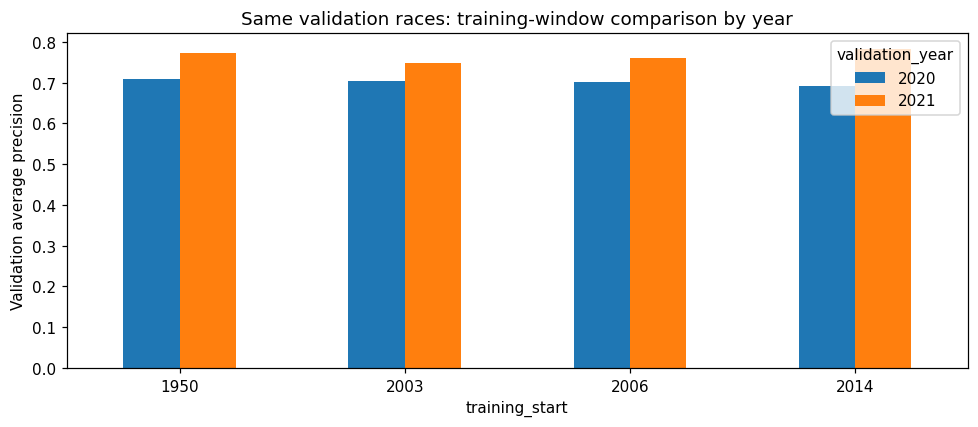

In [62]:
window_year_rows = []
for start, probability in window_predictions.items():
    for year in [2020, 2021]:
        mask = splits['validation'].year.eq(year).to_numpy()
        window_year_rows.append({'training_start': start, 'validation_year': year,
            **metrics(splits['validation'].loc[mask, 'podium'], probability[mask])})
window_year_scores = pd.DataFrame(window_year_rows)
show(window_scores[['training_start', 'average_precision', 'roc_auc', 'f1']])
show(window_year_scores[['training_start', 'validation_year', 'average_precision', 'roc_auc', 'f1']])
window_year_scores.pivot(index='training_start', columns='validation_year',
    values='average_precision').plot.bar(figsize=(9, 4), rot=0)
plt.ylabel('Validation average precision')
plt.title('Same validation races: training-window comparison by year')
plt.tight_layout()
plt.show()

**Training-window decision (validation only):** AP ranges from 0.727 to 0.738. The 2014 start leads the 1950 start by only about 0.0004. The tables above expose the trade-offs across ROC-AUC, F1 and the two validation years; all six paired window AP intervals are shown in Section 9. We retain **1950–2019** to use the complete available training history with essentially similar validation AP, while documenting the coverage and era limitations. A range crossing zero does not prove equivalence.

The main model's lower training AP (about 0.58) than validation AP (about 0.74) compares different populations. The coverage and field-size EDA make distribution differences plausible, but this score gap alone neither establishes its cause nor proves the absence of leakage. Leakage is checked separately through source-date constraints and the perturbation test in Section 6.1.

In [63]:
# Map every encoded column back to its input and feature group.
schema_rows = []
for column in preprocessing['columns']:
    source = column.removesuffix('__was_missing')
    for position in POSITION_COLUMNS:
        if column.startswith(position + '_'):
            source = position
            break
    group = next(group for group, names in FEATURE_GROUPS.items() if source in names)
    schema_rows.append({'output_column': column, 'source_feature': source, 'feature_group': group})
schema = pd.DataFrame(schema_rows)
groups = schema.feature_group.drop_duplicates().tolist()

random_forest = RandomForestClassifier(n_estimators=300, max_depth=10,
    min_samples_leaf=10, min_samples_split=2, max_features='sqrt', criterion='gini',
    bootstrap=True, class_weight=None, random_state=SEED, n_jobs=2, oob_score=False)
with threadpool_limits(limits=1):
    random_forest.fit(X['train'], y['train'])

### Shallow neural network — one hidden layer with explicit checkpoint selection

The 184 → 32 ReLU → 1 sigmoid network is a deliberately small, fixed nonlinear comparison against logistic regression. One hidden layer satisfies the shallow-network requirement; Adam, L2 regularization and validation-based stopping provide a bounded initial recipe, not a claim of optimal hyperparameters. We use the standard scikit-learn MLP implementation. Each `partial_fit` call performs one epoch; only training rows update weights. Validation AP selects the best checkpoint. Stop after 20 epochs without improvement, up to 200 epochs. The learning curves below show what happened for this fixed architecture and seed.

Completed epochs: 31 | best epoch: 11


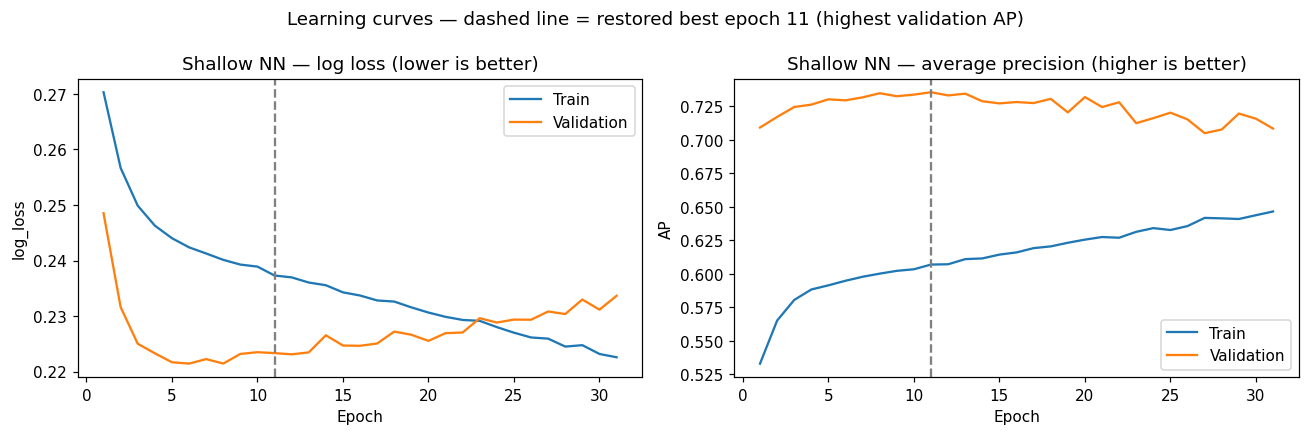

In [64]:
network = MLPClassifier(hidden_layer_sizes=(32,), activation='relu', solver='adam',
    alpha=0.0001, batch_size=128, learning_rate_init=0.001, shuffle=True,
    early_stopping=False, max_iter=1, tol=0.0, n_iter_no_change=201,
    random_state=np.random.RandomState(SEED))
history = []
best_AP = -np.inf
stale_epochs = 0
with threadpool_limits(limits=1):
    for epoch in range(1, 201):
        if epoch == 1:
            network.partial_fit(X['train'], y['train'], classes=np.array([0, 1]))
        else:
            network.partial_fit(X['train'], y['train'])
        train_p = network.predict_proba(X['train'])[:, 1]
        validation_p = network.predict_proba(X['validation'])[:, 1]
        validation_AP = average_precision_score(y['validation'], validation_p)
        history.append({'epoch': epoch,
            'train_log_loss': log_loss(y['train'], train_p, labels=[0, 1]),
            'validation_log_loss': log_loss(y['validation'], validation_p, labels=[0, 1]),
            'train_AP': average_precision_score(y['train'], train_p),
            'validation_AP': validation_AP})
        if validation_AP > best_AP:
            best_AP, best_epoch = validation_AP, epoch
            neural_model = copy.deepcopy(network)
            stale_epochs = 0
        else:
            stale_epochs += 1
        if stale_epochs >= 20:
            break
history = pd.DataFrame(history)
print('Completed epochs:', len(history), '| best epoch:', best_epoch)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['log_loss', 'AP']):
    ax.plot(history.epoch, history['train_' + metric], label='Train')
    ax.plot(history.epoch, history['validation_' + metric], label='Validation')
    ax.axvline(best_epoch, color='gray', linestyle='--')
    ax.set(xlabel='Epoch', ylabel=metric, title=f'Shallow NN — {"log loss (lower is better)" if metric == "log_loss" else "average precision (higher is better)"}')
    ax.legend()
fig.suptitle(f'Learning curves — dashed line = restored best epoch {best_epoch} (highest validation AP)')
plt.tight_layout()
plt.show()

           model  average_precision  pr_auc_trapezoidal   roc_auc        f1  precision    recall
0       logistic           0.737703            0.735288  0.930025  0.678899   0.732673  0.632479
1  random_forest           0.714201            0.711496  0.921904  0.666667   0.781609  0.581197
2     shallow_nn           0.735437            0.733445  0.931521  0.669643   0.700935  0.641026


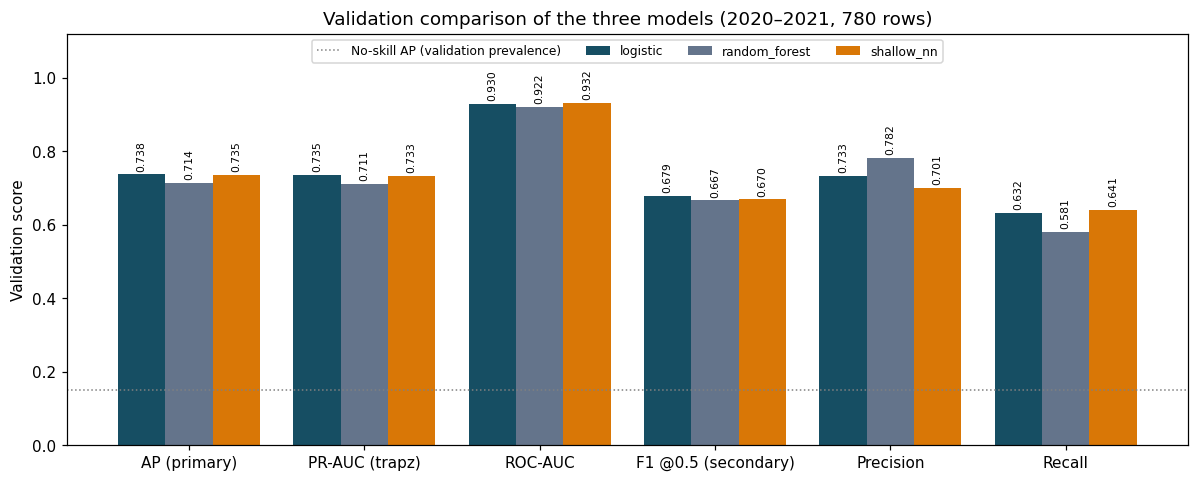

In [65]:
models = {'logistic': logistic_model, 'random_forest': random_forest, 'shallow_nn': neural_model}
probabilities = {}
validation_scores = []
with threadpool_limits(limits=1):
    for name, model in models.items():
        for split in ['train', 'validation']:
            probabilities[name, split] = model.predict_proba(X[split])[:, 1]
        validation_scores.append({'model': name, **metrics(y['validation'], probabilities[name, 'validation'])})
validation_scores = pd.DataFrame(validation_scores)
display(validation_scores[['model', 'average_precision', 'pr_auc_trapezoidal', 'roc_auc', 'f1', 'precision', 'recall']])
fig, ax = plt.subplots(figsize=(11, 4.5))
vs_metrics = ['average_precision', 'pr_auc_trapezoidal', 'roc_auc', 'f1', 'precision', 'recall']
vs_width = 0.27
for k, (row, color) in enumerate(zip(validation_scores.itertuples(), ['#164e63', '#64748b', '#d97706'])):
    values = [getattr(row, m) for m in vs_metrics]
    bars = ax.bar(np.arange(len(vs_metrics)) + (k - 1) * vs_width, values, vs_width, label=row.model, color=color)
    ax.bar_label(bars, labels=[f'{v:.3f}' for v in values], fontsize=7, padding=2, rotation=90)
ax.axhline(0.15, color='gray', linestyle=':', linewidth=1, label='No-skill AP (validation prevalence)')
ax.set_xticks(np.arange(len(vs_metrics)), ['AP (primary)', 'PR-AUC (trapz)', 'ROC-AUC', 'F1 @0.5 (secondary)', 'Precision', 'Recall'])
ax.set(ylim=(0, 1.12), ylabel='Validation score', title='Validation comparison of the three models (2020–2021, 780 rows)')
ax.legend(ncol=4, fontsize=8, loc='upper center')
plt.tight_layout()
plt.show()

**Observed:** logistic regression has the best validation AP (**0.738**) and F1 (**0.679**). The shallow NN is very close (AP 0.735, slightly higher ROC-AUC and recall), and the random forest is lower (AP 0.714) — it makes fewer podium calls, so it has the highest precision (78%) but misses more podiums (recall 58%). The NN peaked at epoch 11: afterwards training loss kept falling while validation AP dropped (0.735 → 0.708 by epoch 31), so restoring the checkpoint retains the epoch selected by the validation rule. The divergence is consistent with overfitting during later training; a single run does not establish stability across seeds. Extra model flexibility did not beat the simple baseline, so **logistic regression is selected** on its leading validation AP/F1 point estimates and simpler interpretation. Its AP advantage over the NN is small and its paired interval crosses zero; this is a practical selection, not proof of superiority.

## 9. Controlled experiments

**Feature-group ablation:** remove one of the eight groups at a time (all of its columns, including flags, `Unknown` categories and missingness indicators), retrain logistic regression with identical settings, and compare validation AP with the full model. This measures each group's *added* value given all the others. It differs from permutation importance (Section 10), which shuffles a group inside a fixed model.

**Preprocessing-order experiments:** change one ordering decision at a time and keep everything else fixed.
1. **Scale before filling** — fit StandardScaler on the observed values first, then fill missing values with the median in scaled units (main pipeline: fill first, then scale).
2. **Indicators after filling** — create the six missingness indicators *after* median filling (main pipeline: before). After filling nothing is missing, so these indicators become all zeros — this tests what is lost when the order is wrong.

These are validation experiments; neither becomes the main recipe automatically.

             removed_group  average_precision        f1   AP_drop
0            driver_career           0.735067  0.681818  0.002636
1   driver_circuit_history           0.740259  0.675799 -0.002556
2       driver_recent_form           0.738857  0.678899 -0.001155
3  constructor_recent_form           0.737539  0.669725  0.000163
4         driver_standings           0.725502  0.666667  0.012201
5    constructor_standings           0.722871  0.681818  0.014832
6                     grid           0.713743  0.690583  0.023960
7               qualifying           0.735160  0.685185  0.002543


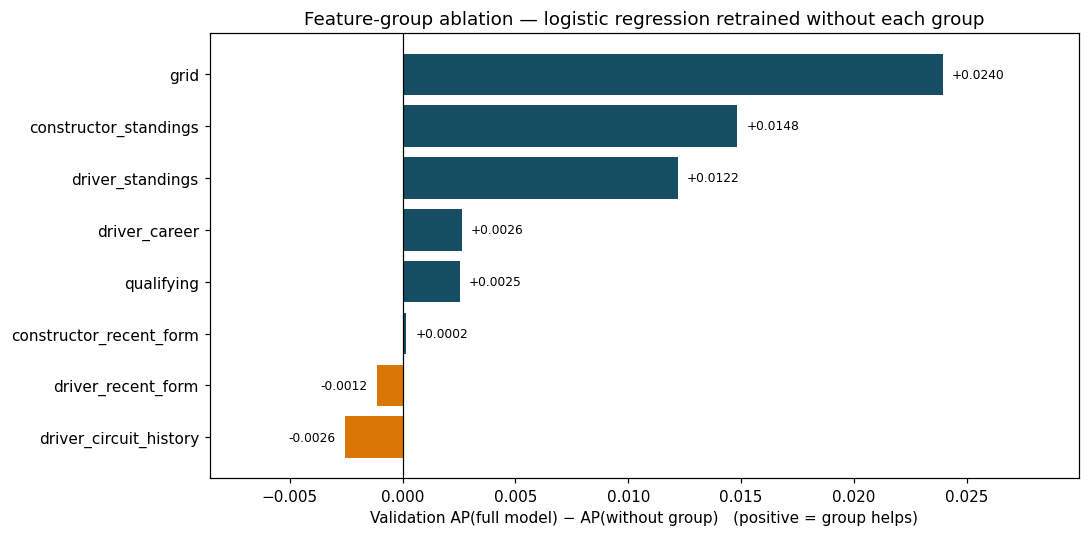

In [66]:
ablation_models = {}
ablation_probabilities = {}
ablation_scores = []
for group in groups:
    keep = schema.feature_group.ne(group).to_numpy()
    with threadpool_limits(limits=1):
        model = LogisticRegression(**LOGISTIC_SETTINGS).fit(X['train'][:, keep], y['train'])
        probability = model.predict_proba(X['validation'][:, keep])[:, 1]
    ablation_models[group] = model
    ablation_probabilities[group] = probability
    ablation_scores.append({'removed_group': group,
        'AP_drop': average_precision_score(y['validation'], probabilities['logistic', 'validation']) -
            average_precision_score(y['validation'], probability), **metrics(y['validation'], probability)})
ablation_scores = pd.DataFrame(ablation_scores)
display(ablation_scores[['removed_group', 'average_precision', 'f1', 'AP_drop']])
ab_plot = ablation_scores.set_index('removed_group').AP_drop.sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(ab_plot.index, ab_plot.values, color=['#d97706' if v < 0 else '#164e63' for v in ab_plot.values])
for i, v in enumerate(ab_plot.values):
    ax.text(v + (0.0004 if v >= 0 else -0.0004), i, f'{v:+.4f}', va='center', ha='left' if v >= 0 else 'right', fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Validation AP(full model) − AP(without group)   (positive = group helps)',
       title='Feature-group ablation — logistic regression retrained without each group',
       xlim=(ab_plot.min() - 0.006, ab_plot.max() + 0.006))
plt.tight_layout()
plt.show()

**Observed:** removing the **grid** group hurts most (AP −0.024), followed by **constructor standings** (−0.015) and **driver standings** (−0.012); driver career and qualifying add about +0.003 AP each. Removing driver recent form or circuit history *raises* AP slightly (+0.001/+0.003). The correlations in Section 6.2 are consistent with overlapping information, but these experiments do not establish why the small changes occur. All groups are kept — the paired race-bootstrap intervals below cross zero for every group, so one validation period is not enough evidence to delete any input. Note that removing grid *raises* F1 (0.679 → 0.691) while lowering AP; AP is the predeclared primary metric.

                            recipe  average_precision   roc_auc        f1  precision    recall
0  main: indicators → fill → scale           0.737703  0.930025  0.678899   0.732673  0.632479
1                scale_before_fill           0.737718  0.929935  0.678899   0.732673  0.632479
2            indicators_after_fill           0.739700  0.928826  0.675799   0.725490  0.632479


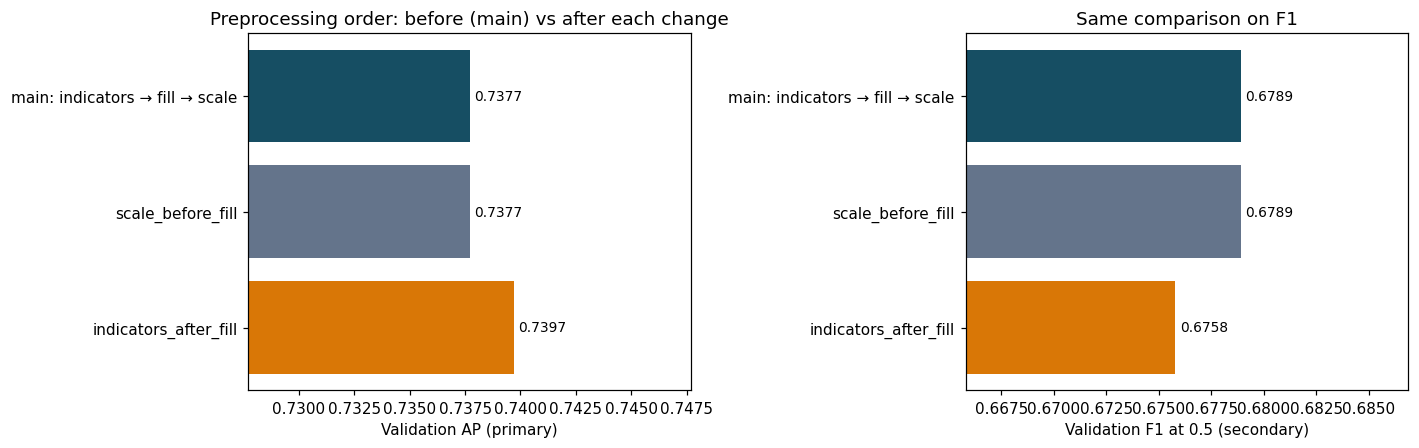

In [67]:
observed_scaler = StandardScaler().fit(splits['train'][NUMERIC_COLUMNS].astype(float))
observed_scaled = pd.DataFrame(observed_scaler.transform(splits['train'][NUMERIC_COLUMNS]),
    index=splits['train'].index, columns=NUMERIC_COLUMNS)
scaled_imputer = SimpleImputer(strategy='median', keep_empty_features=True).fit(observed_scaled[MEDIAN_COLUMNS])
scaled_medians = dict(zip(MEDIAN_COLUMNS, scaled_imputer.statistics_))

def order_transform(rows, variant):
    encoded = transform_features(rows, preprocessing)
    if variant == 'scale_before_fill':
        # Use the same explicit arithmetic as the original order experiment.
        values = (rows[NUMERIC_COLUMNS].astype(float) - pd.Series(observed_scaler.mean_,
            index=NUMERIC_COLUMNS)) / pd.Series(observed_scaler.scale_,
            index=NUMERIC_COLUMNS)
        encoded[NUMERIC_COLUMNS] = values.fillna(scaled_medians)
    elif variant == 'indicators_after_fill':
        filled = pd.DataFrame(preprocessing['imputer'].transform(
            rows[MEDIAN_COLUMNS].astype(float)), index=rows.index, columns=MEDIAN_COLUMNS)
        after_fill_indicators = filled.isna().astype(float)
        encoded[[name + '__was_missing' for name in MEDIAN_COLUMNS]] = after_fill_indicators.to_numpy()
        encoded = encoded.rename(columns={name + '__was_missing': name + '__missing_after_fill' for name in MEDIAN_COLUMNS})
    else:
        raise ValueError('Unknown experiment')
    return encoded.to_numpy(dtype=float)

order_models = {}
order_predictions = {}
order_scores = []
for variant in ['scale_before_fill', 'indicators_after_fill']:
    train_X = order_transform(splits['train'], variant)
    validation_X = order_transform(splits['validation'], variant)
    with threadpool_limits(limits=1):
        model = LogisticRegression(**LOGISTIC_SETTINGS).fit(train_X, y['train'])
        probability = model.predict_proba(validation_X)[:, 1]
    order_models[variant], order_predictions[variant] = model, probability
    order_scores.append({'recipe': variant, **metrics(y['validation'], probability)})
order_scores = pd.DataFrame(order_scores)
order_display = pd.concat([pd.DataFrame([{'recipe': 'main: indicators → fill → scale',
    **metrics(y['validation'], probabilities['logistic', 'validation'])}]), order_scores], ignore_index=True)
display(order_display[['recipe', 'average_precision', 'roc_auc', 'f1', 'precision', 'recall']])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, metric_name, label in [(axes[0], 'average_precision', 'Validation AP (primary)'), (axes[1], 'f1', 'Validation F1 at 0.5 (secondary)')]:
    values = order_display[metric_name].to_numpy()
    bars = ax.barh(order_display.recipe, values, color=['#164e63', '#64748b', '#d97706'])
    ax.bar_label(bars, labels=[f'{v:.4f}' for v in values], padding=3, fontsize=9)
    ax.set(xlim=(values.min() - 0.01, values.max() + 0.008), xlabel=label)
    ax.invert_yaxis()
axes[0].set_title('Preprocessing order: before (main) vs after each change')
axes[1].set_title('Same comparison on F1')
plt.tight_layout()
plt.show()

### Inspect the transformed inputs behind the order experiments

Scores alone do not show what changed. Compare the scaler fitted after filling with the scaler fitted on observed values. For each split, count original missing values, main indicators and indicators measured after filling. Finally invert the scale-before-fill transformation for its missing numeric entries and check that their filled values in original units agree with the training medians.

In [68]:
order_scaling_audit = pd.DataFrame({
    'input': NUMERIC_COLUMNS,
    'scale_after_fill': preprocessing['scaler'].scale_,
    'scale_before_fill': observed_scaler.scale_,
})
order_scaling_audit['scale_change_pct'] = 100 * (
    order_scaling_audit.scale_before_fill / order_scaling_audit.scale_after_fill - 1)
show(order_scaling_audit)
order_missing_rows = []
order_raw_fill_errors = []
raw_training_medians = dict(zip(MEDIAN_COLUMNS, preprocessing['imputer'].statistics_))
numeric_positions = {name: preprocessing['columns'].index(name) for name in NUMERIC_COLUMNS}
for split, rows in splits.items():
    main_matrix = transform_features(rows, preprocessing)
    before_matrix = order_transform(rows, 'scale_before_fill')
    after_matrix = order_transform(rows, 'indicators_after_fill')
    for name in MEDIAN_COLUMNS:
        missing = rows[name].isna().to_numpy()
        original_column = preprocessing['columns'].index(name + '__was_missing')
        main_ones = int(main_matrix[name + '__was_missing'].sum())
        before_ones = int(before_matrix[:, original_column].sum())
        after_ones = int(after_matrix[:, original_column].sum())
        order_missing_rows.append({'split': split, 'input': name,
            'original_missing': int(missing.sum()), 'main_indicator_ones': main_ones,
            'scale_before_fill_indicator_ones': before_ones,
            'post_fill_indicator_ones': after_ones})
        position = NUMERIC_COLUMNS.index(name)
        recovered = before_matrix[missing, numeric_positions[name]] * observed_scaler.scale_[position] + observed_scaler.mean_[position]
        error = float(np.max(np.abs(recovered - raw_training_medians[name]))) if missing.any() else 0.0
        order_raw_fill_errors.append({'split': split, 'input': name,
            'missing_rows': int(missing.sum()), 'raw_fill_max_absolute_error': error})
order_indicator_audit = pd.DataFrame(order_missing_rows)
order_raw_fill_audit = pd.DataFrame(order_raw_fill_errors)
show(order_indicator_audit)
show(order_raw_fill_audit)
assert order_indicator_audit.original_missing.eq(order_indicator_audit.main_indicator_ones).all()
assert order_indicator_audit.original_missing.eq(order_indicator_audit.scale_before_fill_indicator_ones).all()
assert order_indicator_audit.post_fill_indicator_ones.eq(0).all()
assert order_raw_fill_audit.raw_fill_max_absolute_error.lt(1e-10).all()

                              input  scale_after_fill  scale_before_fill  scale_change_pct
        driver_prior_participations         61.433294          61.433294          0.000000
driver_circuit_prior_participations          3.012431           3.012431          0.000000
           driver_prior_podium_rate          0.156209           0.158453          1.436967
           driver_last5_podium_rate          0.231560           0.234366          1.211720
constructor_last5_races_podium_rate          0.199609           0.200404          0.398200
   driver_circuit_prior_podium_rate          0.215072           0.246916         14.806086
      driver_prior_GP_season_points         34.259297          35.457031          3.496085
 constructor_prior_GP_season_points         66.169894          68.704074          3.829809
     split                               input  original_missing  main_indicator_ones  scale_before_fill_indicator_ones  post_fill_indicator_ones
     train            driver_prior_

**Observed:**
- **Scale before filling:** six numeric columns get different scaling statistics (e.g. the circuit podium rate's spread changes by 15%, because 7,326 training rows are missing), but the filled raw values are the same. Validation AP changes by only **+0.000015** and the thresholded prediction metrics are identical → no practical difference.
- **Indicators after filling:** all six indicators become zero, so the model loses the information "this driver has no history". AP moves **+0.002**, but F1 drops (0.679 → 0.676) and ROC-AUC drops; the bootstrap interval crosses zero.
- **Decision:** keep the main order (indicators → fill → scale). Neither alternative gives a reliable gain, and the main order keeps the truthful missingness information.

### Uncertainty in validation comparisons

Resample whole validation races, using the same sampled races for both models in each comparison. The 2,000 percentile-bootstrap ranges describe the fixed fitted predictions, conditional on model/window selection. They do not include retraining variability or correct for multiple comparisons. An interval crossing zero does not establish a clear difference.

In [69]:
from itertools import combinations

validation_races = splits['validation'].raceId.to_numpy()
race_ids = pd.unique(validation_races)
rng = np.random.default_rng(SEED)
race_draws = race_ids[rng.integers(0, len(race_ids), size=(2000, len(race_ids)))]
race_positions = {race: np.flatnonzero(validation_races == race) for race in race_ids}
bootstrap_positions = [np.concatenate([race_positions[race] for race in draw]) for draw in race_draws]

def bootstrap_AP(probability):
    return np.asarray([average_precision_score(y['validation'][positions], probability[positions])
        for positions in bootstrap_positions])

reference = probabilities['logistic', 'validation']
reference_AP_draws = bootstrap_AP(reference)
alternatives = {**{f'window_{start}': value for start, value in window_predictions.items() if start != 1950},
    'random_forest': probabilities['random_forest', 'validation'],
    'shallow_nn': probabilities['shallow_nn', 'validation'],
    **{'without_' + group: value for group, value in ablation_probabilities.items()},
    **order_predictions}
alternative_AP_draws = {name: bootstrap_AP(probability) for name, probability in alternatives.items()}
comparison_rows = []
for name, probability in alternatives.items():
    low, high = np.quantile(reference_AP_draws - alternative_AP_draws[name], [0.025, 0.975])
    comparison_rows.append({'comparison': 'main_minus_' + name,
        'AP_difference': average_precision_score(y['validation'], reference) -
            average_precision_score(y['validation'], probability),
        'bootstrap_low': low, 'bootstrap_high': high})
comparison_intervals = pd.DataFrame(comparison_rows)
display(comparison_intervals)

window_AP_draws = {1950: reference_AP_draws,
    **{start: alternative_AP_draws[f'window_{start}'] for start in [2003, 2006, 2014]}}
window_pair_rows = []
for first, second in combinations([1950, 2003, 2006, 2014], 2):
    low, high = np.quantile(window_AP_draws[first] - window_AP_draws[second], [0.025, 0.975])
    window_pair_rows.append({'first_start': first, 'second_start': second,
        'AP_difference_first_minus_second': average_precision_score(y['validation'], window_predictions[first]) -
            average_precision_score(y['validation'], window_predictions[second]),
        'bootstrap_low': low, 'bootstrap_high': high,
        'interval_crosses_zero': bool(low <= 0 <= high)})
window_pairwise_intervals = pd.DataFrame(window_pair_rows)
display(window_pairwise_intervals)

                                    comparison  AP_difference  bootstrap_low  bootstrap_high
0                       main_minus_window_2003       0.010295      -0.008584        0.034310
1                       main_minus_window_2006       0.003898      -0.013771        0.025108
2                       main_minus_window_2014      -0.000398      -0.024365        0.020169
3                     main_minus_random_forest       0.023502      -0.011302        0.056075
4                        main_minus_shallow_nn       0.002265      -0.020501        0.024243
5             main_minus_without_driver_career       0.002636      -0.007824        0.013672
6    main_minus_without_driver_circuit_history      -0.002556      -0.008888        0.003564
7        main_minus_without_driver_recent_form      -0.001155      -0.007915        0.005909
8   main_minus_without_constructor_recent_form       0.000163      -0.009119        0.010527
9          main_minus_without_driver_standings       0.012201      -0.

**Reading the intervals:** each row resamples the 39 validation races 2,000 times (whole races kept together) and reports the AP difference *main logistic minus alternative*. **Every interval crosses zero**: with only two validation seasons, these comparisons do not establish an AP difference from the main model. This is not a proof of equal performance, nor a significance assessment of the test scores. The second table shows all six training-window pairs. That is why choices were made on simplicity and consistency, not on tiny point differences.

## 10. Global explanations — fixed logistic model

**Permutation:** swap complete groups within the same race, 30 times. The error bars show shuffle variation, not a confidence interval.

**SHAP:** use exact interventional linear SHAP for the logistic **log-odds score**: coefficient × (encoded input − training mean). Sum signed encoded contributions within each input/group before averaging their absolute sizes. 

> **Important: these explanations are not causal effects.** A feature being important to the model only means the model *relies* on it to predict; it does not prove the feature *causes* podium finishes.

                     group  mean_AP_drop  shuffle_SD
6                     grid      0.233284    0.036880
7               qualifying      0.043376    0.022826
4         driver_standings      0.034927    0.019809
0            driver_career      0.020094    0.013395
5    constructor_standings      0.007808    0.010471
3  constructor_recent_form      0.007690    0.015712
2       driver_recent_form      0.000832    0.005193
1   driver_circuit_history      0.000007    0.002980


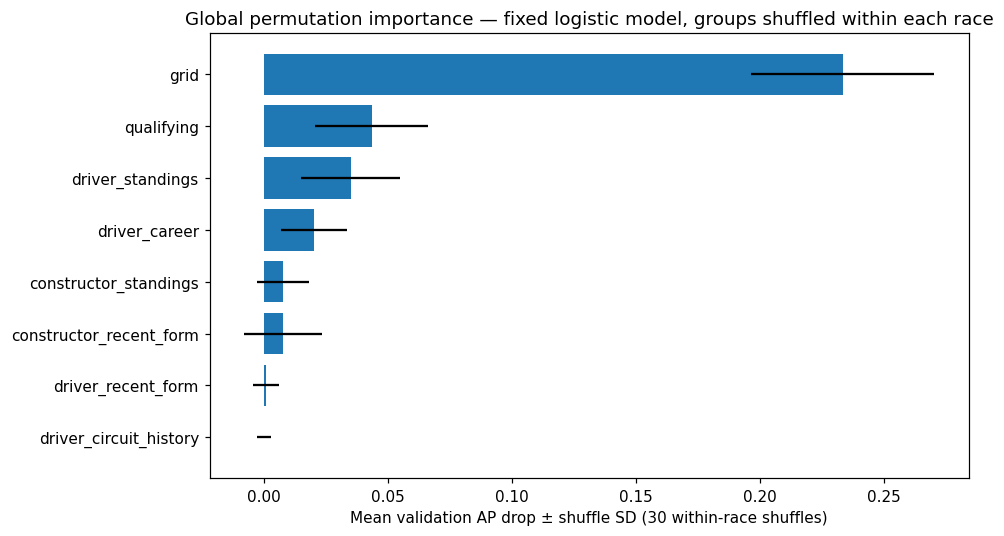

In [70]:
coefficient = logistic_model.coef_.ravel()
intercept = float(logistic_model.intercept_[0])
original_AP = average_precision_score(y['validation'], probabilities['logistic', 'validation'])
rng = np.random.default_rng(SEED)
within_race = [np.flatnonzero(validation_races == race) for race in pd.unique(validation_races)]
donor_maps = []
for repeat in range(30):
    donors = np.arange(len(validation_races))
    for positions in within_race:
        donors[positions] = rng.permutation(positions)
    donor_maps.append(donors)
permutation_rows = []
with threadpool_limits(limits=1):
    for group in groups:
        mask = schema.feature_group.eq(group).to_numpy()
        for repeat, donors in enumerate(donor_maps):
            shuffled = X['validation'].copy()
            shuffled[:, mask] = X['validation'][donors][:, mask]
            probability = expit(shuffled @ coefficient + intercept)
            permutation_rows.append({'group': group, 'repeat': repeat,
                'AP_drop': original_AP - average_precision_score(y['validation'], probability)})
permutation_results = pd.DataFrame(permutation_rows)
permutation_summary = permutation_results.groupby('group', sort=False).agg(
    mean_AP_drop=('AP_drop', 'mean'), shuffle_SD=('AP_drop', 'std')).reset_index()
display(permutation_summary.sort_values('mean_AP_drop', ascending=False))
plot = permutation_summary.sort_values('mean_AP_drop')
plt.figure(figsize=(9, 5))
plt.barh(plot.group, plot.mean_AP_drop, xerr=plot.shuffle_SD)
plt.xlabel('Mean validation AP drop ± shuffle SD (30 within-race shuffles)')
plt.title('Global permutation importance — fixed logistic model, groups shuffled within each race')
plt.tight_layout()
plt.show()

**Observed:** shuffling the **grid** group within races lowers validation AP from 0.738 to about 0.50 (drop 0.233) — far more than any other group. Qualifying (0.043) and driver standings (0.035) follow; circuit history and recent form barely matter to this model. Error bars are variation across shuffles, not confidence intervals. For grid, this drop is much larger than its retrained ablation drop in Section 9. These experiments answer different questions: shuffling changes the inputs used by a fixed model and can break cross-group relationships, while ablation fits a new model that may use related retained inputs.

                     group  mean_absolute_log_odds
6                     grid                1.074265
7               qualifying                0.387824
4         driver_standings                0.345209
5    constructor_standings                0.298741
0            driver_career                0.179748
3  constructor_recent_form                0.170123
2       driver_recent_form                0.056974
1   driver_circuit_history                0.049510


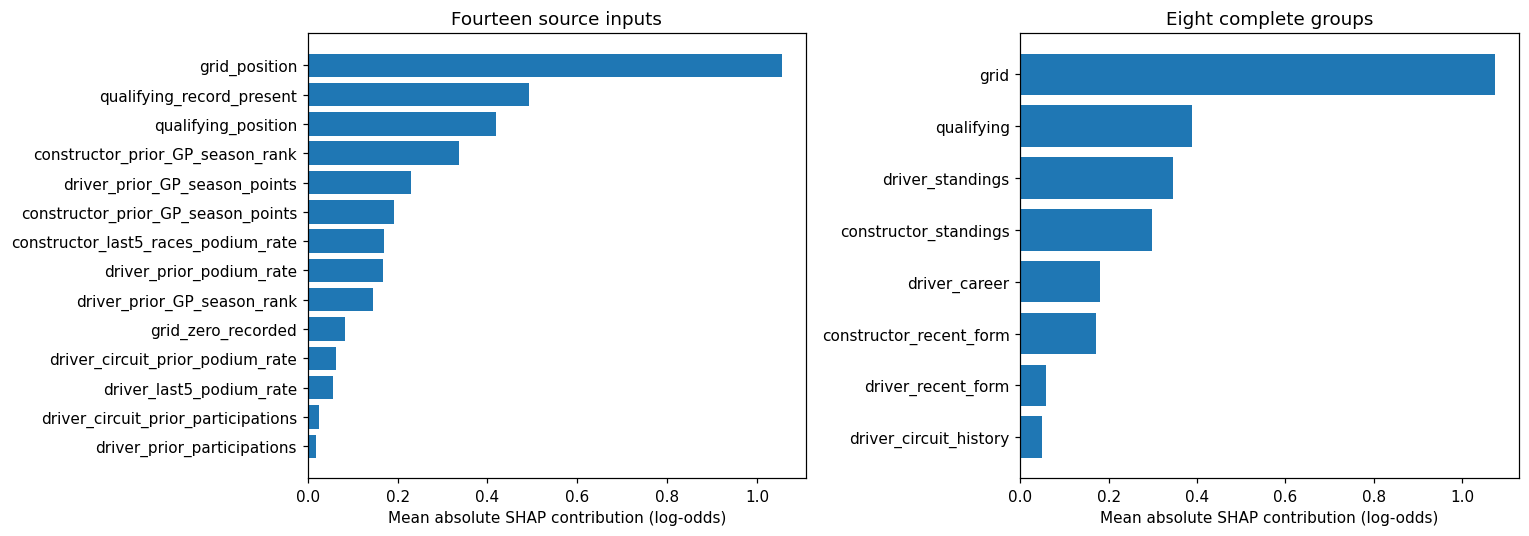

In [71]:
background = X['train'].mean(axis=0)
shap_values = (X['validation'] - background) * coefficient
base_score = float(intercept + background @ coefficient)

def aggregate_contributions(values, labels):
    names = list(dict.fromkeys(labels))
    labels = np.asarray(labels)
    return np.column_stack([values[:, labels == name].sum(axis=1) for name in names]), names

source_shap, source_names = aggregate_contributions(shap_values, schema.source_feature.tolist())
group_shap, group_names = aggregate_contributions(shap_values, schema.feature_group.tolist())
shap_ranking = pd.DataFrame({'group': group_names,
    'mean_absolute_log_odds': np.abs(group_shap).mean(axis=0)})
assert np.allclose(expit(base_score + shap_values.sum(axis=1)),
    probabilities['logistic', 'validation'], atol=1e-12, rtol=0)
display(shap_ranking.sort_values('mean_absolute_log_odds', ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, values, names, title in [
    (axes[0], source_shap, source_names, 'Fourteen source inputs'),
    (axes[1], group_shap, group_names, 'Eight complete groups')]:
    importance = pd.Series(np.abs(values).mean(axis=0), index=names).sort_values()
    ax.barh(importance.index, importance.values)
    ax.set(xlabel='Mean absolute SHAP contribution (log-odds)', title=title)
plt.tight_layout()
plt.show()

### 10.1 SHAP direction — which way does each input push?
One dot per validation driver–race. Colour = the input's own value (red high, blue low, grey missing). For position inputs a *high* value means further back (e.g. grid 20).

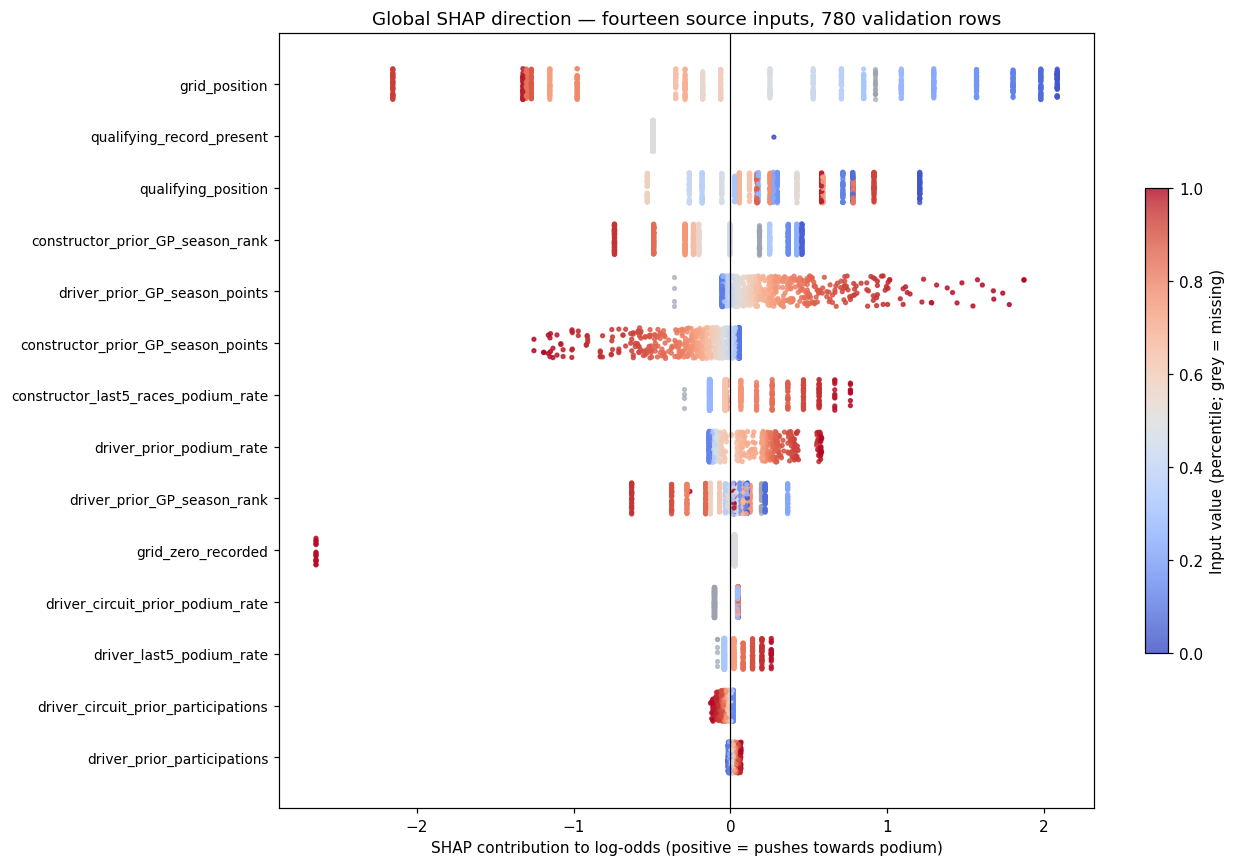

In [72]:
sd_order = np.argsort(np.abs(source_shap).mean(axis=0))
sd_values = splits['validation'][source_names].astype(float)
sd_rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(12, 8))
for row, j in enumerate(sd_order):
    name = source_names[j]
    raw = sd_values[name].to_numpy()
    observed = ~np.isnan(raw)
    colour_value = np.full(len(raw), np.nan)
    if observed.any():
        colour_value[observed] = pd.Series(raw[observed]).rank(pct=True).to_numpy()
    jitter = row + sd_rng.uniform(-0.3, 0.3, len(raw))
    ax.scatter(source_shap[~observed, j], jitter[~observed], s=6, color='#9ca3af', alpha=0.6)
    sc = ax.scatter(source_shap[observed, j], jitter[observed], s=6, c=colour_value[observed], cmap='coolwarm', vmin=0, vmax=1, alpha=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_yticks(range(len(sd_order)), [source_names[j] for j in sd_order], fontsize=9)
ax.set(xlabel='SHAP contribution to log-odds (positive = pushes towards podium)',
       title='Global SHAP direction — fourteen source inputs, 780 validation rows')
cbar = fig.colorbar(sc, ax=ax, shrink=0.6)
cbar.set_label('Input value (percentile; grey = missing)')
plt.tight_layout()
plt.show()

**Observed:**
- **Grid dominates** both rankings (mean |SHAP| 1.07 log-odds). In the direction plot, low grid numbers (blue) push strongly towards podium and high numbers (red) push away — the expected relationship.
- **Qualifying position and championship standings** come next: a strong qualifying position and a high constructor/driver rank raise the score.
- **Recent form and circuit history** have small contributions, consistent with the ablation.
- **Correlated inputs offset each other:** high constructor *points* push the score *down* while a good constructor *rank* pushes it up. The two are strongly correlated (ρ = −0.80). Opposite contributions are consistent with overlapping inputs in an additive model, but the correlation does not establish why these fitted signs arose. Read them together; the negative points contribution is not evidence that earning more points causes worse results.
- **The qualifying-availability flag** can show a large SHAP bar even though almost every validation driver has a record: SHAP compares each driver with the *training mean*, and only 36% of 1950–2019 rows have qualifying data, versus 99.9% in 2020–2021. That shared offset is large relative to the historical reference but barely separates modern drivers. Qualifying position and availability can offset each other, so the group plot sums their signed contributions first.
- These are explanations of the fitted model, **not causes**.

## 11. Explain one driver — exact SHAP and grouped LIME

Select the first validation row by date, race ID and driver ID without looking at its probability or outcome. This selects **Lewis Hamilton at the 2020 Austrian GP**. An explanation can correctly describe a model even when that model's prediction is wrong.

Grouped LIME uses eight whole-group keep/replace switches so that a position's one-hot columns and related flags move together. Responses are averaged over the full training background and fitted with the official LimeBase engine and Ridge: 5,000 artificial fit-mask draws and 2,000 additional audit-mask draws. Those draws can repeat the same combinations; they are not independent real driver–race observations. Cross-group realism is not guaranteed. The local error and weighted fidelity below assess this explicitly defined perturbation mechanism.

                                     value
driver_prior_participations            250
driver_prior_podium_rate             0.604
driver_last5_podium_rate               0.8
constructor_last5_races_podium_rate    0.7
driver_circuit_prior_participations      6
driver_circuit_prior_podium_rate       0.5
grid_position                          5.0
grid_zero_recorded                   False
qualifying_position                    2.0
qualifying_record_present             True
driver_prior_GP_season_points          0.0
driver_prior_GP_season_rank            NaN
constructor_prior_GP_season_points     0.0
constructor_prior_GP_season_rank       NaN
Race / driver: 1031 1
Model probability: 57.86% | actual podium: 0


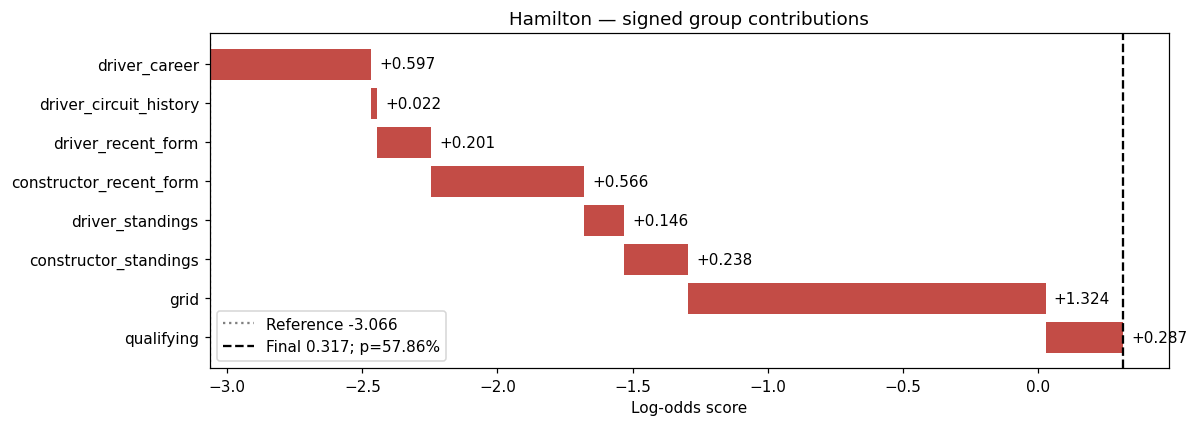

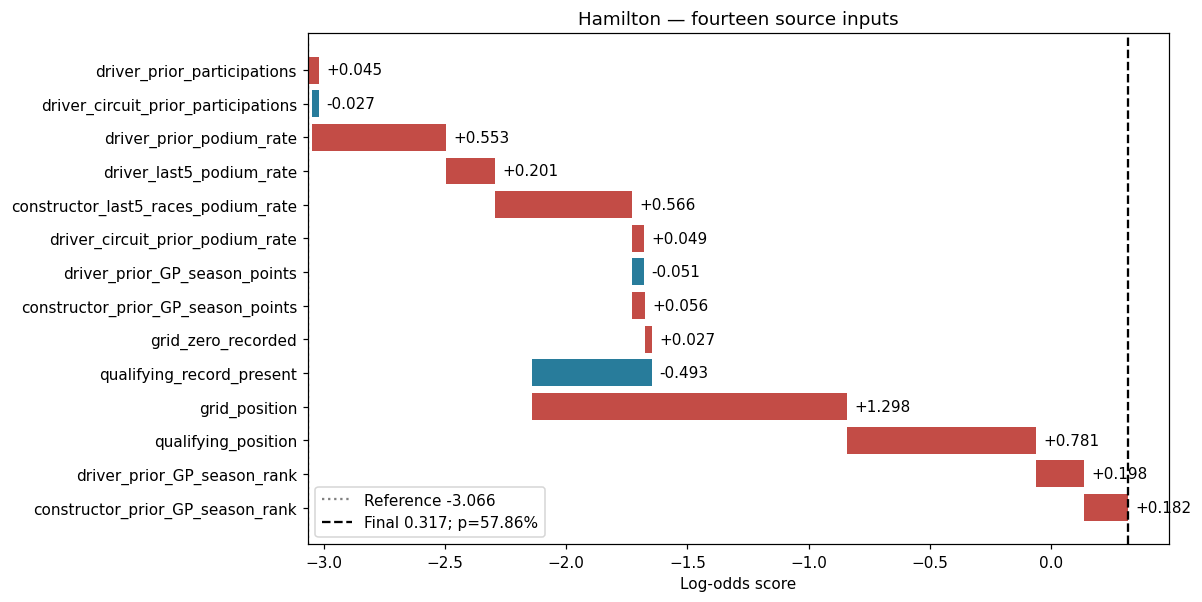

In [73]:
local_row = splits['validation'].sort_values(['race_date', 'raceId', 'driverId'], kind='stable').iloc[0]
local_position = np.flatnonzero((splits['validation'].raceId.to_numpy() == local_row.raceId) &
    (splits['validation'].driverId.to_numpy() == local_row.driverId))[0]
local_X = X['validation'][local_position]
local_probability = probabilities['logistic', 'validation'][local_position]
local_input = local_row[INPUT_COLUMNS]
local_group_values = group_shap[local_position]
display(local_input.to_frame('value'))
print('Race / driver:', int(local_row.raceId), int(local_row.driverId))
print('Model probability:', f'{local_probability:.2%}', '| actual podium:', int(local_row.podium))

def waterfall(values, names, base, title):
    cumulative = base + np.r_[0, np.cumsum(values)]
    fig, ax = plt.subplots(figsize=(11, max(4, len(names) * 0.4)))
    for j, value in enumerate(values):
        ax.barh(j, abs(value), left=min(cumulative[j], cumulative[j + 1]),
            color='#c34c46' if value > 0 else '#287c9b')
        ax.text(max(cumulative[j], cumulative[j + 1]) + 0.03, j, f'{value:+.3f}', va='center')
    ax.set_yticks(range(len(names)), names)
    ax.axvline(base, color='gray', linestyle=':', label=f'Reference {base:.3f}')
    ax.axvline(cumulative[-1],
        color='black',
        linestyle='--',
        label=f'Final {cumulative[-1]:.3f}; p={expit(cumulative[-1]):.2%}')
    ax.invert_yaxis()
    ax.set(xlabel='Log-odds score', title=title)
    ax.legend()
    plt.tight_layout()
    plt.show()

waterfall(local_group_values, group_names, base_score, 'Hamilton — signed group contributions')
waterfall(source_shap[local_position], source_names, base_score, 'Hamilton — fourteen source inputs')

In [74]:
local_identity = local_row[KEYS + ['race_date', 'constructorId']].to_frame().T.merge(
    analysis_tables['races'][['raceId', 'name']].rename(columns={'name': 'race'}), on='raceId').merge(
    analysis_tables['drivers'][['driverId', 'forename', 'surname']], on='driverId').merge(
    analysis_tables['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor'}), on='constructorId').merge(
    analysis_driver_race[KEYS + ['best_position_order']], on=KEYS)
local_identity['grid_position'] = local_row.grid_position
local_identity['qualifying_position'] = local_row.qualifying_position
local_identity['model_probability'] = round(float(local_probability), 4)
local_identity['predicted_class'] = 'podium' if local_probability >= THRESHOLD else 'not podium'
local_identity['actual_finish_positionOrder'] = local_identity.pop('best_position_order')
local_identity['outcome'] = ('true positive' if local_row.podium else 'false positive') if local_probability >= THRESHOLD else (
    'false negative' if local_row.podium else 'true negative')
print('Selected example (chosen by date order before looking at its prediction):')
show(local_identity.drop(columns=['constructorId']))

Selected example (chosen by date order before looking at its prediction):
raceId driverId  race_date                race forename  surname constructor  grid_position  qualifying_position  model_probability predicted_class  actual_finish_positionOrder        outcome
  1031        1 2020-07-05 Austrian Grand Prix    Lewis Hamilton    Mercedes            5.0                  2.0             0.5786          podium                            4 false positive


**Reading the waterfall:** the model starts from the historical training reference (log-odds −3.07, about 4%) and adds each group's signed contribution: **grid +1.32**, **driver career +0.60** and **constructor recent form +0.57** are the largest pushes upward. The total (+3.38) gives log-odds 0.32 → **57.9% podium probability**, so the model predicts a podium. Hamilton actually finished **4th**, so this is a **false positive**. The explanation is still exact: it correctly describes *why the model* said 57.9%, even though the prediction was wrong. Qualifying position 2 contributes +0.78 and the "record present" flag −0.49, which net to +0.29. Both championship ranks are `Unknown` because this was the first race of 2020, and points are 0 — Hamilton's 250-race career history is still intact.

In [75]:
"""Grouped probability-scale LIME neighborhood and exact response lookup.

Whole-group replacement preserves within-block encoding. The response is the
mean fixed-classifier probability over all specified training-background rows.
Cross-group dependencies/era plausibility are not guaranteed. No outcome y is
accepted. Requires the official LIME engine for surrogate fitting.
"""
import numpy as np
import pandas as pd
from scipy.special import expit
from lime.lime_base import LimeBase
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score


def full_background_group_game(training_X, row_X, coefficient, intercept, labels):
    training_X=np.asarray(training_X,dtype=float)
    row_X=np.asarray(row_X,dtype=float).ravel()
    coefficient=np.asarray(coefficient,dtype=float).ravel()
    names=list(dict.fromkeys(labels));labels=np.asarray(labels)
    if training_X.ndim!=2 or training_X.shape[1]!=len(row_X) or len(row_X)!=len(coefficient) or len(labels)!=len(row_X):
        raise ValueError('Inconsistent encoded dimensions')
    if not all(np.isfinite(a).all() for a in [training_X,row_X,coefficient]):
        raise ValueError('Finite encoded data required')
    masks=[labels==g for g in names]
    donor_scores=np.column_stack([training_X[:,m]@coefficient[m] for m in masks])
    row_scores=np.asarray([row_X[m]@coefficient[m] for m in masks])
    table=[]
    for code in range(2**len(names)):
        keep=np.asarray([bool(code&(1<<j)) for j in range(len(names))])
        scores=float(intercept)+row_scores[keep].sum()+donor_scores[:,~keep].sum(axis=1)
        table.append({'mask_code':code,'retained_groups':int(keep.sum()),
                      'mean_model_probability':float(expit(scores).mean())})
    return pd.DataFrame(table),names,masks


def draw_group_masks(n,groups,seed,keep_probability=.75):
    if n<2:raise ValueError('At least two neighborhood observations required')
    masks=np.random.default_rng(seed).binomial(1,keep_probability,size=(n,groups)).astype(float)
    masks[0,:]=1
    return masks


def mask_codes(masks):
    masks=np.asarray(masks)
    if masks.ndim!=2 or not np.isin(masks,[0,1]).all():raise ValueError('Binary group masks required')
    return (masks.astype(int)*(1<<np.arange(masks.shape[1]))).sum(axis=1)


def local_kernel(distances,width):
    return np.exp(-np.asarray(distances,dtype=float)**2/(2*width**2))


def fit_grouped_lime(masks,probabilities,width,seed):
    distances=np.sqrt(((np.asarray(masks)-1)**2).sum(axis=1))
    kernel=lambda d:local_kernel(d,width)
    base=LimeBase(kernel_fn=kernel,verbose=False,random_state=seed)
    intercept,explanation,score,local_pred=base.explain_instance_with_data(
        masks,np.column_stack([1-probabilities,probabilities]),distances,
        label=1,num_features=masks.shape[1],feature_selection='none',
        model_regressor=Ridge(alpha=1.,fit_intercept=True))
    coefficient=np.zeros(masks.shape[1])
    for j,value in explanation:coefficient[int(j)]=float(value)
    return {'intercept':float(intercept),'coefficients':coefficient,
            'weighted_R2':float(score),'local_prediction':float(np.asarray(local_pred).ravel()[0]),
            'distances':distances,'weights':kernel(distances)}


def weighted_fidelity(target,prediction,weights):
    target=np.asarray(target,dtype=float);prediction=np.asarray(prediction,dtype=float)
    return {'weighted_R2':float(r2_score(target,prediction,sample_weight=weights)),
            'weighted_RMSE':float(np.sqrt(np.average((target-prediction)**2,weights=weights))),
            'weighted_MAE':float(np.average(np.abs(target-prediction),weights=weights)),
            'rows':len(target),'minimum_surrogate_prediction':float(prediction.min()),
            'maximum_surrogate_prediction':float(prediction.max())}

Actual model: 57.86% | LIME approximation: 56.00%
Absolute local error: 1.86 percentage points
Additional-mask fidelity: {'weighted_R2': 0.9706974954340208, 'weighted_RMSE': 0.020092062593575908, 'weighted_MAE': 0.014668960567076592, 'rows': 2000, 'minimum_surrogate_prediction': -0.010342761578230164, 'maximum_surrogate_prediction': 0.5600060905988808}


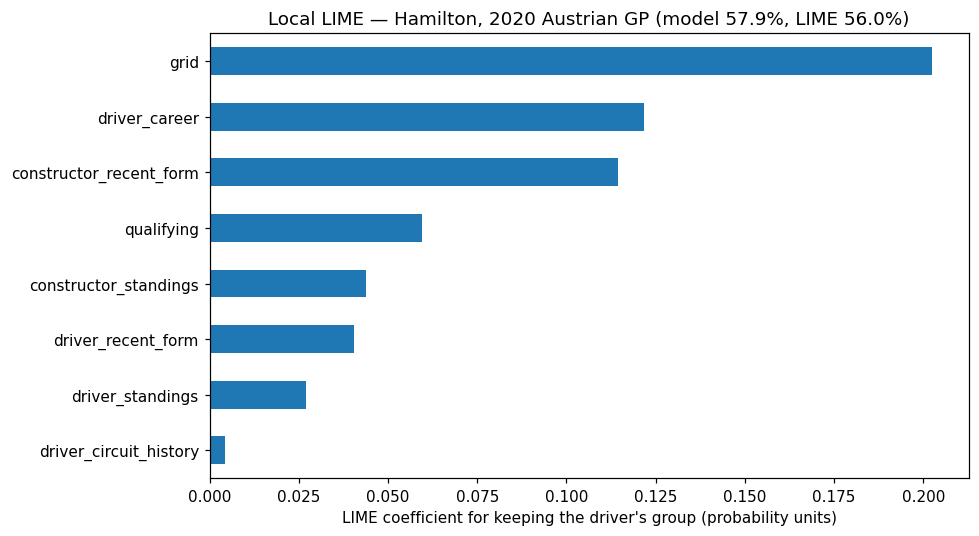

In [76]:
with threadpool_limits(limits=1):
    lime_game, lime_groups, lime_group_masks = full_background_group_game(
        X['train'], local_X, coefficient, intercept, schema.feature_group.tolist())
    mask_probability = lime_game.set_index('mask_code').mean_model_probability.to_numpy()
    fit_masks = draw_group_masks(5000, 8, 20261018)
    audit_masks = draw_group_masks(2000, 8, 20261019)
    fit_target = mask_probability[mask_codes(fit_masks)]
    audit_target = mask_probability[mask_codes(audit_masks)]
    surrogate = fit_grouped_lime(fit_masks, fit_target, 0.75 * np.sqrt(8), 20261018)
lime_probability = float(surrogate['intercept'] + surrogate['coefficients'].sum())
audit_distance = np.sqrt(((audit_masks - 1) ** 2).sum(axis=1))
lime_audit = weighted_fidelity(audit_target,
    surrogate['intercept'] + audit_masks @ surrogate['coefficients'],
    local_kernel(audit_distance, 0.75 * np.sqrt(8)))
print('Actual model:', f'{local_probability:.2%}', '| LIME approximation:', f'{lime_probability:.2%}')
print('Absolute local error:', f'{100 * abs(lime_probability - local_probability):.2f} percentage points')
print('Additional-mask fidelity:', lime_audit)
pd.Series(surrogate['coefficients'], index=lime_groups).sort_values().plot.barh(figsize=(9, 5))
plt.xlabel("LIME coefficient for keeping the driver's group (probability units)")
plt.title(f'Local LIME — Hamilton, 2020 Austrian GP (model {local_probability:.1%}, LIME {lime_probability:.1%})')
plt.tight_layout()
plt.show()

**Observed:** LIME approximates the model's 57.9% as **56.0%**, an error of about 1.9 percentage points. Weighted R² is about 0.97 on the additional 2,000 artificial mask draws, so the surrogate fits the defined perturbation responses well. This does not verify realistic counterfactual race scenarios or predictive generalization. Grid, driver career and constructor recent form have the largest positive local LIME coefficients, consistent with the local SHAP explanation.

The surrogate explains classifier outputs rather than actual finishes. Its linear predictions can lie outside [0, 1]; the audit reports that limitation without clipping. Inference always returns the classifier's own probability.

## 12. Inference — complete and partially missing records

`predict_podium(record)` accepts the fourteen **already engineered pre-race inputs**. It does not infer history from a driver's name. Counts and source flags are required. Missing positions become Unknown; missing rates/points use the fitted training medians and indicators. Reject unexpected fields and invalid values. A withheld qualifying position does not change a known source-presence flag.

Use the first chronologically complete validation record (Hamilton, 2020 Styrian GP) and withhold the same four fields as the full notebook. These calls demonstrate software behavior; they are not independent performance evidence.

In [77]:
def predict_podium(record):
    if not isinstance(record, dict) or not all(isinstance(name, str) for name in record):
        raise ValueError('Supply a dictionary of feature names and scalar values')
    unexpected = set(record) - set(INPUT_COLUMNS)
    if unexpected:
        raise ValueError(f'Unexpected fields: {sorted(unexpected)}; keep IDs/outcomes separate')
    required = COUNT_COLUMNS + FLAG_COLUMNS
    normalized = {}
    for name in INPUT_COLUMNS:
        value = record.get(name)
        missing = value is None or value is pd.NA or (
            isinstance(value, numbers.Real) and not isinstance(value, (bool, np.bool_)) and np.isnan(value))
        if missing:
            if name in required:
                raise ValueError(f'Required count/source flag missing: {name}')
            normalized[name] = np.nan
            continue
        if name in FLAG_COLUMNS:
            if not isinstance(value, (numbers.Real, bool, np.bool_)) or value not in [0, 1, False, True]:
                raise ValueError(f'{name} must be a boolean or 0/1')
            normalized[name] = bool(value)
            continue
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, numbers.Real):
            raise ValueError(f'{name} must be numeric')
        value = float(value)
        if not np.isfinite(value) or value < 0:
            raise ValueError(f'{name} must be finite and nonnegative')
        if name in RATE_COLUMNS and value > 1:
            raise ValueError(f'{name} must be between zero and one')
        if name in COUNT_COLUMNS and not value.is_integer():
            raise ValueError(f'{name} must be a whole count')
        if name in POSITION_COLUMNS and (value <= 0 or not value.is_integer()):
            raise ValueError(f'{name} must be a positive integer or missing')
        normalized[name] = value
    if normalized['grid_zero_recorded'] and not pd.isna(normalized['grid_position']):
        raise ValueError('Recorded grid zero requires an unknown grid position')
    if not normalized['qualifying_record_present'] and not pd.isna(normalized['qualifying_position']):
        raise ValueError('Known qualifying position conflicts with absent source record')
    frame = pd.DataFrame([normalized], columns=INPUT_COLUMNS)
    encoded = transform_features(frame, preprocessing)
    probability = float(expit(encoded.to_numpy()[0] @ coefficient + intercept))
    medians = dict(zip(MEDIAN_COLUMNS, preprocessing['imputer'].statistics_))
    handling = []
    for name in INPUT_COLUMNS:
        missing = bool(pd.isna(frame[name].iloc[0]))
        treatment = 'Supplied value retained'
        effective = normalized[name]
        if missing and name in POSITION_COLUMNS:
            treatment, effective = 'Unknown position category', 'Unknown'
        elif missing:
            treatment, effective = 'Saved training median + missingness indicator', float(medians[name])
        handling.append({'feature': name, 'input_missing': missing,
            'treatment': treatment, 'value_after_missing_handling': effective})
    return {'podium_probability': probability, 'predicted_podium': int(probability >= THRESHOLD),
        'predicted_class': 'podium' if probability >= THRESHOLD else 'not podium',
        'threshold': THRESHOLD, 'field_handling': handling}

complete_rows = splits['validation'].sort_values(['race_date', 'raceId', 'driverId'], kind='stable')
complete_rows = complete_rows.loc[complete_rows[INPUT_COLUMNS].notna().all(axis=1)]
complete_record = complete_rows.iloc[0][INPUT_COLUMNS].to_dict()
withheld = ['grid_position', 'qualifying_position', 'driver_circuit_prior_podium_rate', 'constructor_prior_GP_season_points']
partial_record = {name: value for name, value in complete_record.items() if name not in withheld}
complete_prediction = predict_podium(complete_record)
partial_prediction = predict_podium(partial_record)
display(pd.DataFrame([{'input': name, 'probability': result['podium_probability'], 'prediction': result['predicted_class']}
    for name, result in [('Complete', complete_prediction), ('Four fields withheld', partial_prediction)]]))
display(pd.DataFrame(partial_prediction['field_handling']))

                  input  probability  prediction
0              Complete     0.814334      podium
1  Four fields withheld     0.262138  not podium
                                feature  input_missing                                      treatment value_after_missing_handling
0           driver_prior_participations          False                        Supplied value retained                        251.0
1              driver_prior_podium_rate          False                        Supplied value retained                     0.601594
2              driver_last5_podium_rate          False                        Supplied value retained                          0.6
3   constructor_last5_races_podium_rate          False                        Supplied value retained                          0.6
4   driver_circuit_prior_participations          False                        Supplied value retained                          7.0
5      driver_circuit_prior_podium_rate           True  Saved train

### Check the inference interface on validation records and invalid inputs

Reproducing saved model probabilities checks implementation consistency, not fresh generalization. Exercise every original validation record and confirm that omitted required counts, outcome columns, invalid positions/rates and contradictory source flags are rejected. These checks do not fit a model or change the inference examples.

In [78]:
with threadpool_limits(limits=1):
    inference_validation_probabilities = np.asarray([
        predict_podium(record)['podium_probability']
        for record in splits['validation'][INPUT_COLUMNS].to_dict('records')])
inference_max_error = float(np.max(np.abs(
    inference_validation_probabilities - probabilities['logistic', 'validation'])))
assert inference_max_error < 1e-12
invalid_records = {}
invalid_records['missing required count'] = {name: value for name, value in complete_record.items()
    if name != 'driver_prior_participations'}
invalid_records['outcome supplied'] = {**complete_record, 'positionOrder': 1}
invalid_records['negative count'] = {**complete_record, 'driver_prior_participations': -1}
invalid_records['fractional count'] = {**complete_record, 'driver_prior_participations': 2.5}
invalid_records['invalid rate'] = {**complete_record, 'driver_prior_podium_rate': 1.5}
invalid_records['raw grid zero'] = {**complete_record, 'grid_position': 0}
invalid_records['unseen observed position'] = {**complete_record, 'grid_position': 99999}
invalid_records['contradictory zero flag'] = {**complete_record, 'grid_zero_recorded': True}
invalid_records['contradictory qualifying source'] = {**complete_record, 'qualifying_record_present': False}
inference_error_checks = []
for case, record in invalid_records.items():
    try:
        predict_podium(record)
    except ValueError as error:
        inference_error_checks.append({'case': case, 'rejected': True, 'reason': str(error)})
    else:
        raise AssertionError('Invalid input was accepted: ' + case)
show(pd.DataFrame(inference_error_checks))
print('Validation records reproduced:', len(inference_validation_probabilities),
      '| maximum probability difference:', inference_max_error)

                           case  rejected                                                           reason
         missing required count      True  Required count/source flag missing: driver_prior_participations
               outcome supplied      True Unexpected fields: ['positionOrder']; keep IDs/outcomes separate
                 negative count      True       driver_prior_participations must be finite and nonnegative
               fractional count      True                driver_prior_participations must be a whole count
                   invalid rate      True            driver_prior_podium_rate must be between zero and one
                  raw grid zero      True              grid_position must be a positive integer or missing
       unseen observed position      True  Found unknown categories ['99999'] in column 0 during transform
        contradictory zero flag      True             Recorded grid zero requires an unknown grid position
contradictory qualifying source      

**Observed:** the same driver–race (Hamilton, 2020 Styrian GP) is predicted with **81.4%** podium probability when all fourteen inputs are known, and **26.2%** when grid, qualifying position, circuit podium rate and constructor points are withheld. The function fills the missing positions with `Unknown`, the missing rate/points with the saved training medians plus missingness flags, and returns an audit of how each field was handled. The change demonstrates the joint effect of withholding those four inputs in this one record. It does not isolate grid's effect or measure robustness across naturally missing records; grid reliance is assessed separately by permutation and ablation.

## 13. Frozen final evaluation

Keep the preselected logistic model, fourteen inputs and threshold 0.5. Evaluate all three existing fits on the same 1,359 test observations / 68 races in 2022–2024. No refit, threshold search or model switching follows these results. Training scores are resubstitution diagnostics; validation influenced development; the test was reserved until selection and has now already been scored.

           model       split  average_precision  pr_auc_trapezoidal   roc_auc        f1  precision    recall
0       logistic       train           0.578763            0.578605  0.903485  0.496868   0.623894  0.412817
1       logistic  validation           0.737703            0.735288  0.930025  0.678899   0.732673  0.632479
2       logistic        test           0.719848            0.718873  0.937658  0.631868   0.718750  0.563725
3  random_forest       train           0.601402            0.601300  0.899311  0.384597   0.739130  0.259922
4  random_forest  validation           0.714201            0.711496  0.921904  0.666667   0.781609  0.581197
5  random_forest        test           0.692504            0.691458  0.929739  0.525641   0.759259  0.401961
6     shallow_nn       train           0.606940            0.606819  0.911049  0.525730   0.641518  0.445348
7     shallow_nn  validation           0.735437            0.733445  0.931521  0.669643   0.700935  0.641026
8     shallow_nn   

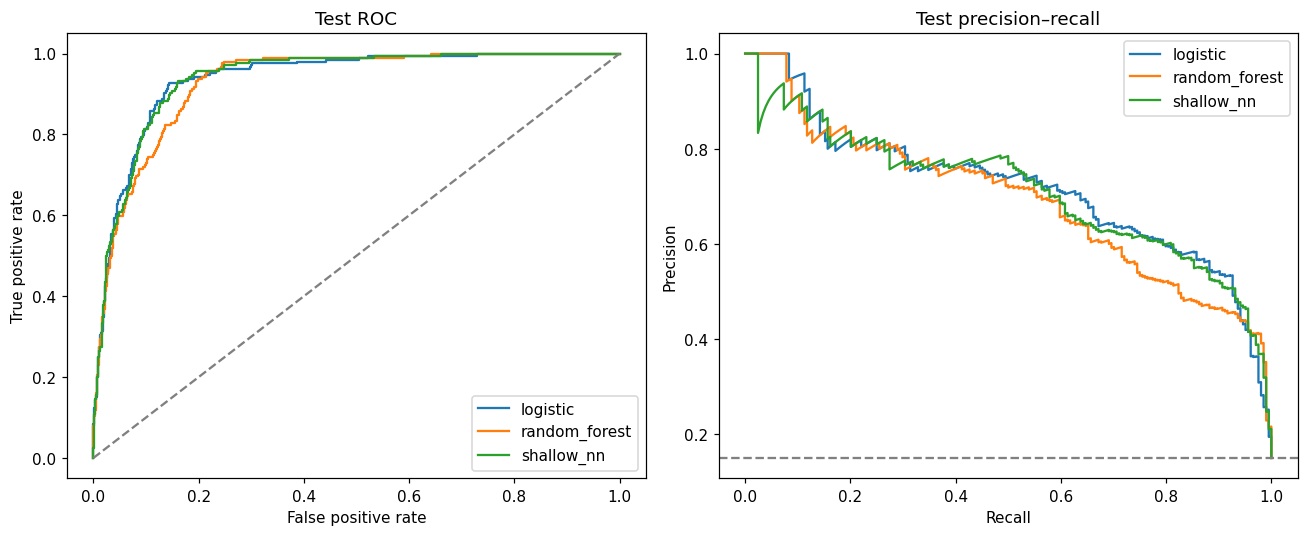

In [79]:
final_score_rows = []
prediction_rows = []
with threadpool_limits(limits=1):
    for name, model in models.items():
        probabilities[name, 'test'] = model.predict_proba(X['test'])[:, 1]
        for split, rows in splits.items():
            probability = probabilities[name, split]
            final_score_rows.append({'model': name, 'split': split,
                'selected_before_test': name == 'logistic', **metrics(y[split], probability)})
            frame = rows[KEYS + ['year', 'race_date', 'podium']].copy()
            frame['model'], frame['split'], frame['probability'] = name, split, probability
            frame['predicted_podium'] = (probability >= THRESHOLD).astype(int)
            prediction_rows.append(frame)
final_scores = pd.DataFrame(final_score_rows)
final_predictions = pd.concat(prediction_rows, ignore_index=True)
display(final_scores[['model', 'split', 'average_precision', 'pr_auc_trapezoidal', 'roc_auc', 'f1', 'precision', 'recall']])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in models:
    probability = probabilities[name, 'test']
    fpr, tpr, _ = roc_curve(y['test'], probability)
    precision, recall, _ = precision_recall_curve(y['test'], probability)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[1].axhline(y['test'].mean(), linestyle='--', color='gray')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Test ROC')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Test precision–recall')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

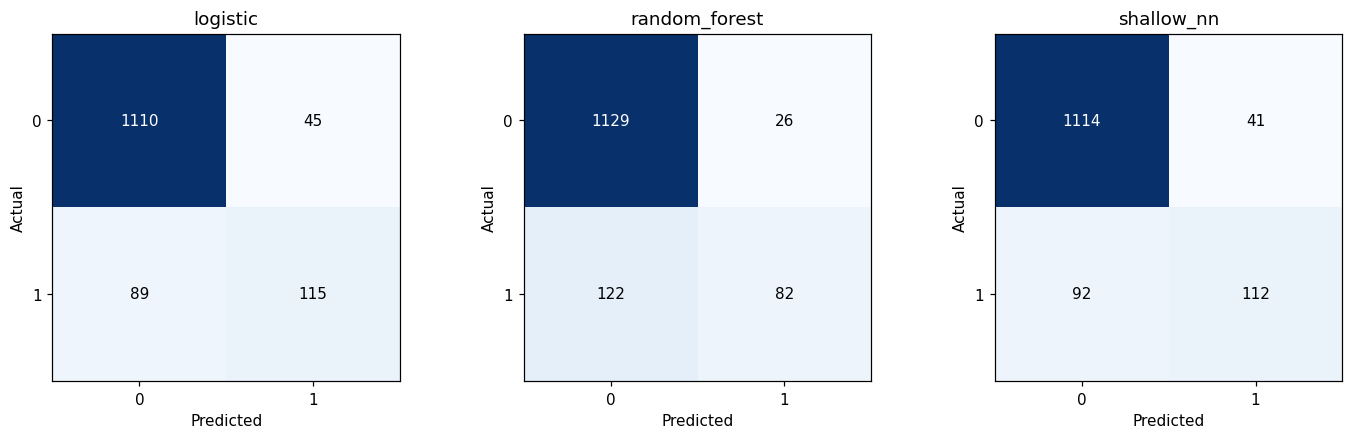

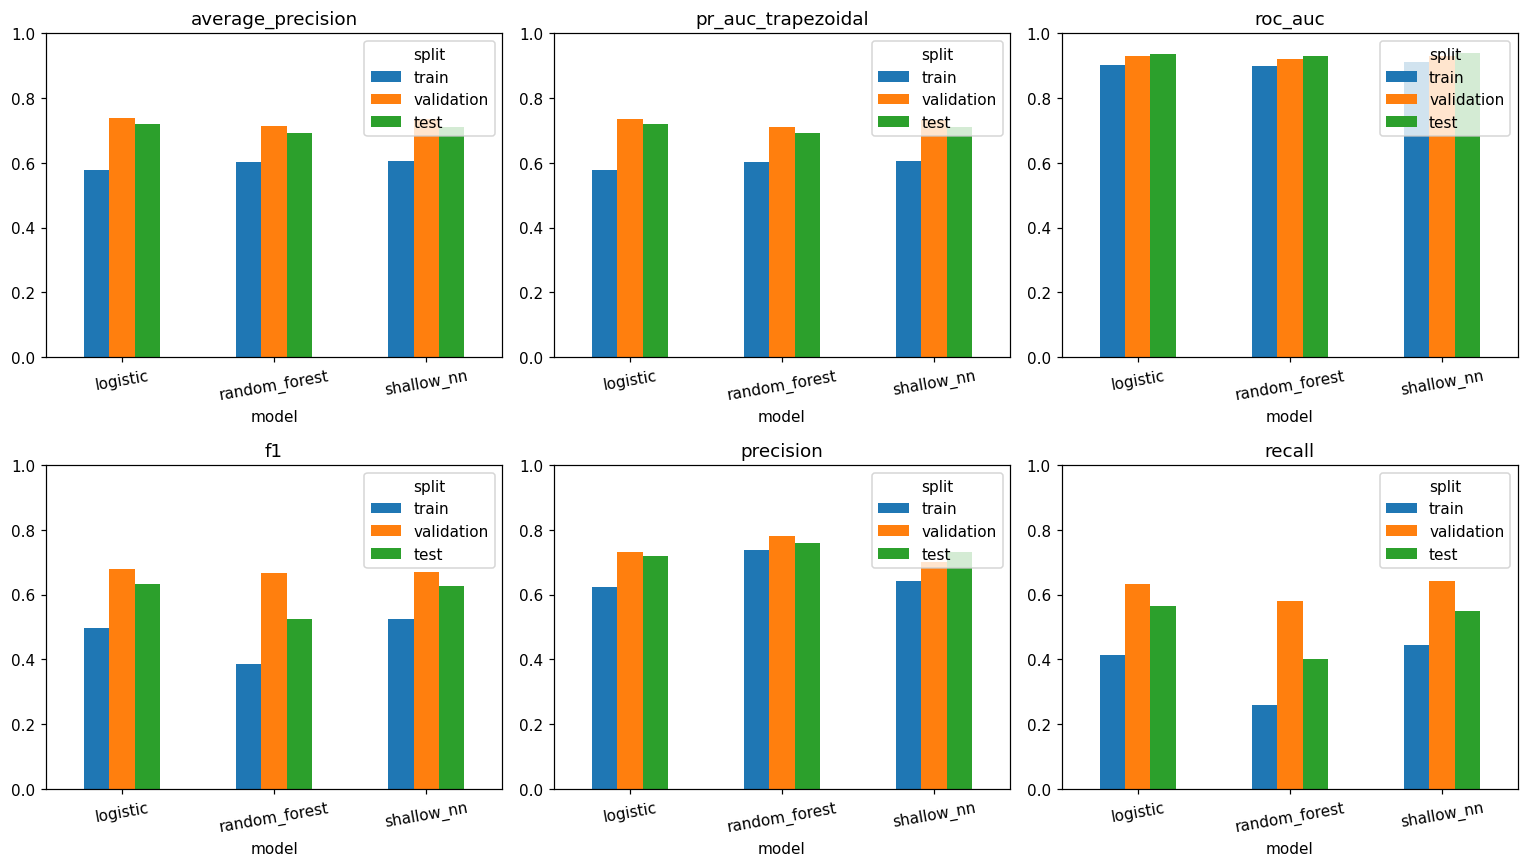

           model  year  average_precision        f1  precision    recall
0       logistic  2022           0.686564  0.606557   0.660714  0.560606
1       logistic  2023           0.766192  0.648148   0.833333  0.530303
2       logistic  2024           0.685786  0.641791   0.693548  0.597222
3  random_forest  2022           0.678027  0.538462   0.736842  0.424242
4  random_forest  2023           0.759116  0.547368   0.896552  0.393939
5  random_forest  2024           0.623926  0.495575   0.682927  0.388889
6     shallow_nn  2022           0.695596  0.605042   0.679245  0.545455
7     shallow_nn  2023           0.767422  0.660377   0.875000  0.530303
8     shallow_nn  2024           0.651160  0.621212   0.683333  0.569444


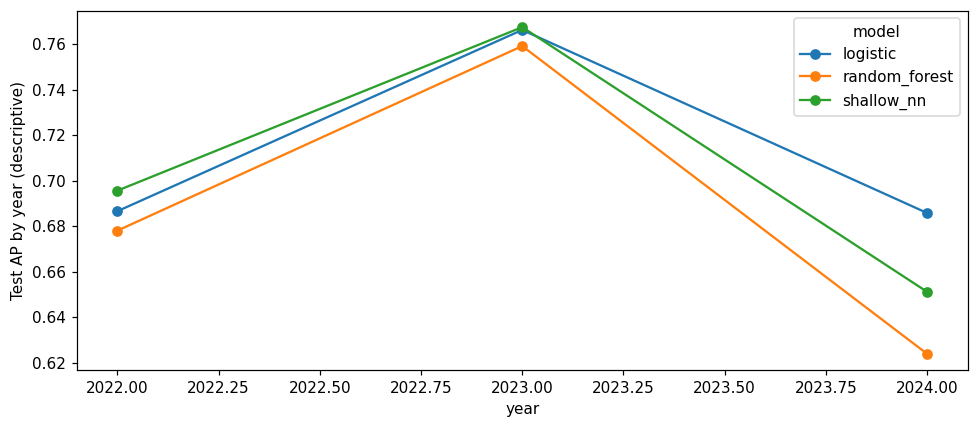

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, models):
    matrix = confusion_matrix(y['test'], probabilities[name, 'test'] >= THRESHOLD, labels=[0, 1])
    ax.imshow(matrix, cmap='Blues')
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, str(value), ha='center', va='center',
            color='white' if value > matrix.max() / 2 else 'black')
    ax.set(xticks=[0, 1], yticks=[0, 1], xlabel='Predicted', ylabel='Actual', title=name)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, metric in zip(axes.ravel(), ['average_precision', 'pr_auc_trapezoidal', 'roc_auc', 'f1', 'precision', 'recall']):
    final_scores.pivot(index='model',
        columns='split',
        values=metric)[['train',
        'validation',
        'test']].plot.bar(ax=ax,
        rot=10)
    ax.set(title=metric, ylim=(0, 1))
plt.tight_layout()
plt.show()
year_scores = []
for name in models:
    for year in [2022, 2023, 2024]:
        mask = splits['test'].year.eq(year).to_numpy()
        year_scores.append({'model': name, 'year': year,
            **metrics(y['test'][mask], probabilities[name, 'test'][mask])})
year_scores = pd.DataFrame(year_scores)
display(year_scores[['model', 'year', 'average_precision', 'f1', 'precision', 'recall']])
year_scores.pivot(index='year', columns='model', values='average_precision').plot(marker='o', figsize=(9, 4))
plt.ylabel('Test AP by year (descriptive)')
plt.tight_layout()
plt.show()

**Observed final results:** the preselected logistic model scores test **AP 0.720**, **F1 0.632**, ROC-AUC 0.938. At threshold 0.5 it predicts 160 podiums: **115 correct, 45 false alarms, and 89 podiums missed** (precision 71.9%, recall 56.4%). All three models have lower test AP and F1 than validation, while ROC-AUC increases for all three (logistic AP 0.738 → 0.720) with the same podium prevalence (15.0%), which documents both retained ranking performance and some degradation on the new seasons; it is not a proof of unchanged performance. The forest again trades recall for precision; the NN has the highest test ROC-AUC (0.939) but lower AP and F1. Year by year, logistic test AP is 0.687 (2022), 0.766 (2023) and 0.686 (2024). These point estimates do not establish statistical superiority of one model.

### Limitations
- **Qualifying-coverage drift:** qualifying is absent before 1994 and patchy until 2003, so the meaning of "qualifying Unknown" changes over time; the model learns this from the 1950–2019 mix.
- **Era sensitivity:** regulations, field sizes and reliability changed a lot; training covers 70 years while the held-out period is 2020–2024.
- **Retrospective data:** grid and qualifying come from final published results, not time-stamped pre-race snapshots; standings use the latest available earlier-GP snapshot for the same entity and season. Such snapshots can already include earlier sprint points; current-weekend or intervening sprint updates are not reconstructed, and a snapshot can be older than the immediately preceding GP.
- **Unused information:** sprint results, practice sessions and raw lap times are not used.
- **Small held-out sets:** 39 validation and 68 test races — the reported validation AP intervals cross zero. No test-performance bootstrap comparison is reported.
- **Fixed choices:** one NN architecture and seed, fixed threshold 0.5, untuned forest; validation influenced development decisions.
- **XAI is not causal:** neither explanations nor the home-country comparison establish cause and effect.

## 14. Essential checks and saved results
Row counts, finite matrices, binary encodings, no train/held-out overlap, exact SHAP reconstruction, complete-record inference and unchanged raw files are verified below. Final tables are exported to `output/simplified_results`.

In [81]:
# Source integrity, exact grain and chronological separation.
assert key_audit.missing_key_rows.eq(0).all()
assert key_audit.duplicate_excess_rows.eq(0).all()
assert fk_audit.orphan_rows.eq(0).all()
assert not data.duplicated(KEYS).any()
for first, second in combinations(['train', 'validation', 'test'], 2):
    assert set(splits[first].raceId).isdisjoint(set(splits[second].raceId))
    assert set(map(tuple, splits[first][KEYS].to_numpy())).isdisjoint(
        set(map(tuple, splits[second][KEYS].to_numpy())))
assert splits['train'].race_date.max() < splits['validation'].race_date.min()
assert splits['validation'].race_date.max() < splits['test'].race_date.min()
assert set(INPUT_COLUMNS).isdisjoint({'podium', 'positionOrder', 'statusId', 'laps', 'points'})

for split, matrix in X.items():
    assert np.isfinite(matrix).all()
    binary = ~schema.output_column.isin(NUMERIC_COLUMNS).to_numpy()
    assert np.isin(matrix[:, binary], [0, 1]).all()
assert len(set(map(tuple, splits['train'][KEYS].to_numpy())) & set(map(tuple, splits['validation'][KEYS].to_numpy()))) == 0
assert len(set(map(tuple, splits['train'][KEYS].to_numpy())) & set(map(tuple, splits['test'][KEYS].to_numpy()))) == 0
assert np.allclose(expit(base_score + group_shap.sum(axis=1)), probabilities['logistic', 'validation'], atol=1e-12, rtol=0)
complete_key = complete_rows.iloc[0][KEYS]
complete_position = np.flatnonzero((splits['validation'].raceId.to_numpy() == complete_key.raceId) &
    (splits['validation'].driverId.to_numpy() == complete_key.driverId))[0]
assert np.isclose(complete_prediction['podium_probability'],
    probabilities['logistic',
    'validation'][complete_position],
    atol=1e-12,
    rtol=0)
assert partial_record['qualifying_record_present'] == complete_record['qualifying_record_present']
assert all(sha256(path) == hashes_before[name] for name, path in FILES.items())

result_dir = Path('output/simplified_results')
result_dir.mkdir(parents=True, exist_ok=True)
for name, table in {'final_metrics': final_scores, 'final_predictions': final_predictions,
    'validation_windows': window_scores, 'validation_window_years': window_year_scores,
    'window_pairwise_intervals': window_pairwise_intervals,
    'population_rule_summary': population_rule_summary,
    'status_cause_crosswalk': q3_cause_crosswalk,
    'zero_lap_participation_evidence': q3_participation_evidence,
    'order_scaling_audit': order_scaling_audit,
    'order_indicator_audit': order_indicator_audit,
    'order_raw_fill_audit': order_raw_fill_audit,
    'availability_by_split': availability_by_split,
    'inference_error_checks': pd.DataFrame(inference_error_checks), 'constant_reference': pd.DataFrame(constant_reference_scores), 'feature_group_ablations': ablation_scores,
    'preprocessing_order_experiments': order_scores, 'validation_AP_intervals': comparison_intervals,
    'permutation_importance': permutation_summary, 'SHAP_group_importance': shap_ranking,
    'test_year_metrics': year_scores, 'q1_circuit_rates': q1_overall,
    'q1_era_rates': q1_era, 'q1_bootstrap': q1_bootstrap,
    'q2_home_away_summary': q2_summary, 'q3_constructor_era_rates': q3_constructor_results}.items():
    table.to_csv(result_dir / (name + '.csv'), index=False)
np.savez_compressed(result_dir / 'reproduction_arrays.npz',
    **{split + '_X': matrix for split, matrix in X.items()},
    raw_inputs=data[INPUT_COLUMNS].to_numpy(dtype=float),
    inference_validation_probabilities=inference_validation_probabilities,
    coefficient=coefficient, intercept=intercept, shap_values=shap_values,
    group_shap=group_shap, source_shap=source_shap, background=background,
    lime_coefficients=surrogate['coefficients'], lime_probability=lime_probability,
    nn_weight_0=neural_model.coefs_[0], nn_weight_1=neural_model.coefs_[1],
    nn_bias_0=neural_model.intercepts_[0], nn_bias_1=neural_model.intercepts_[1],
    complete_probability=complete_prediction['podium_probability'],
    partial_probability=partial_prediction['podium_probability'], best_epoch=best_epoch,
    **{'window_' + str(start): value for start, value in window_predictions.items()},
    **{'ablation_' + group: value for group, value in ablation_probabilities.items()},
    **{'order_' + name: value for name, value in order_predictions.items()})
print('Essential checks passed. Final tables saved to', result_dir)

Essential checks passed. Final tables saved to output/simplified_results


## Reproducibility and requirement coverage

Run from the fourteen original CSVs with the pinned environment. Intermediate analysis stays in memory; final tables are exported to `output/simplified_results`. The small `reference_precision` function reproduces the CSV numeric parsing at the feature-table boundaries so numerical optimization receives the same values as the complete development pipeline. It does not load saved models or previous results. CPU runtime varies by machine; actual Kaggle-hosted execution must still be checked after import.

| Assignment requirement | Evidence in this notebook |
|---|---|
| EDA before and after cleaning, with plots | Sections 1–2: missingness, keys/FKs, repeated pairs, coverage, grid/target, units, distributions |
| Immutable raw files; typed sentinels/dates/durations; unique driver–race grain | Section 2 transformations and source-result mapping; Section 14 integrity/uniqueness assertions |
| All three data-engineering answers, joins, grain, missingness and figures | Sections 3–5, including source-slot sensitivity, grid-standardized home rates and cause/start audits |
| Feature choices with exploratory evidence; past-only features | Section 6 input/cutoff table, source-marker audit, training-only response plots/correlations and leakage perturbation test |
| Train/validation/test split and training-only preprocessing | Section 7; season boundaries, fitted medians/encoding/scaling and distribution/availability audits |
| Statistical baseline, another statistical model and shallow NN | Section 8: logistic regression, random forest and 184 → 32 → 1 MLP on the same main matrices |
| Required metrics on train, validation and test; primary/secondary justification | Sections 8 and 13: AP, trapezoidal PR-AUC, ROC-AUC, F1, precision, recall, comparison plots and confusion matrices |
| Feature-group ablation and at least two order experiments | Section 9: eight independently retrained ablations, two order variants, value/indicator audits and paired whole-race uncertainty |
| Global permutation and SHAP; local LIME/SHAP; plots and interpretation | Sections 10–11; exact linear log-odds SHAP and explicitly defined grouped LIME, with fidelity and noncausal limitations |
| Complete and partially missing inference records | Section 12; actual outputs, handling audit, all-validation agreement and invalid-input tests |
| Limitations and code/statistic/plot support for conclusions | Relevant sections and final evaluation limitations; descriptive claims are separated from causal/inferential claims |
| Analytical PDF report containing answers and figures | Separate submission item — not supplied or verified by this notebook |
| Accessible Kaggle notebook and GitHub repository | External submission items — accessibility and hosted execution must be verified separately |

No claim of a superior encoding, optimal hyperparameters or a causal race effect is made. Some decisions are explicit domain/operational definitions (nationality mapping and recorded status categories); their coverage and consequences are inspected in code. Ambiguous source facts remain documented rather than being declared resolved without evidence.

### Checks reproduced by this notebook

The executable checks above verify raw-file integrity, primary/foreign keys, unique driver–race rows, chronological split separation, finite transformed inputs and binary encodings. The history/standings perturbation tests verify that the tested current/future changes do not affect inputs at or before the perturbed race. These checks cover the specified transformations; they do not independently reconstruct the real-world timing of every source field.

The SHAP reconstruction assertions reproduce the fixed model's validation probabilities. Section 12 reproduces all 780 validation probabilities through `predict_podium` within the stated tolerance and shows nine rejected invalid-input cases. These are implementation-consistency checks, not independent evidence of predictive generalization.

Actual Kaggle-hosted execution and external submission links remain to be checked. The separate analytical PDF report must contain the required answers and figures; it is not supplied by this notebook.
